## Import TensorFlow and other libraries

In [ ]:
# Initialisation : rend le paquet `src` importable quel que soit le dossier de lancement
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents] if (p / "src").is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import src
from src.utils.paths import (
    ANOMALY_MODELS_DIR,
    CHECKPOINTS_DIR,
    DATASET_ANOMALIES,
    DATASET_PUBLIC,
    FIGURES_DIR,
    TEST_DIR,
)


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing.image import ImageDataGenerator

In [2]:
df = src.Load_data.load_object(DATASET_PUBLIC)

In [3]:
df.reshape(target_shape=(64,64,3), batch_size = 32)

Reshape en batch: 100%|██████████| 380/380 [00:23<00:00, 16.16it/s]


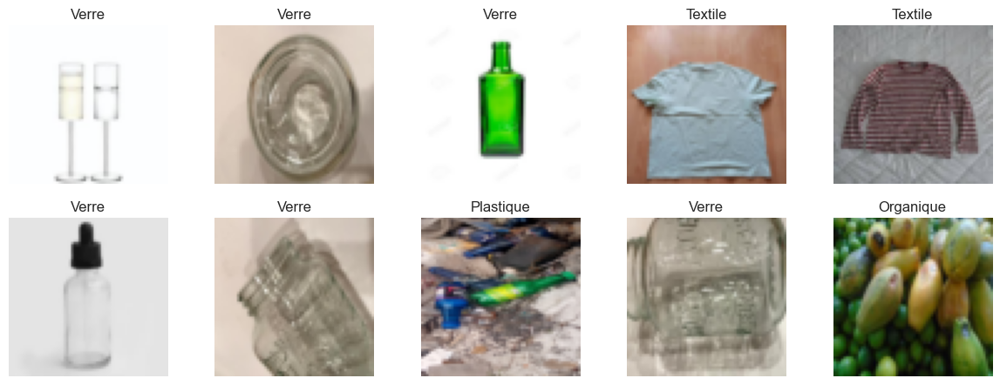

In [4]:
df.plot()

In [5]:
df.encodage()

In [6]:
(X_train, _), (X_test, _ ) = df.create_data(test_size=0.1)

In [7]:
print(f"X_train shape : {X_train.shape}")
print(f"X_test  shape : {X_test.shape}")

X_train shape : (10924, 64, 64, 3)
X_test  shape : (1214, 64, 64, 3)


In [8]:
X_vis = X_test[0:10]

In [9]:
X_vis = X_vis.astype("float32") / 255.

In [10]:
train_datagen = ImageDataGenerator(
    rotation_range=20,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.1,
    horizontal_flip=True,
    brightness_range=[0.9, 1.1],
    fill_mode='nearest',
    rescale=1./255
)


test_datagen =  ImageDataGenerator(rescale= 1. / 255)

In [11]:
train_generator = train_datagen.flow(X_train,X_train,batch_size=64)
test_generator  = test_datagen.flow(X_test,X_test,batch_size=64)

In [ ]:
#noise_adder = src.NoiseAdder(X_train)

In [ ]:
#noisy_gaussian = noise_adder.apply("gaussian", std=0.2)

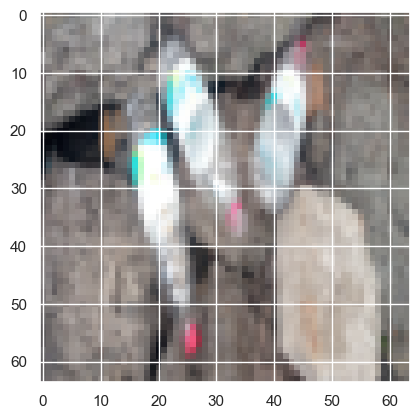

In [12]:
plt.imshow(X_test[8])

In [28]:
X_train = X_train.astype("float32") / 255.

In [26]:
X_test = X_test.astype("float32") / 255.

In [29]:
print(f"min = {np.min(X_test)} et max = {np.max(X_test)}")

min = 0.0 et max = 1.0


In [30]:
print(f"min = {np.min(X_train)} et max = {np.max(X_train)}")

min = 0.0 et max = 1.0


In [ ]:
plt.figure(figsize=(18,9))
for i in range(1,11):
    plt.subplot(4,5,i)
    plt.imshow(X_train[i])
    plt.title(y_train[i])
    plt.tight_layout()
plt.show()

In [13]:
import os 
import numpy as np
import json
import tensorflow as tf 
from tensorflow.keras import layers, models, losses, callbacks, regularizers
from sklearn.metrics import mean_squared_error
from tensorflow.keras.optimizers import Adam, SGD, RMSprop
from tensorflow.keras.optimizers.schedules import ExponentialDecay
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import LearningRateScheduler,ModelCheckpoint,ReduceLROnPlateau

In [14]:
from keras.saving import register_keras_serializable

In [ ]:
def ResidualBlock(filters, stride=1, use_bn=False, l2=1e-4):
    def f(x):
        shortcut = x
        y = layers.Conv2D(filters, 3, strides=stride, padding="same",
                          kernel_regularizer=tf.keras.regularizers.l2(l2), use_bias=not use_bn)(x)
        if use_bn: y = layers.BatchNormalization()(y)
        y = layers.Activation("relu")(y)

        y = layers.Conv2D(filters, 3, padding="same",
                          kernel_regularizer=tf.keras.regularizers.l2(l2), use_bias=not use_bn)(y)
        if use_bn: y = layers.BatchNormalization()(y)

        # Adapter raccourci
        if shortcut.shape[-1] != filters or stride != 1:
            shortcut = layers.Conv2D(filters, 1, strides=stride, padding="same",
                                     kernel_regularizer=tf.keras.regularizers.l2(l2),
                                     use_bias=not use_bn)(shortcut)
            if use_bn: shortcut = layers.BatchNormalization()(shortcut)

        out = layers.Add()([y, shortcut])
        out = layers.Activation("relu")(out)
        return out
    return f


# -----------------------------
# Bloc résiduel upsampling
# -----------------------------
def ResidualBlockUp(filters, scale=2, use_bn=False, l2=1e-4):
    def f(x):
        shortcut = x
        y = layers.UpSampling2D(size=(scale, scale))(x)
        y = layers.Conv2D(filters, 3, padding="same",
                          kernel_regularizer=tf.keras.regularizers.l2(l2), use_bias=not use_bn)(y)
        if use_bn: y = layers.BatchNormalization()(y)
        y = layers.Activation("relu")(y)

        y = layers.Conv2D(filters, 3, padding="same",
                          kernel_regularizer=tf.keras.regularizers.l2(l2), use_bias=not use_bn)(y)
        if use_bn: y = layers.BatchNormalization()(y)

        shortcut = layers.UpSampling2D(size=(scale, scale))(shortcut)
        shortcut = layers.Conv2D(filters, 1, padding="same",
                                 kernel_regularizer=tf.keras.regularizers.l2(l2),
                                 use_bias=not use_bn)(shortcut)
        if use_bn: shortcut = layers.BatchNormalization()(shortcut)

        out = layers.Add()([y, shortcut])
        out = layers.Activation("relu")(out)
        return out
    return f


# -----------------------------
# Échantillonnage
# -----------------------------
@register_keras_serializable()
class Sampling(layers.Layer):
    def call(self, inputs):
        z_mean, z_logvar = inputs
        eps = tf.random.normal(shape=tf.shape(z_mean))
        return z_mean + tf.exp(0.5 * z_logvar) * eps


# -----------------------------
def build_encoder(input_shape=(240, 240, 3), latent_dim=128, base=32):
    inp = layers.Input(shape=input_shape)
    x = inp

    # downsampling avec blocs résiduels
    x = layers.Conv2D(base, 3, padding="same")(x)
    x = layers.Activation("relu")(x)

    x = ResidualBlock(base,   stride=1)(x)  # HxW
    x = ResidualBlock(base*2, stride=2)(x)  # H/2 x W/2
    x = ResidualBlock(base*2, stride=1)(x)
    x = ResidualBlock(base*4, stride=2)(x)  # H/4 x W/4
    x = ResidualBlock(base*4, stride=1)(x)
    x = ResidualBlock(base*8, stride=2)(x)  # H/8 x W/8
    x = ResidualBlock(base*8, stride=1)(x)

    x = layers.GlobalAveragePooling2D()(x)
    
    # PAS de Dense intermédiaire !
    z_mean   = layers.Dense(latent_dim, name="z_mean")(x)
    z_logvar = layers.Dense(latent_dim, name="z_logvar")(x)
    z = Sampling()([z_mean, z_logvar])

    return tf.keras.Model(inp, [z_mean, z_logvar, z], name="encoder")


def build_predictor(latent_dim=128):
    inp = layers.Input(shape=(latent_dim,))
    x = layers.Dense(256, activation="relu")(inp)
    x = layers.Dense(256, activation="relu")(x)
    out = layers.Dense(latent_dim)(x)
    return tf.keras.Model(inp, out, name="predictor")


def build_decoder(output_shape=(240, 240, 3), latent_dim=128, base=32):
    H, W, C = output_shape
    h0, w0 = H // 8, W // 8
    
    inp = layers.Input(shape=(latent_dim,))
    x = layers.Dense(h0 * w0 * base*8, activation="relu")(inp)
    x = layers.Reshape((h0, w0, base*8))(x)

    x = ResidualBlock(base*8, stride=1)(x)
    x = ResidualBlockUp(base*4)(x)
    x = ResidualBlock(base*4, stride=1)(x)
    x = ResidualBlockUp(base*2)(x)
    x = ResidualBlock(base*2, stride=1)(x)
    x = ResidualBlockUp(base)(x)
    x = ResidualBlock(base, stride=1)(x)

    # IMPORTANT: Pas d'activation sigmoid ici (on veut des logits)
    out = layers.Conv2D(C, 3, padding="same")(x)  # Pas d'activation !
    return tf.keras.Model(inp, out, name="decoder")


# -----------------------------
# Callback pour affichage reconstruction
# -----------------------------
class PlotReconstructionCallback(tf.keras.callbacks.Callback):
    def __init__(self, model, x_vis):
        super().__init__()
        self.vae_model = model
        self.x_vis = x_vis.astype("float32")
        
        # Si les images sont en [0,255], normaliser
        if self.x_vis.max() > 1.0:
            self.x_vis = self.x_vis / 255.0

    def on_epoch_end(self, epoch, logs=None):
        # Inférence
        mean, logvar = self.vae_model.encode(self.x_vis)
        z = self.vae_model.reparameterize(mean, logvar)
        recon_logits = self.vae_model.decode(z)
        recon = tf.nn.sigmoid(recon_logits)  # Application de sigmoid pour visualisation
        
        n = min(5, len(self.x_vis))
        plt.figure(figsize=(20, 8))
        for i in range(n):
            # Original
            plt.subplot(2, n, i + 1)
            plt.imshow(np.clip(self.x_vis[i], 0, 1))
            plt.axis("off")
            plt.title("Original")

            # Reconstruit
            plt.subplot(2, n, n + i + 1)
            plt.imshow(np.clip(recon[i], 0, 1))
            plt.axis("off")
            plt.title(f"Reconstruit (KL: {logs.get('kl_loss', 0):.1f})")
        
        plt.suptitle(f"Époque {epoch + 1}")
        plt.tight_layout()
        plt.show()

class SaveHistoryCallback(tf.keras.callbacks.Callback):
    def __init__(self, save_dir=str(CHECKPOINTS_DIR)):
        super().__init__()
        self.save_dir = save_dir
        os.makedirs(save_dir, exist_ok=True)
        self.history = {}

    def on_epoch_end(self, epoch, logs=None):
        logs = logs or {}
        # Mettre à jour l'historique
        for k, v in logs.items():
            self.history.setdefault(k, []).append(float(v))

        # Sauvegarde de l’historique JSON
        history_path = os.path.join(self.save_dir, "history.json")
        with open(history_path, "w") as f:
            json.dump(self.history, f)

        # Sauvegarde de l'époque actuelle
        epoch_path = os.path.join(self.save_dir, "epoch.txt")
        with open(epoch_path, "w") as f:
            f.write(str(epoch + 1))  # +1 car epoch commence à 0


@register_keras_serializable()
class ResidualVAE(tf.keras.Model):
    def __init__(
        self, 
        encoder, 
        decoder, 
        beta=0.001,
        add_noise=True,          # <-- activer/désactiver le bruit
        noise_std=0.2,           # <-- intensité du bruit gaussien
        dropout_rate=0.0,        # <-- dropout aléatoire optionnel
        **kwargs
    ):
        super().__init__(**kwargs)
        self.encoder = encoder
        self.decoder = decoder
        self.beta = beta

        self.add_noise = add_noise
        self.noise_std = noise_std
        self.dropout_rate = dropout_rate

        self.total_loss_tracker = tf.keras.metrics.Mean(name="loss")
        self.recon_loss_tracker = tf.keras.metrics.Mean(name="recon_loss")
        self.kl_loss_tracker = tf.keras.metrics.Mean(name="kl_loss")

        self.log2pi = tf.math.log(2. * np.pi)


    # Pour la sérialisation Keras
    def get_config(self):
        config = super().get_config()
        config.update({
            "beta": self.beta,
            "add_noise": self.add_noise,
            "noise_std": self.noise_std,
            "dropout_rate": self.dropout_rate,
            "encoder": tf.keras.utils.serialize_keras_object(self.encoder),
            "decoder": tf.keras.utils.serialize_keras_object(self.decoder),
        })
        return config

    @classmethod
    def from_config(cls, config):
        encoder = tf.keras.utils.deserialize_keras_object(config.pop("encoder"))
        decoder = tf.keras.utils.deserialize_keras_object(config.pop("decoder"))
        return cls(encoder=encoder, decoder=decoder, **config)


    @property
    def metrics(self):
        return [
            self.total_loss_tracker,
            self.recon_loss_tracker,
            self.kl_loss_tracker,
        ]

    
    def encode(self, x):
        z_mean, z_logvar, _ = self.encoder(x, training=True)
        return z_mean, z_logvar
    
    def reparameterize(self, mean, logvar):
        eps = tf.random.normal(shape=tf.shape(mean))
        return mean + tf.exp(0.5 * logvar) * eps
    
    def decode(self, z):
        return self.decoder(z, training=True)
    
    def log_normal_pdf(self, sample, mean, logvar, raxis=1):
        return tf.reduce_sum(
            -.5 * ((sample - mean) ** 2. * tf.exp(-logvar) + logvar + self.log2pi),
            axis=raxis
        )

    def compute_loss(self, x_train, x_val=None):
        mean, logvar = self.encode(x_train)
        z = self.reparameterize(mean, logvar)
        x_logit = self.decode(z)  
        cross_ent = tf.nn.sigmoid_cross_entropy_with_logits(logits=x_logit, labels=x_val)
        logpx_z = -tf.reduce_sum(cross_ent, axis=[1, 2, 3])
        logpz = self.log_normal_pdf(z, 0., 0.)  
        logqz_x = self.log_normal_pdf(z, mean, logvar)
        kl_loss = logqz_x - logpz
        total_loss = -tf.reduce_mean(logpx_z - self.beta * kl_loss)
        recon_loss = -tf.reduce_mean(logpx_z)
        mean_kl = tf.reduce_mean(kl_loss)
        
        return total_loss, recon_loss, mean_kl
    # ------------------------
    # Fonction pour ajouter du bruit
    # ------------------------
    def add_training_noise(self, x):
        if not self.add_noise:
            return x

        # Bruit gaussien
        x_noisy = x + tf.random.normal(
            shape=tf.shape(x),
            mean=0.0,
            stddev=self.noise_std
        )

        # Dropout (optionnel)
        if self.dropout_rate > 0.0:
            x_noisy = tf.nn.dropout(x_noisy, rate=self.dropout_rate)

        # Clamp entre 0–1
        x_noisy = tf.clip_by_value(x_noisy, 0.0, 1.0)

        return x_noisy


    # ------------------------
    # TRAIN STEP MODIFIÉ
    # ------------------------
    def train_step(self, data):
        if isinstance(data, (tuple, list)):
            x_train = data[0]
            x_val = tf.cast(data[1], tf.float32)if len(data) > 1 else None

        else:
            x_train = data
            x_val = data
        
        x_noisy = self.add_training_noise(x_train)
        
        with tf.GradientTape() as tape:
            total_loss, recon_loss, kl_loss = self.compute_loss(x_noisy, x_val=x_val)
        
        gradients = tape.gradient(total_loss, self.trainable_variables)
        self.optimizer.apply_gradients(zip(gradients, self.trainable_variables))

         # Mise à jour des métriques
        self.total_loss_tracker.update_state(total_loss)
        self.recon_loss_tracker.update_state(recon_loss)
        self.kl_loss_tracker.update_state(kl_loss)
        
        return {
            "loss": self.total_loss_tracker.result(),
            "recon_loss": self.recon_loss_tracker.result(),
            "kl_loss": self.kl_loss_tracker.result(),
        }
    # ------------------------
    # TEST STEP (sans bruit)
    # ------------------------
    def test_step(self, data):
        
        if isinstance(data, (tuple, list)):
            x = data[0]
        else:
            x = data
        
        total_loss, recon_loss, kl_loss = self.compute_loss(x,x_val=x)
        
    
        self.total_loss_tracker.update_state(total_loss)
        self.recon_loss_tracker.update_state(recon_loss)
        self.kl_loss_tracker.update_state(kl_loss)
        
        return {
            "loss": self.total_loss_tracker.result(),
            "recon_loss": self.recon_loss_tracker.result(),
            "kl_loss": self.kl_loss_tracker.result(),
        }

    def call(self, x):
        
        mean, logvar = self.encode(x)
        z = self.reparameterize(mean, logvar)
        return self.decode(z)
    
    def train(
        self, x_train, x_val=None, batch_size=32, epochs=100, x_vis=None, save_path=str(ANOMALY_MODELS_DIR / "residual_vae.keras"),
         save_dir=str(CHECKPOINTS_DIR), initial_epoch=0,
    ):
        self.compile(optimizer=Adam(learning_rate=1e-3))

        callbacks_list = [
            SaveHistoryCallback(save_dir=save_dir),
            tf.keras.callbacks.EarlyStopping(
                monitor="val_loss", patience=80, restore_best_weights=True
            ),
            tf.keras.callbacks.ModelCheckpoint(save_path,monitor="val_recon_loss",verbose=1,save_best_only=True,mode="min"),
            tf.keras.callbacks.ReduceLROnPlateau(
                monitor="val_loss", factor=0.5, patience=10, verbose=1, min_lr=1e-7
            ),
        ]

        if x_vis is not None:
            callbacks_list.append(PlotReconstructionCallback(self, x_vis))

        history = self.fit(
            x_train,
            validation_data=x_val if x_val is not None else None,
            epochs=epochs,
            batch_size=batch_size,
            callbacks=callbacks_list,
            shuffle=True,
        )
        return history

In [31]:
input_shape = (64, 64, 3)   
latent_dim = 256

encoder = build_encoder(input_shape=input_shape, latent_dim=latent_dim, base=32)
decoder = build_decoder(output_shape=input_shape, latent_dim=latent_dim, base=32)

In [24]:
encoder.summary()

Model: "encoder"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 64, 64, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_36 (Conv2D)  │ (None, 64, 64,    │        896 │ input_layer_2[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_29       │ (None, 64, 64,    │          0 │ conv2d_36[0][0]   │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_37 (Conv2D)  │ (None, 64, 64,    │      9,248 │ activation_29[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_30       │ (None, 64, 64,    │          0 │ conv2d_37[0][0]   │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_38 (Conv2D)  │ (None, 64, 64,    │      9,248 │ activation_30[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_14 (Add)        │ (None, 64, 64,    │          0 │ conv2d_38[0][0],  │
│                     │ 32)               │            │ activation_29[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_31       │ (None, 64, 64,    │          0 │ add_14[0][0]      │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_39 (Conv2D)  │ (None, 32, 32,    │     18,496 │ activation_31[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_32       │ (None, 32, 32,    │          0 │ conv2d_39[0][0]   │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_40 (Conv2D)  │ (None, 32, 32,    │     36,928 │ activation_32[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_41 (Conv2D)  │ (None, 32, 32,    │      2,112 │ activation_31[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_15 (Add)        │ (None, 32, 32,    │          0 │ conv2d_40[0][0],  │
│                     │ 64)               │            │ conv2d_41[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_33       │ (None, 32, 32,    │          0 │ add_15[0][0]      │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_42 (Conv2D)  │ (None, 32, 32,    │     36,928 │ activation_33[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_34       │ (None, 32, 32,    │          0 │ conv2d_42[0][0]   │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_43 (Conv2D)  │ (None, 32, 32,    │     36,928 │ activation_34[0]

 Total params: 2,905,728 (11.08 MB)

 Trainable params: 2,905,728 (11.08 MB)

 Non-trainable params: 0 (0.00 B)

In [25]:
decoder.summary()

Model: "decoder"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_3       │ (None, 256)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 16384)     │  4,210,688 │ input_layer_3[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_1 (Reshape) │ (None, 8, 8, 256) │          0 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_54 (Conv2D)  │ (None, 8, 8, 256) │    590,080 │ reshape_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_44       │ (None, 8, 8, 256) │          0 │ conv2d_54[0][0]   │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_55 (Conv2D)  │ (None, 8, 8, 256) │    590,080 │ activation_44[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_21 (Add)        │ (None, 8, 8, 256) │          0 │ conv2d_55[0][0],  │
│                     │                   │            │ reshape_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_45       │ (None, 8, 8, 256) │          0 │ add_21[0][0]      │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling2d_6     │ (None, 16, 16,    │          0 │ activation_45[0]… │
│ (UpSampling2D)      │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_56 (Conv2D)  │ (None, 16, 16,    │    295,040 │ up_sampling2d_6[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_46       │ (None, 16, 16,    │          0 │ conv2d_56[0][0]   │
│ (Activation)        │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling2d_7     │ (None, 16, 16,    │          0 │ activation_45[0]… │
│ (UpSampling2D)      │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_57 (Conv2D)  │ (None, 16, 16,    │    147,584 │ activation_46[0]… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_58 (Conv2D)  │ (None, 16, 16,    │     32,896 │ up_sampling2d_7[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_22 (Add)        │ (None, 16, 16,    │          0 │ conv2d_57[0][0],  │
│                     │ 128)              │            │ conv2d_58[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_47       │ (None, 16, 16,    │          0 │ add_22[0][0]      │
│ (Activation)        │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_59 (Conv2D)  │ (None, 16, 16,    │    147,584 │ activation_47[0]… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_48       │ (None, 16, 16,    │          0 │ conv2d_59[0][0]   │
│ (Activation)        │ 128)              │            │                 

 Total params: 6,403,523 (24.43 MB)

 Trainable params: 6,403,523 (24.43 MB)

 Non-trainable params: 0 (0.00 B)

In [17]:
import matplotlib.pyplot as plt

def plot_result(history, metrics=None, name_fig="fig", register_plot=False):
    # Dictionnaire contenant toutes les métriques
    hist = history.history  

    # Si metrics n’est pas fourni, on prend toutes les clés
    if metrics is None:
        metrics = [m for m in hist.keys() if not m.startswith("val_")]

    n = len(metrics)
    fig, axes = plt.subplots(1, n, figsize=(6*n, 5))

    if n == 1:
        axes = [axes]  # uniformiser

    for i, metric in enumerate(metrics):
        ax = axes[i]
        ax.plot(hist[metric], label=f"Train {metric}")
        if f"val_{metric}" in hist:
            ax.plot(hist[f"val_{metric}"], label=f"Val {metric}")
        ax.set_title(metric.capitalize())
        ax.set_xlabel("Epochs")
        ax.set_ylabel(metric)
        ax.legend()
        ax.grid(True)

    plt.tight_layout()
    if register:
        plt.savefig(str(FIGURES_DIR / f"{name_fig}.png"))
    plt.show()

In [19]:
from tensorflow.keras.models import load_model

In [20]:
model1 = load_model(str(ANOMALY_MODELS_DIR / "model_dct_7.keras"), custom_objects={"ResidualVAE": ResidualVAE, "Sampling": Sampling})

C:\Users\hp\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\saving\saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'rmsprop', because it has 2 variables whereas the saved optimizer has 116 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


In [32]:
autoencoder = ResidualVAE(
    encoder,
    decoder,
    beta=0.01,  
    add_noise=True,  
    noise_std=0.05,   
    dropout_rate=0.05 
)

In [34]:
save_dir = str(CHECKPOINTS_DIR)

# Charger historique
history_path = os.path.join(save_dir, "history.json")
if os.path.exists(history_path):
    with open(history_path, "r") as f:
        history_old = json.load(f)
else:
    history_old = {}

# Charger epoch
epoch_path = os.path.join(save_dir, "epoch.txt")
if os.path.exists(epoch_path):
    with open(epoch_path, "r") as f:
        start_epoch = int(f.read())
else:
    start_epoch = 0


In [35]:
start_epoch

25

Epoch 1/175
683/683 ━━━━━━━━━━━━━━━━━━━━ 0s 660ms/step - kl_loss: 707.5834 - loss: 5822.3384 - recon_loss: 5815.2612
Epoch 1: val_recon_loss improved from None to 5981.75928, saving model to model_dct_10.keras


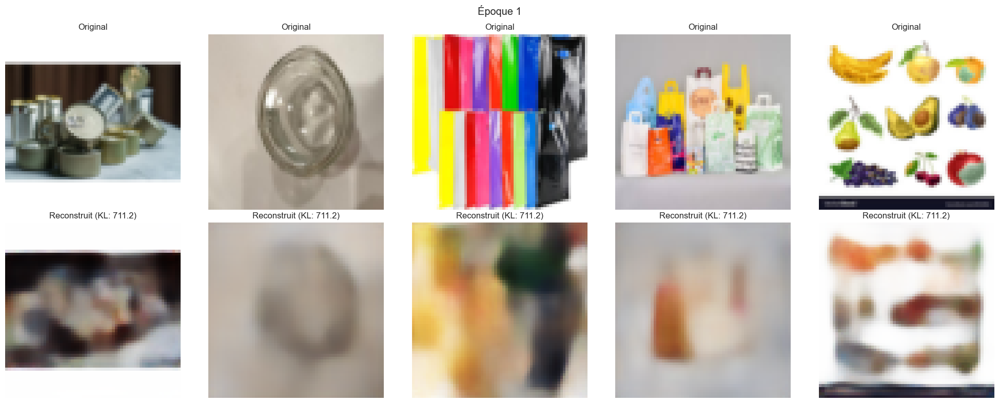

683/683 ━━━━━━━━━━━━━━━━━━━━ 487s 692ms/step - kl_loss: 711.2341 - loss: 5819.2915 - recon_loss: 5812.1772 - val_kl_loss: 684.2612 - val_loss: 5988.6006 - val_recon_loss: 5981.7593 - learning_rate: 0.0010
Epoch 2/175
683/683 ━━━━━━━━━━━━━━━━━━━━ 0s 666ms/step - kl_loss: 716.4761 - loss: 5807.6147 - recon_loss: 5800.4512
Epoch 2: val_recon_loss improved from 5981.75928 to 5969.26074, saving model to model_dct_10.keras


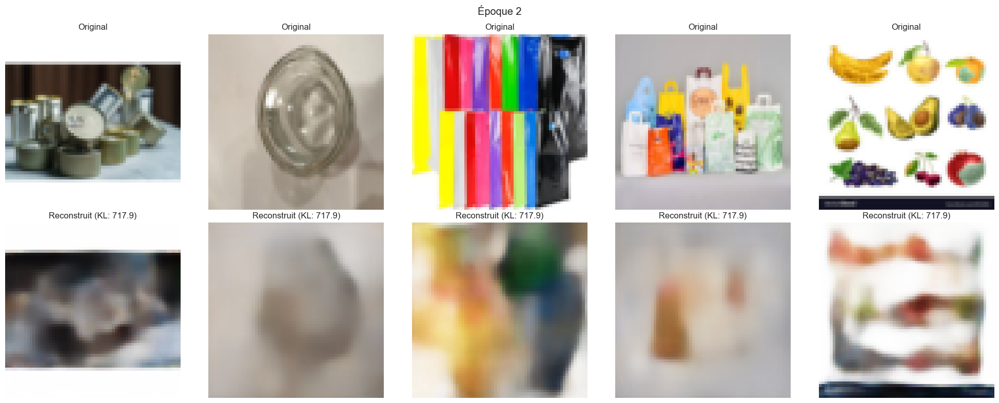

683/683 ━━━━━━━━━━━━━━━━━━━━ 472s 691ms/step - kl_loss: 717.8903 - loss: 5812.5996 - recon_loss: 5805.4263 - val_kl_loss: 704.2681 - val_loss: 5976.3032 - val_recon_loss: 5969.2607 - learning_rate: 0.0010
Epoch 3/175
683/683 ━━━━━━━━━━━━━━━━━━━━ 0s 637ms/step - kl_loss: 720.3221 - loss: 5768.3813 - recon_loss: 5761.1792
Epoch 3: val_recon_loss did not improve from 5969.26074


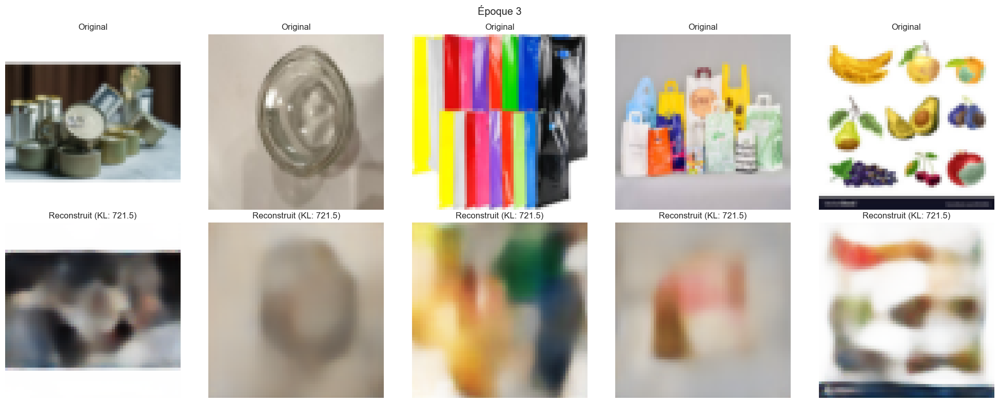

683/683 ━━━━━━━━━━━━━━━━━━━━ 451s 661ms/step - kl_loss: 721.5265 - loss: 5803.2925 - recon_loss: 5796.0786 - val_kl_loss: 705.6804 - val_loss: 5977.0659 - val_recon_loss: 5970.0078 - learning_rate: 0.0010
Epoch 4/175
683/683 ━━━━━━━━━━━━━━━━━━━━ 0s 638ms/step - kl_loss: 718.3677 - loss: 5785.7153 - recon_loss: 5778.5327
Epoch 4: val_recon_loss improved from 5969.26074 to 5961.22852, saving model to model_dct_10.keras


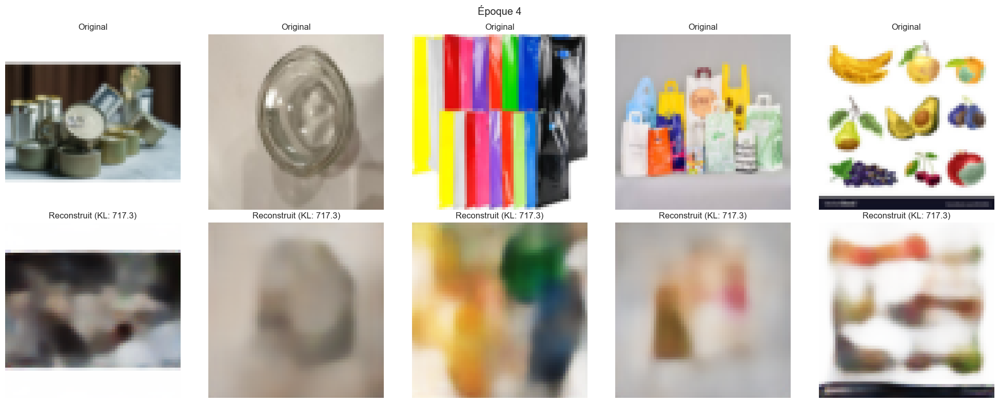

683/683 ━━━━━━━━━━━━━━━━━━━━ 453s 663ms/step - kl_loss: 717.2510 - loss: 5804.4731 - recon_loss: 5797.3008 - val_kl_loss: 747.9280 - val_loss: 5968.7095 - val_recon_loss: 5961.2285 - learning_rate: 0.0010
Epoch 5/175
683/683 ━━━━━━━━━━━━━━━━━━━━ 0s 643ms/step - kl_loss: 724.1544 - loss: 5795.9868 - recon_loss: 5788.7437
Epoch 5: val_recon_loss improved from 5961.22852 to 5957.71582, saving model to model_dct_10.keras


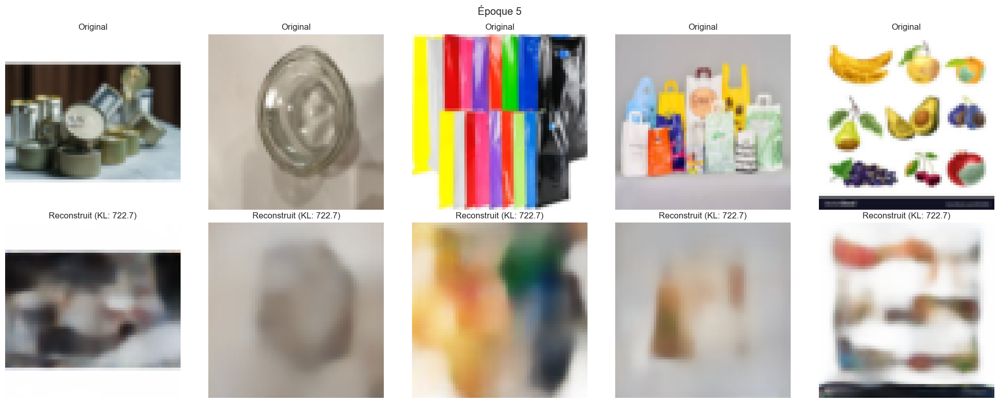

683/683 ━━━━━━━━━━━━━━━━━━━━ 457s 669ms/step - kl_loss: 722.7214 - loss: 5794.4097 - recon_loss: 5787.1772 - val_kl_loss: 703.6520 - val_loss: 5964.7520 - val_recon_loss: 5957.7158 - learning_rate: 0.0010
Epoch 6/175
683/683 ━━━━━━━━━━━━━━━━━━━━ 0s 648ms/step - kl_loss: 726.2718 - loss: 5772.2583 - recon_loss: 5764.9966
Epoch 6: val_recon_loss did not improve from 5957.71582


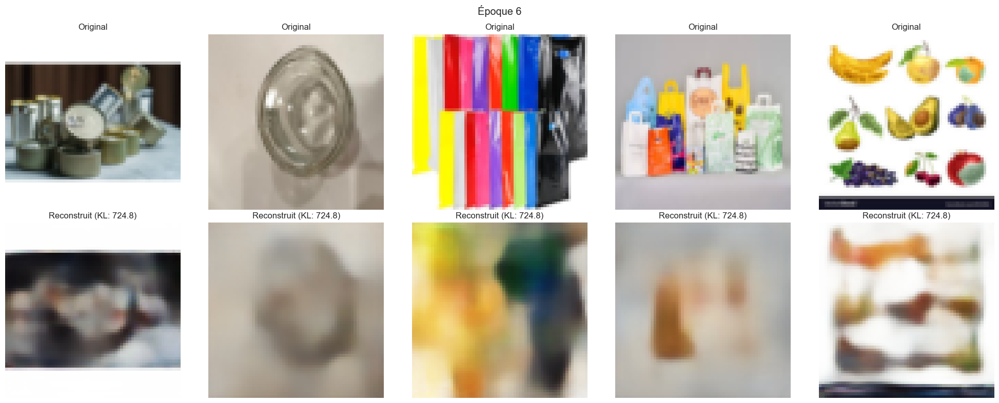

683/683 ━━━━━━━━━━━━━━━━━━━━ 460s 673ms/step - kl_loss: 724.8343 - loss: 5789.8193 - recon_loss: 5782.5708 - val_kl_loss: 690.7509 - val_loss: 5984.2168 - val_recon_loss: 5977.3076 - learning_rate: 0.0010
Epoch 7/175
683/683 ━━━━━━━━━━━━━━━━━━━━ 0s 655ms/step - kl_loss: 722.8994 - loss: 5772.7065 - recon_loss: 5765.4775
Epoch 7: val_recon_loss did not improve from 5957.71582


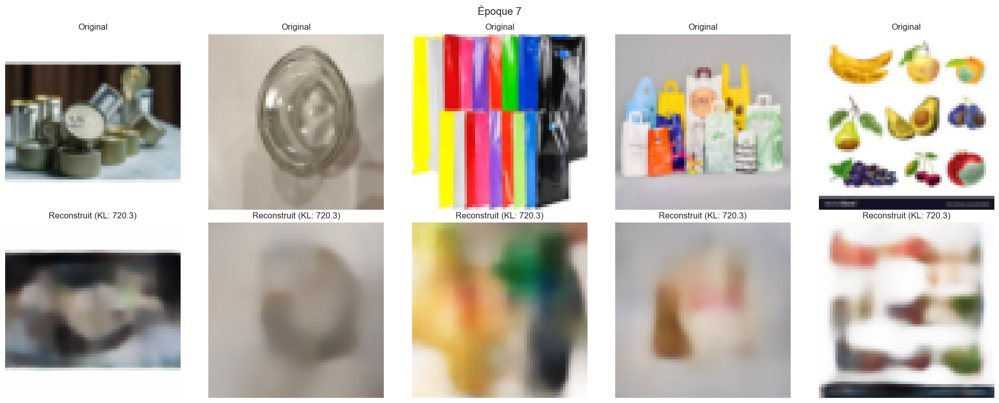

683/683 ━━━━━━━━━━━━━━━━━━━━ 465s 681ms/step - kl_loss: 720.2760 - loss: 5789.8086 - recon_loss: 5782.6055 - val_kl_loss: 722.8882 - val_loss: 5988.2437 - val_recon_loss: 5981.0142 - learning_rate: 0.0010
Epoch 8/175
683/683 ━━━━━━━━━━━━━━━━━━━━ 0s 643ms/step - kl_loss: 729.1551 - loss: 5773.0581 - recon_loss: 5765.7690
Epoch 8: val_recon_loss did not improve from 5957.71582


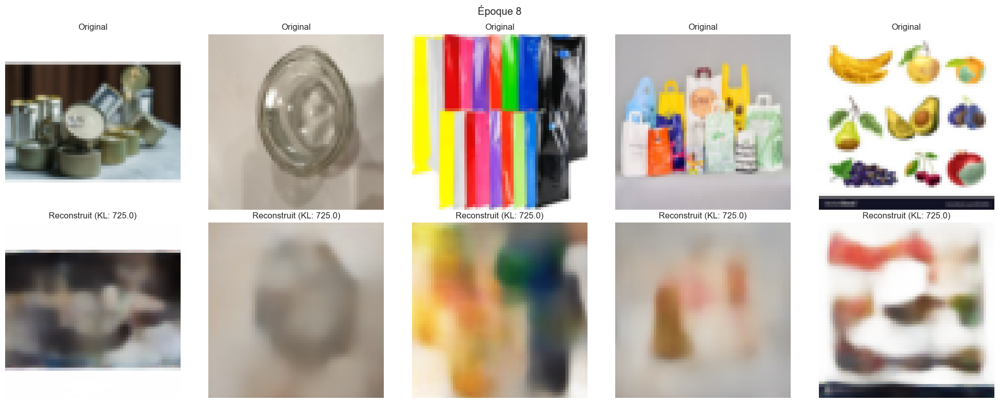

683/683 ━━━━━━━━━━━━━━━━━━━━ 456s 668ms/step - kl_loss: 725.0312 - loss: 5783.1235 - recon_loss: 5775.8770 - val_kl_loss: 696.1406 - val_loss: 5973.3394 - val_recon_loss: 5966.3784 - learning_rate: 0.0010
Epoch 9/175
683/683 ━━━━━━━━━━━━━━━━━━━━ 0s 646ms/step - kl_loss: 722.1590 - loss: 5811.9741 - recon_loss: 5804.7534
Epoch 9: val_recon_loss did not improve from 5957.71582


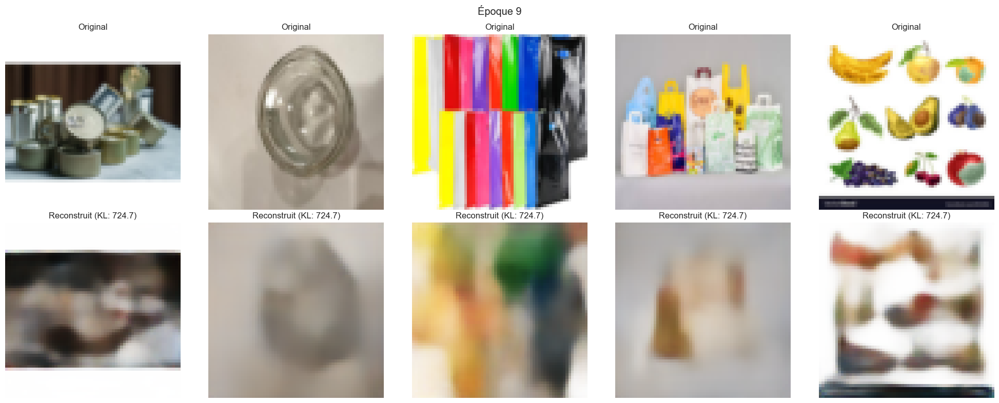

683/683 ━━━━━━━━━━━━━━━━━━━━ 458s 671ms/step - kl_loss: 724.6730 - loss: 5779.3320 - recon_loss: 5772.0864 - val_kl_loss: 721.7387 - val_loss: 5974.9663 - val_recon_loss: 5967.7480 - learning_rate: 0.0010
Epoch 10/175
683/683 ━━━━━━━━━━━━━━━━━━━━ 0s 639ms/step - kl_loss: 727.6386 - loss: 5806.6860 - recon_loss: 5799.4106
Epoch 10: val_recon_loss did not improve from 5957.71582


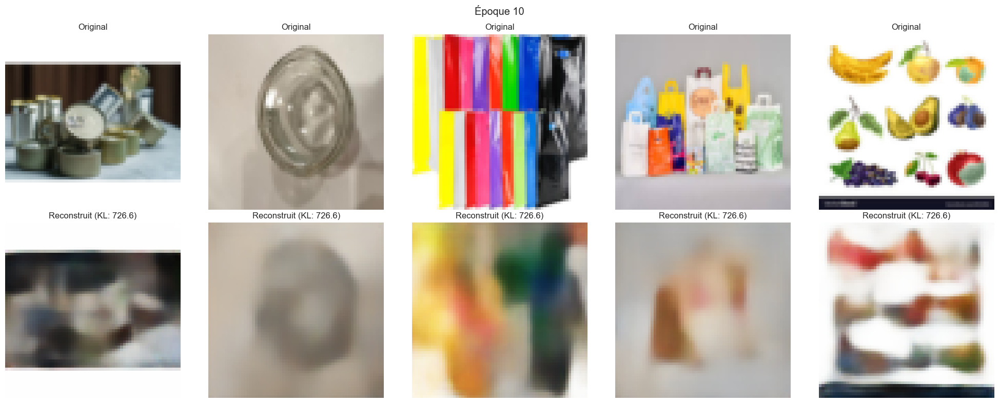

683/683 ━━━━━━━━━━━━━━━━━━━━ 453s 664ms/step - kl_loss: 726.6379 - loss: 5770.5210 - recon_loss: 5763.2549 - val_kl_loss: 688.6125 - val_loss: 5984.0923 - val_recon_loss: 5977.2070 - learning_rate: 0.0010
Epoch 11/175
683/683 ━━━━━━━━━━━━━━━━━━━━ 0s 644ms/step - kl_loss: 723.6761 - loss: 5768.8481 - recon_loss: 5761.6099
Epoch 11: val_recon_loss did not improve from 5957.71582


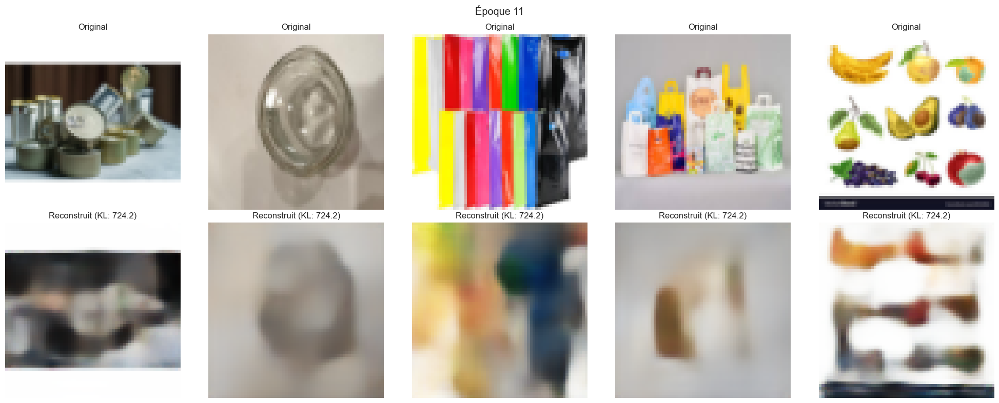

683/683 ━━━━━━━━━━━━━━━━━━━━ 457s 669ms/step - kl_loss: 724.2412 - loss: 5768.3105 - recon_loss: 5761.0645 - val_kl_loss: 715.6376 - val_loss: 5966.9351 - val_recon_loss: 5959.7783 - learning_rate: 0.0010
Epoch 12/175
683/683 ━━━━━━━━━━━━━━━━━━━━ 0s 640ms/step - kl_loss: 728.3129 - loss: 5773.4995 - recon_loss: 5766.2173
Epoch 12: val_recon_loss did not improve from 5957.71582


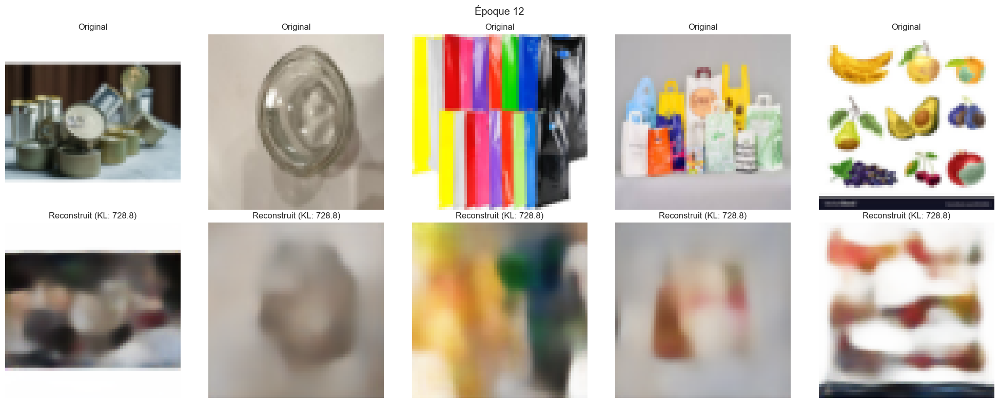

683/683 ━━━━━━━━━━━━━━━━━━━━ 455s 666ms/step - kl_loss: 728.8435 - loss: 5766.8970 - recon_loss: 5759.6099 - val_kl_loss: 715.9957 - val_loss: 5988.1934 - val_recon_loss: 5981.0356 - learning_rate: 0.0010
Epoch 13/175
683/683 ━━━━━━━━━━━━━━━━━━━━ 0s 640ms/step - kl_loss: 728.5543 - loss: 5759.1509 - recon_loss: 5751.8667
Epoch 13: val_recon_loss improved from 5957.71582 to 5950.56641, saving model to model_dct_10.keras


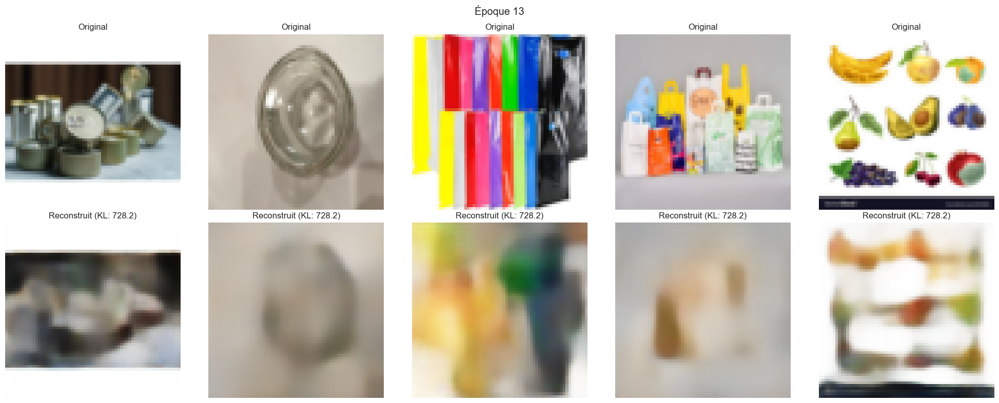

683/683 ━━━━━━━━━━━━━━━━━━━━ 455s 667ms/step - kl_loss: 728.2136 - loss: 5764.3657 - recon_loss: 5757.0859 - val_kl_loss: 702.4104 - val_loss: 5957.5898 - val_recon_loss: 5950.5664 - learning_rate: 0.0010
Epoch 14/175
683/683 ━━━━━━━━━━━━━━━━━━━━ 0s 646ms/step - kl_loss: 729.1706 - loss: 5735.6338 - recon_loss: 5728.3423
Epoch 14: val_recon_loss did not improve from 5950.56641


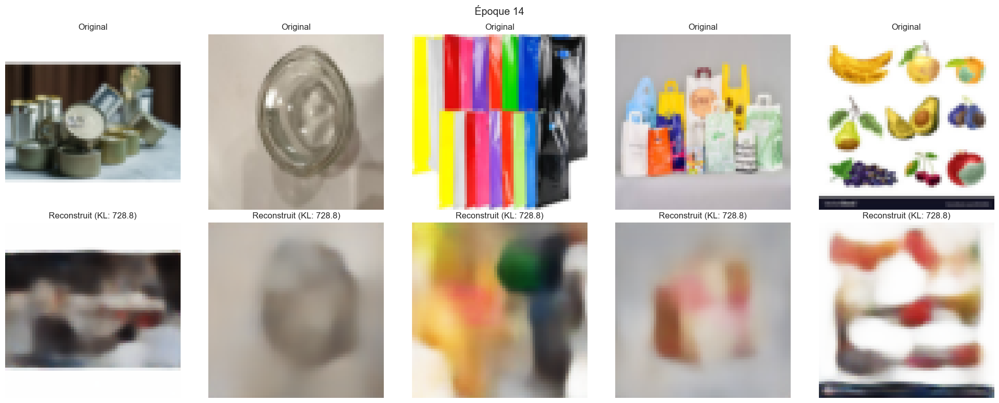

683/683 ━━━━━━━━━━━━━━━━━━━━ 458s 670ms/step - kl_loss: 728.8260 - loss: 5761.8091 - recon_loss: 5754.5195 - val_kl_loss: 710.6092 - val_loss: 5965.9023 - val_recon_loss: 5958.7949 - learning_rate: 0.0010
Epoch 15/175
683/683 ━━━━━━━━━━━━━━━━━━━━ 0s 644ms/step - kl_loss: 733.6948 - loss: 5742.0107 - recon_loss: 5734.6719
Epoch 15: val_recon_loss did not improve from 5950.56641


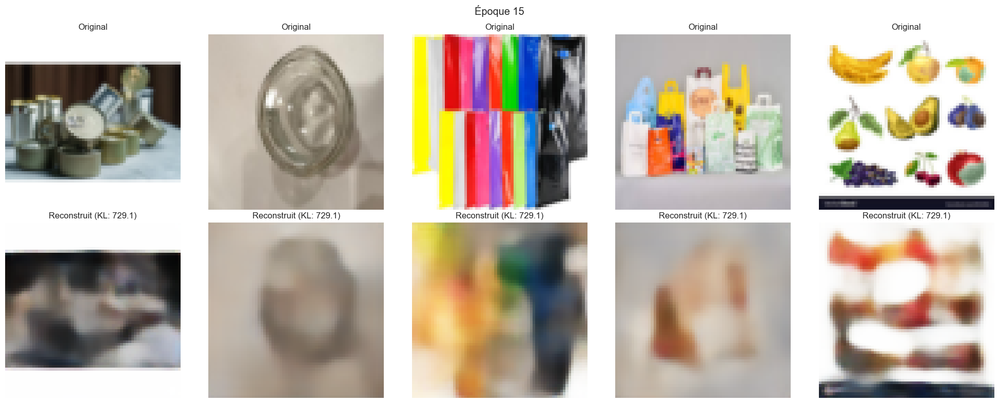

683/683 ━━━━━━━━━━━━━━━━━━━━ 457s 669ms/step - kl_loss: 729.0504 - loss: 5757.4644 - recon_loss: 5750.1709 - val_kl_loss: 714.7068 - val_loss: 5984.6367 - val_recon_loss: 5977.4878 - learning_rate: 0.0010
Epoch 16/175
683/683 ━━━━━━━━━━━━━━━━━━━━ 0s 653ms/step - kl_loss: 727.0410 - loss: 5730.1689 - recon_loss: 5722.8975
Epoch 16: val_recon_loss did not improve from 5950.56641


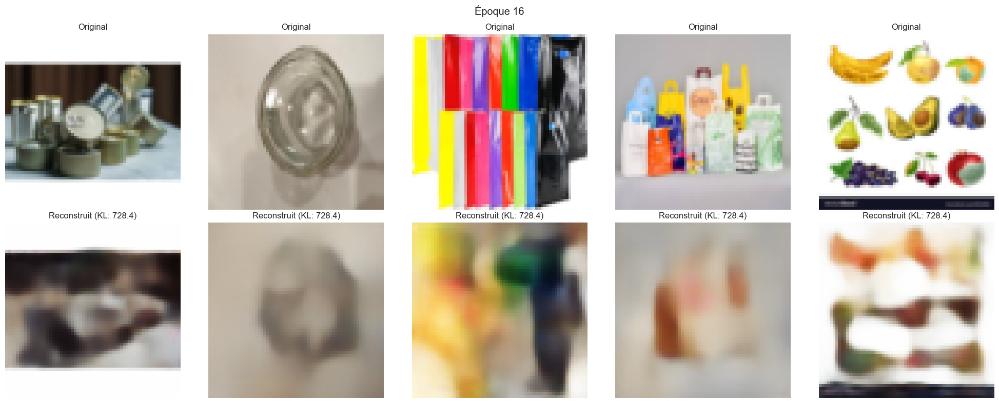

683/683 ━━━━━━━━━━━━━━━━━━━━ 463s 678ms/step - kl_loss: 728.4290 - loss: 5754.7783 - recon_loss: 5747.4907 - val_kl_loss: 711.3838 - val_loss: 5978.9409 - val_recon_loss: 5971.8271 - learning_rate: 0.0010
Epoch 17/175
683/683 ━━━━━━━━━━━━━━━━━━━━ 0s 724ms/step - kl_loss: 726.9833 - loss: 5760.4502 - recon_loss: 5753.1797
Epoch 17: val_recon_loss did not improve from 5950.56641


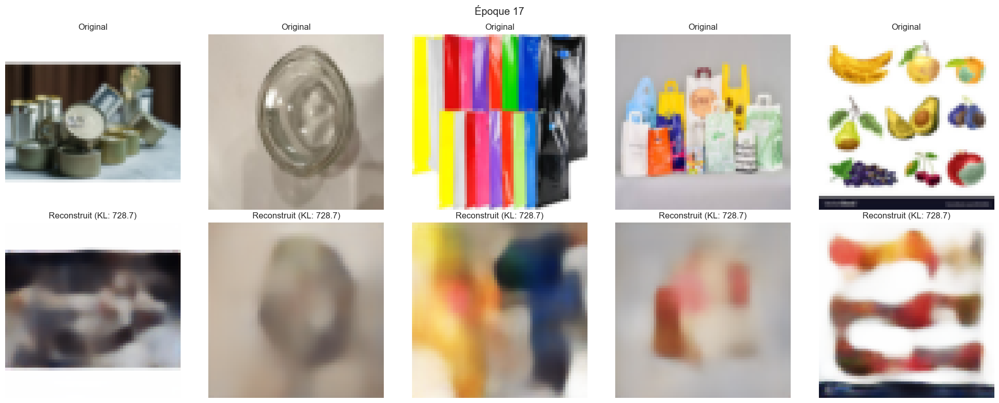

683/683 ━━━━━━━━━━━━━━━━━━━━ 555s 755ms/step - kl_loss: 728.7176 - loss: 5750.4409 - recon_loss: 5743.1519 - val_kl_loss: 735.3146 - val_loss: 5977.7725 - val_recon_loss: 5970.4194 - learning_rate: 0.0010
Epoch 18/175
683/683 ━━━━━━━━━━━━━━━━━━━━ 0s 634ms/step - kl_loss: 731.7089 - loss: 5712.3345 - recon_loss: 5705.0156
Epoch 18: val_recon_loss did not improve from 5950.56641


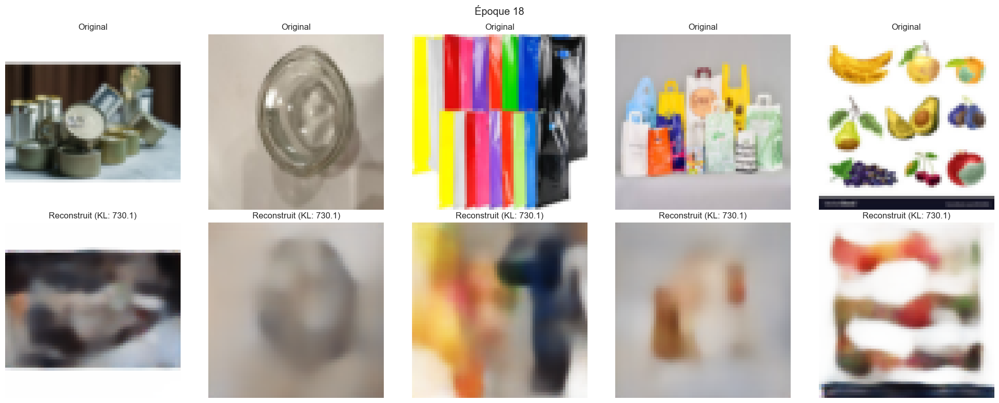

683/683 ━━━━━━━━━━━━━━━━━━━━ 497s 659ms/step - kl_loss: 730.1288 - loss: 5752.6094 - recon_loss: 5745.3086 - val_kl_loss: 739.8953 - val_loss: 5985.1519 - val_recon_loss: 5977.7524 - learning_rate: 0.0010
Epoch 19/175
683/683 ━━━━━━━━━━━━━━━━━━━━ 0s 645ms/step - kl_loss: 733.1616 - loss: 5758.5947 - recon_loss: 5751.2622
Epoch 19: val_recon_loss improved from 5950.56641 to 5944.41943, saving model to model_dct_10.keras


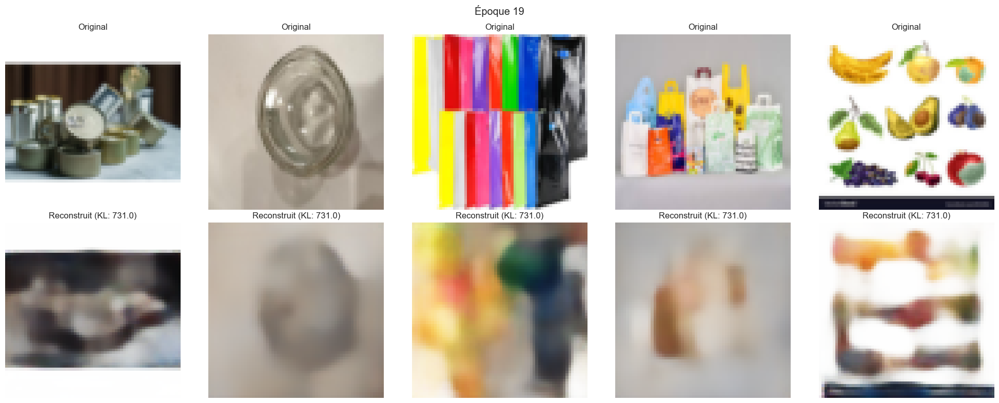

683/683 ━━━━━━━━━━━━━━━━━━━━ 458s 671ms/step - kl_loss: 731.0015 - loss: 5748.1509 - recon_loss: 5740.8394 - val_kl_loss: 731.7681 - val_loss: 5951.7378 - val_recon_loss: 5944.4194 - learning_rate: 0.0010
Epoch 20/175
683/683 ━━━━━━━━━━━━━━━━━━━━ 0s 644ms/step - kl_loss: 732.4177 - loss: 5717.2173 - recon_loss: 5709.8945
Epoch 20: val_recon_loss did not improve from 5944.41943


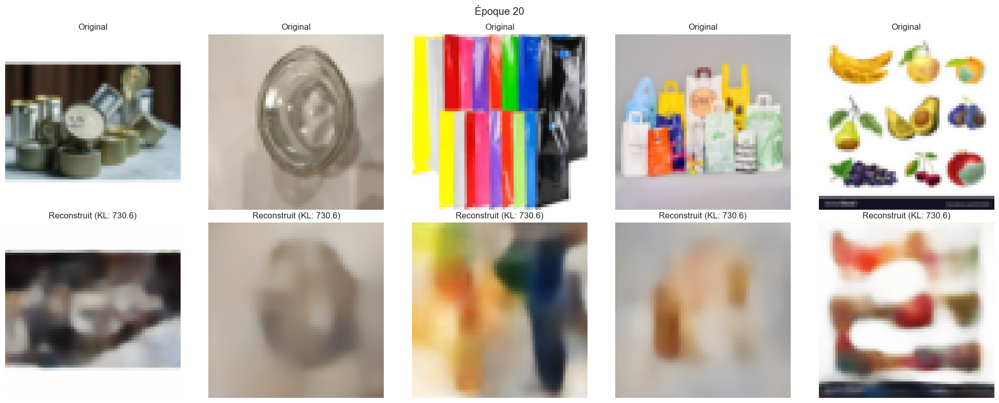

683/683 ━━━━━━━━━━━━━━━━━━━━ 457s 670ms/step - kl_loss: 730.6210 - loss: 5743.7622 - recon_loss: 5736.4600 - val_kl_loss: 699.1086 - val_loss: 5973.7646 - val_recon_loss: 5966.7749 - learning_rate: 0.0010
Epoch 21/175
683/683 ━━━━━━━━━━━━━━━━━━━━ 0s 646ms/step - kl_loss: 729.2264 - loss: 5724.8428 - recon_loss: 5717.5522
Epoch 21: val_recon_loss improved from 5944.41943 to 5943.09229, saving model to model_dct_10.keras


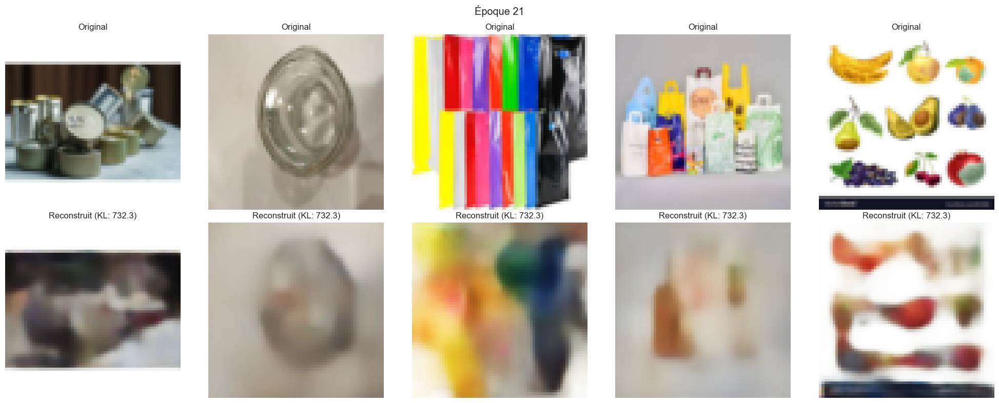

683/683 ━━━━━━━━━━━━━━━━━━━━ 459s 673ms/step - kl_loss: 732.2979 - loss: 5741.7583 - recon_loss: 5734.4365 - val_kl_loss: 730.8231 - val_loss: 5950.3989 - val_recon_loss: 5943.0923 - learning_rate: 0.0010
Epoch 22/175
683/683 ━━━━━━━━━━━━━━━━━━━━ 0s 645ms/step - kl_loss: 730.1125 - loss: 5756.2412 - recon_loss: 5748.9409
Epoch 22: val_recon_loss did not improve from 5943.09229


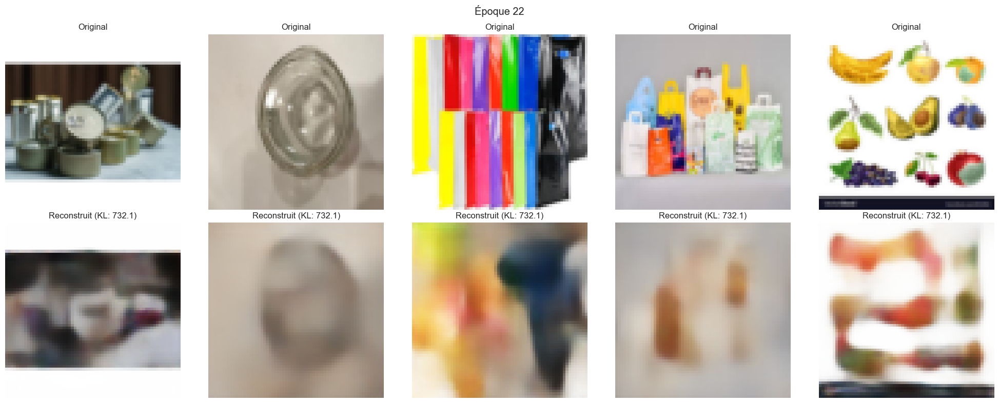

683/683 ━━━━━━━━━━━━━━━━━━━━ 458s 671ms/step - kl_loss: 732.1144 - loss: 5744.5439 - recon_loss: 5737.2231 - val_kl_loss: 720.7338 - val_loss: 5954.4219 - val_recon_loss: 5947.2148 - learning_rate: 0.0010
Epoch 23/175
683/683 ━━━━━━━━━━━━━━━━━━━━ 0s 646ms/step - kl_loss: 734.7587 - loss: 5727.8687 - recon_loss: 5720.5229
Epoch 23: val_recon_loss did not improve from 5943.09229


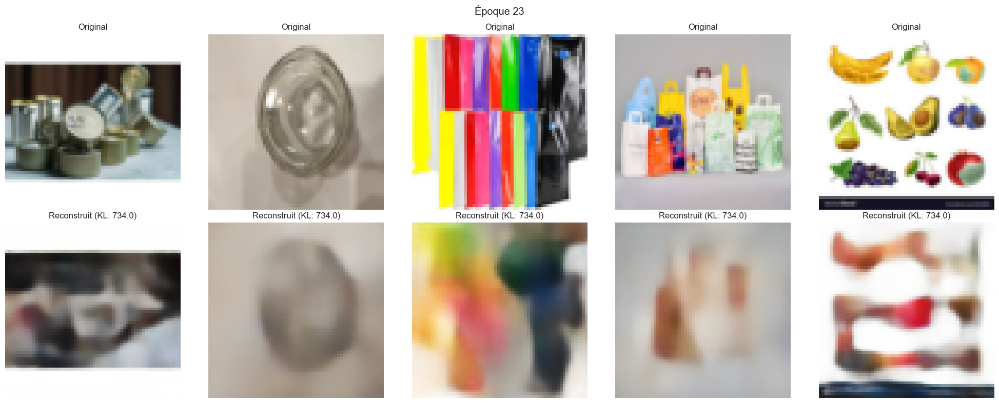

683/683 ━━━━━━━━━━━━━━━━━━━━ 459s 671ms/step - kl_loss: 733.9570 - loss: 5735.6250 - recon_loss: 5728.2900 - val_kl_loss: 744.1653 - val_loss: 5950.6616 - val_recon_loss: 5943.2197 - learning_rate: 0.0010
Epoch 24/175
683/683 ━━━━━━━━━━━━━━━━━━━━ 0s 642ms/step - kl_loss: 736.7438 - loss: 5743.3340 - recon_loss: 5735.9678
Epoch 24: val_recon_loss did not improve from 5943.09229


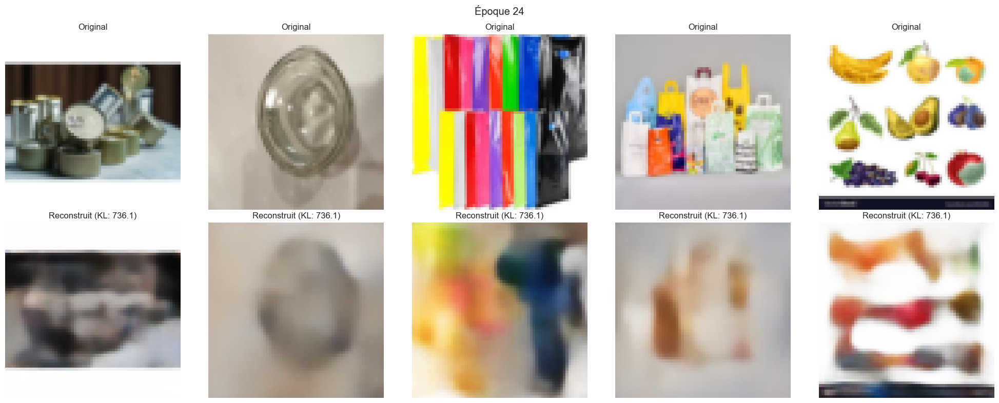

683/683 ━━━━━━━━━━━━━━━━━━━━ 456s 668ms/step - kl_loss: 736.1309 - loss: 5739.5278 - recon_loss: 5732.1714 - val_kl_loss: 755.7199 - val_loss: 5952.2915 - val_recon_loss: 5944.7339 - learning_rate: 0.0010
Epoch 25/175
683/683 ━━━━━━━━━━━━━━━━━━━━ 0s 647ms/step - kl_loss: 734.7853 - loss: 5734.9561 - recon_loss: 5727.6050
Epoch 25: val_recon_loss did not improve from 5943.09229


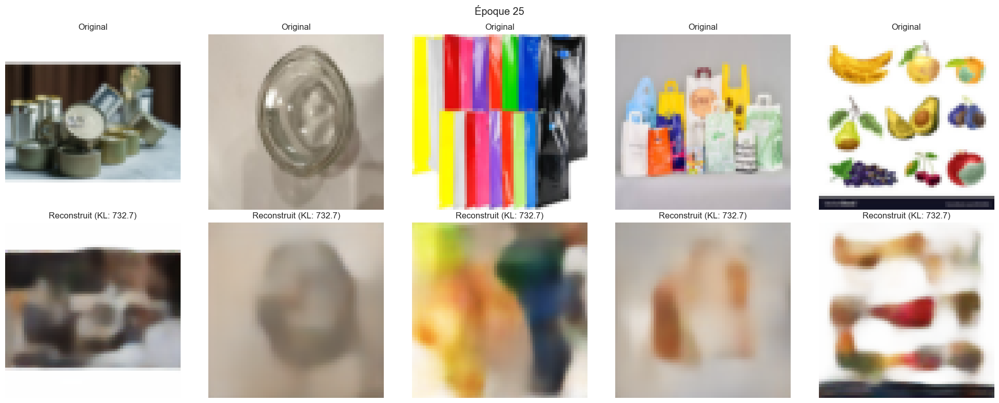

683/683 ━━━━━━━━━━━━━━━━━━━━ 458s 671ms/step - kl_loss: 732.6636 - loss: 5731.0547 - recon_loss: 5723.7246 - val_kl_loss: 755.0156 - val_loss: 5964.6362 - val_recon_loss: 5957.0869 - learning_rate: 0.0010
Epoch 26/175
683/683 ━━━━━━━━━━━━━━━━━━━━ 0s 632ms/step - kl_loss: 737.0502 - loss: 5728.8838 - recon_loss: 5721.5132
Epoch 26: val_recon_loss did not improve from 5943.09229


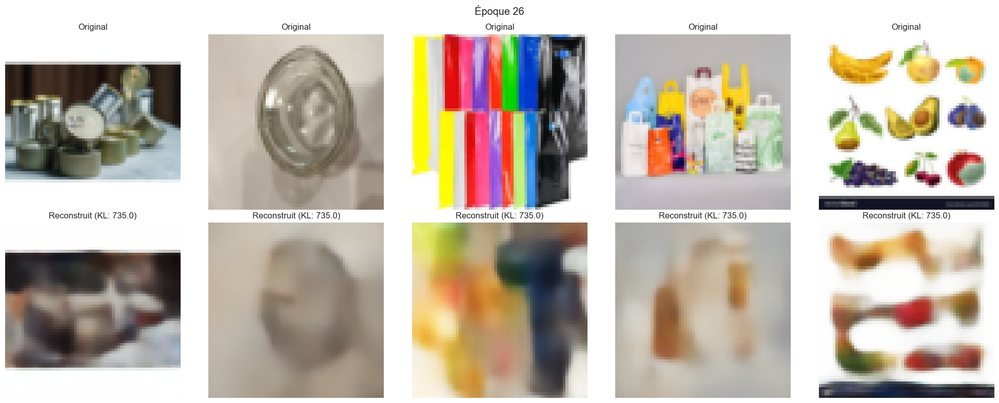

683/683 ━━━━━━━━━━━━━━━━━━━━ 493s 658ms/step - kl_loss: 734.9562 - loss: 5732.5835 - recon_loss: 5725.2319 - val_kl_loss: 715.2085 - val_loss: 5958.6147 - val_recon_loss: 5951.4619 - learning_rate: 0.0010
Epoch 27/175
683/683 ━━━━━━━━━━━━━━━━━━━━ 0s 644ms/step - kl_loss: 734.1884 - loss: 5724.3315 - recon_loss: 5716.9897
Epoch 27: val_recon_loss did not improve from 5943.09229


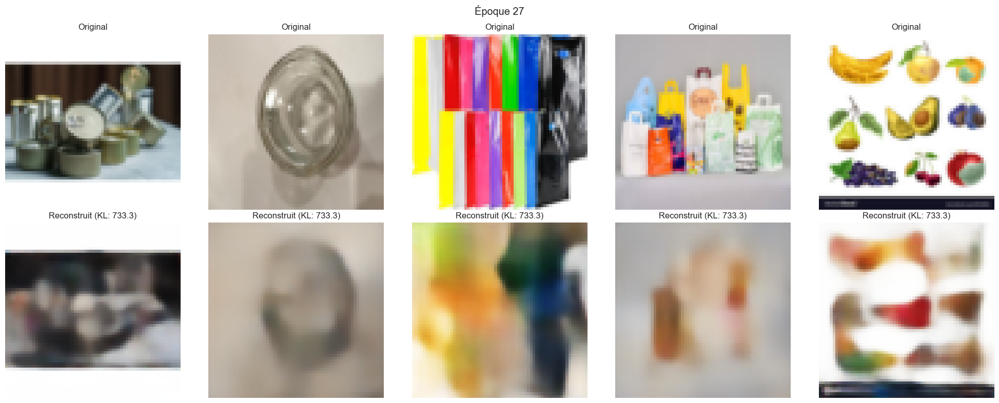

683/683 ━━━━━━━━━━━━━━━━━━━━ 456s 668ms/step - kl_loss: 733.3417 - loss: 5731.6582 - recon_loss: 5724.3281 - val_kl_loss: 719.6964 - val_loss: 5975.9805 - val_recon_loss: 5968.7842 - learning_rate: 0.0010
Epoch 28/175
683/683 ━━━━━━━━━━━━━━━━━━━━ 0s 645ms/step - kl_loss: 738.7464 - loss: 5707.9263 - recon_loss: 5700.5391
Epoch 28: val_recon_loss did not improve from 5943.09229


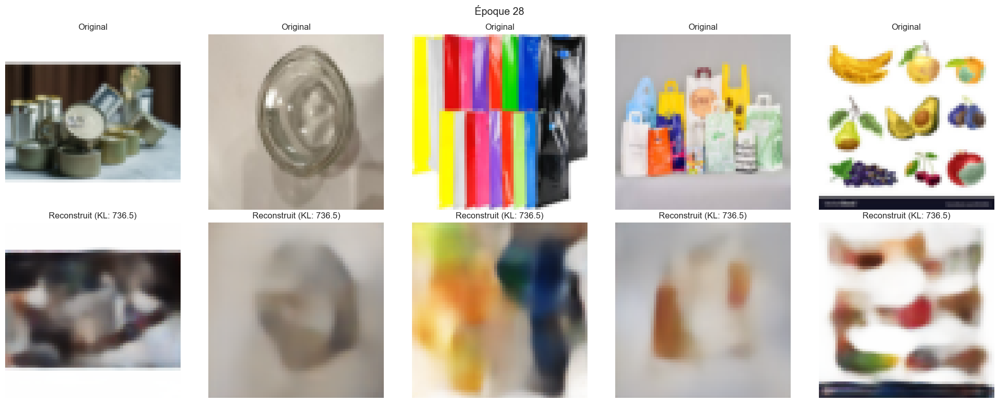

683/683 ━━━━━━━━━━━━━━━━━━━━ 458s 670ms/step - kl_loss: 736.5396 - loss: 5725.7261 - recon_loss: 5718.3628 - val_kl_loss: 731.2837 - val_loss: 5960.7700 - val_recon_loss: 5953.4580 - learning_rate: 0.0010
Epoch 29/175
683/683 ━━━━━━━━━━━━━━━━━━━━ 0s 649ms/step - kl_loss: 739.3842 - loss: 5698.5796 - recon_loss: 5691.1860
Epoch 29: val_recon_loss did not improve from 5943.09229


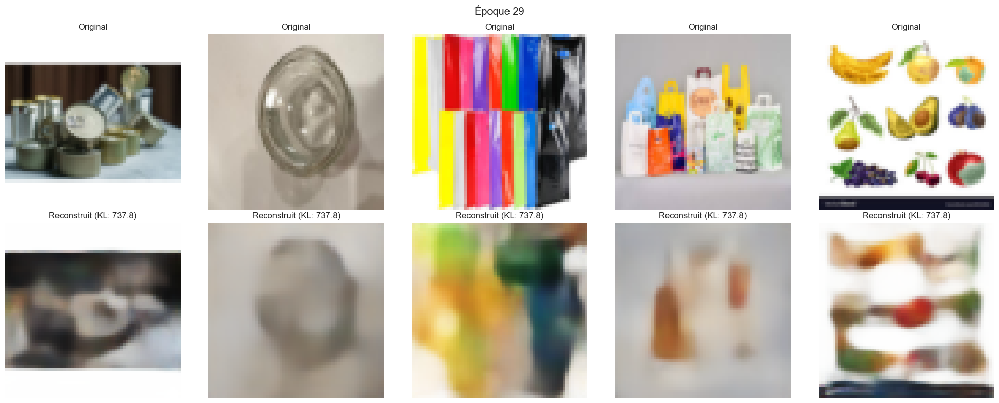

683/683 ━━━━━━━━━━━━━━━━━━━━ 460s 674ms/step - kl_loss: 737.7832 - loss: 5727.8799 - recon_loss: 5720.5005 - val_kl_loss: 728.1571 - val_loss: 5952.6279 - val_recon_loss: 5945.3481 - learning_rate: 0.0010
Epoch 30/175
683/683 ━━━━━━━━━━━━━━━━━━━━ 0s 646ms/step - kl_loss: 732.7552 - loss: 5716.4766 - recon_loss: 5709.1470
Epoch 30: val_recon_loss did not improve from 5943.09229


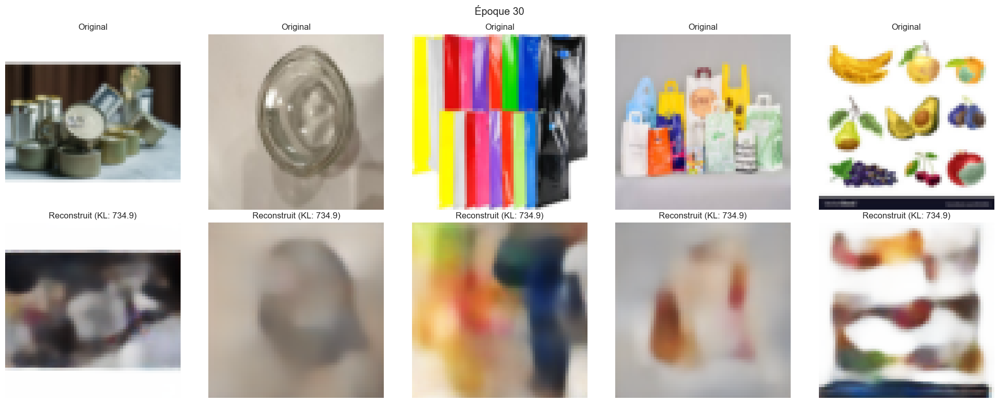

683/683 ━━━━━━━━━━━━━━━━━━━━ 459s 672ms/step - kl_loss: 734.8812 - loss: 5729.6870 - recon_loss: 5722.3364 - val_kl_loss: 711.8690 - val_loss: 5987.6655 - val_recon_loss: 5980.5464 - learning_rate: 0.0010
Epoch 31/175
683/683 ━━━━━━━━━━━━━━━━━━━━ 0s 646ms/step - kl_loss: 733.3578 - loss: 5723.6338 - recon_loss: 5716.3008
Epoch 31: val_recon_loss did not improve from 5943.09229

Epoch 31: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.


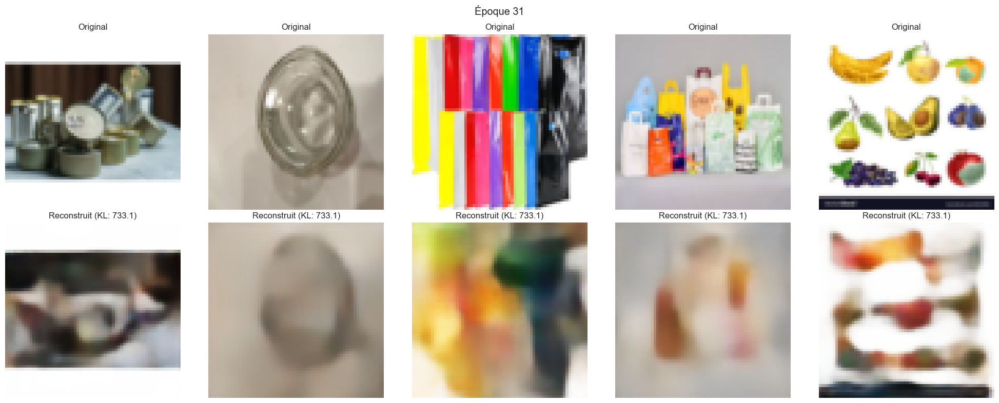

683/683 ━━━━━━━━━━━━━━━━━━━━ 458s 670ms/step - kl_loss: 733.1431 - loss: 5722.6235 - recon_loss: 5715.2935 - val_kl_loss: 733.5607 - val_loss: 5959.1685 - val_recon_loss: 5951.8335 - learning_rate: 0.0010
Epoch 32/175
683/683 ━━━━━━━━━━━━━━━━━━━━ 0s 645ms/step - kl_loss: 738.3956 - loss: 5662.9062 - recon_loss: 5655.5225
Epoch 32: val_recon_loss improved from 5943.09229 to 5926.72656, saving model to model_dct_10.keras


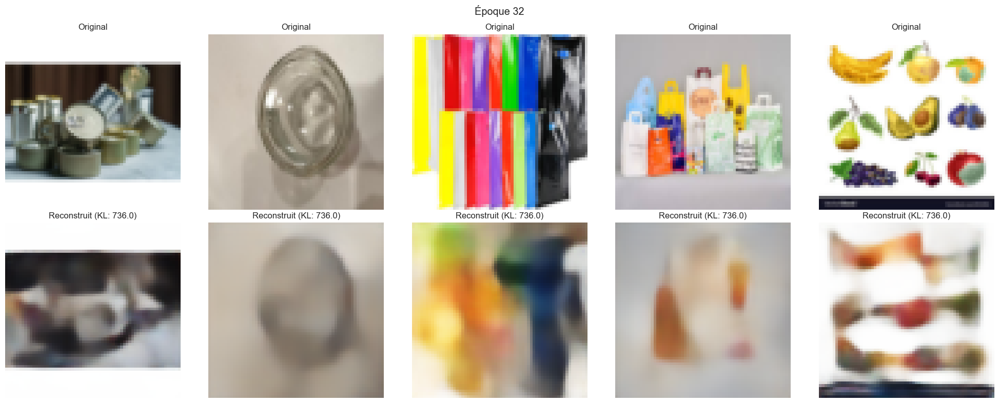

683/683 ━━━━━━━━━━━━━━━━━━━━ 459s 672ms/step - kl_loss: 736.0178 - loss: 5699.6250 - recon_loss: 5692.2632 - val_kl_loss: 714.8981 - val_loss: 5933.8740 - val_recon_loss: 5926.7266 - learning_rate: 5.0000e-04
Epoch 33/175
683/683 ━━━━━━━━━━━━━━━━━━━━ 0s 643ms/step - kl_loss: 740.8699 - loss: 5695.2588 - recon_loss: 5687.8491
Epoch 33: val_recon_loss did not improve from 5926.72656


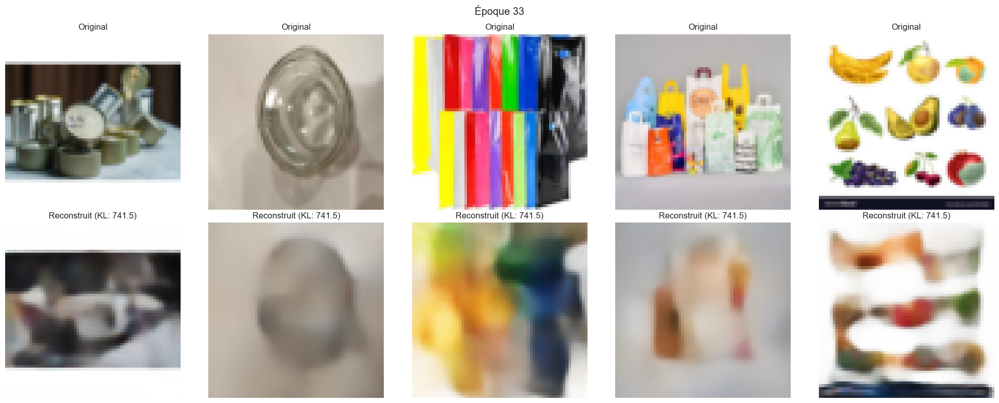

683/683 ━━━━━━━━━━━━━━━━━━━━ 456s 668ms/step - kl_loss: 741.5394 - loss: 5689.0044 - recon_loss: 5681.5903 - val_kl_loss: 730.8652 - val_loss: 5947.1567 - val_recon_loss: 5939.8501 - learning_rate: 5.0000e-04
Epoch 34/175
683/683 ━━━━━━━━━━━━━━━━━━━━ 0s 639ms/step - kl_loss: 748.2219 - loss: 5650.4092 - recon_loss: 5642.9302
Epoch 34: val_recon_loss did not improve from 5926.72656


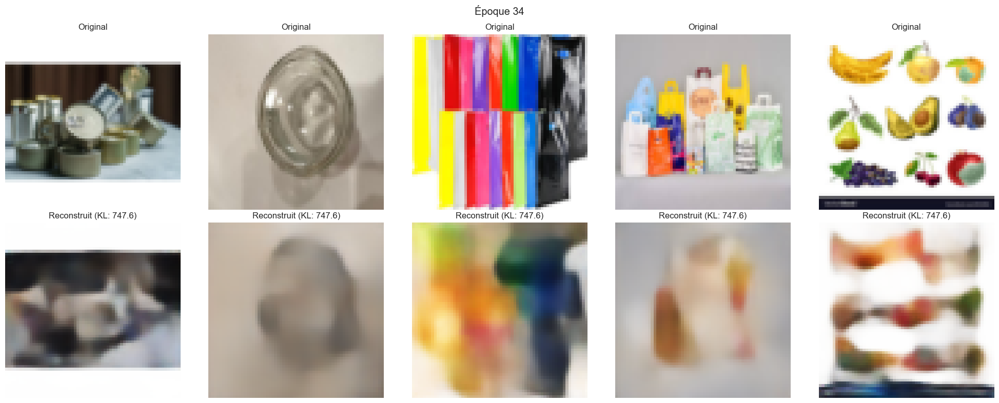

683/683 ━━━━━━━━━━━━━━━━━━━━ 454s 664ms/step - kl_loss: 747.6442 - loss: 5686.9629 - recon_loss: 5679.4883 - val_kl_loss: 728.4282 - val_loss: 5958.4639 - val_recon_loss: 5951.1807 - learning_rate: 5.0000e-04
Epoch 35/175
683/683 ━━━━━━━━━━━━━━━━━━━━ 0s 644ms/step - kl_loss: 748.4273 - loss: 5683.9927 - recon_loss: 5676.5103
Epoch 35: val_recon_loss did not improve from 5926.72656


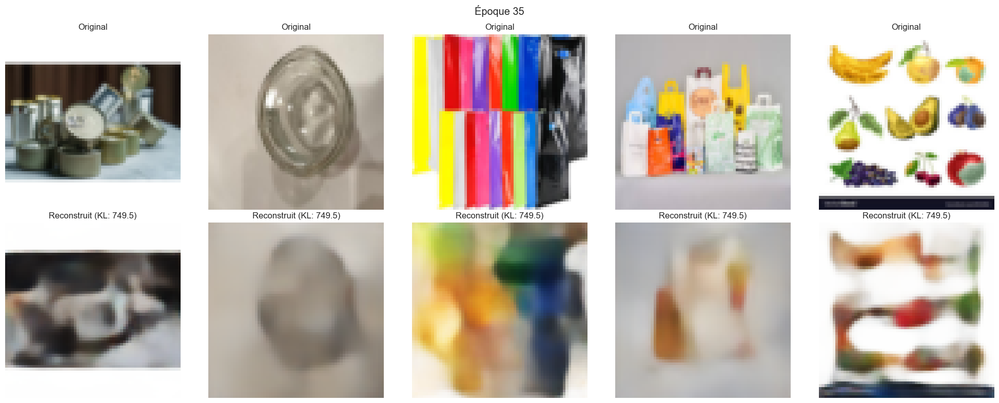

683/683 ━━━━━━━━━━━━━━━━━━━━ 457s 669ms/step - kl_loss: 749.5358 - loss: 5686.5977 - recon_loss: 5679.1045 - val_kl_loss: 736.7440 - val_loss: 5945.7886 - val_recon_loss: 5938.4229 - learning_rate: 5.0000e-04
Epoch 36/175
683/683 ━━━━━━━━━━━━━━━━━━━━ 0s 645ms/step - kl_loss: 753.7607 - loss: 5631.8267 - recon_loss: 5624.2886
Epoch 36: val_recon_loss did not improve from 5926.72656


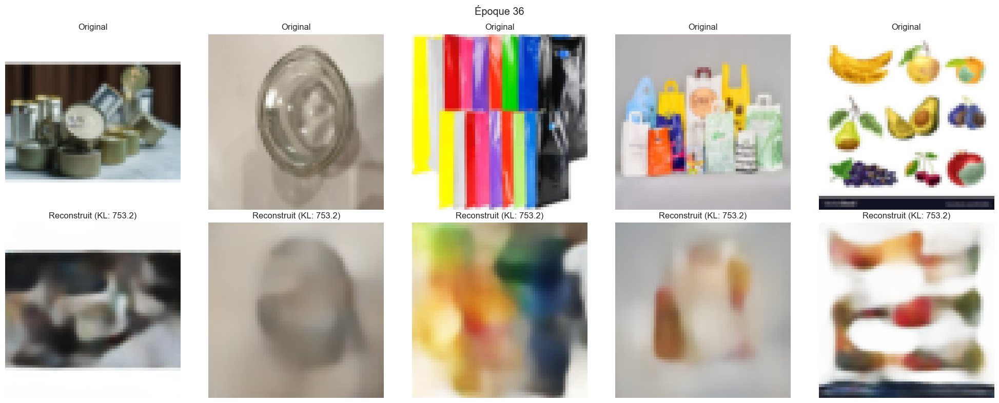

683/683 ━━━━━━━━━━━━━━━━━━━━ 458s 670ms/step - kl_loss: 753.2377 - loss: 5683.1514 - recon_loss: 5675.6177 - val_kl_loss: 738.3979 - val_loss: 5947.4985 - val_recon_loss: 5940.1143 - learning_rate: 5.0000e-04
Epoch 37/175
683/683 ━━━━━━━━━━━━━━━━━━━━ 0s 646ms/step - kl_loss: 754.0507 - loss: 5649.5059 - recon_loss: 5641.9644
Epoch 37: val_recon_loss did not improve from 5926.72656


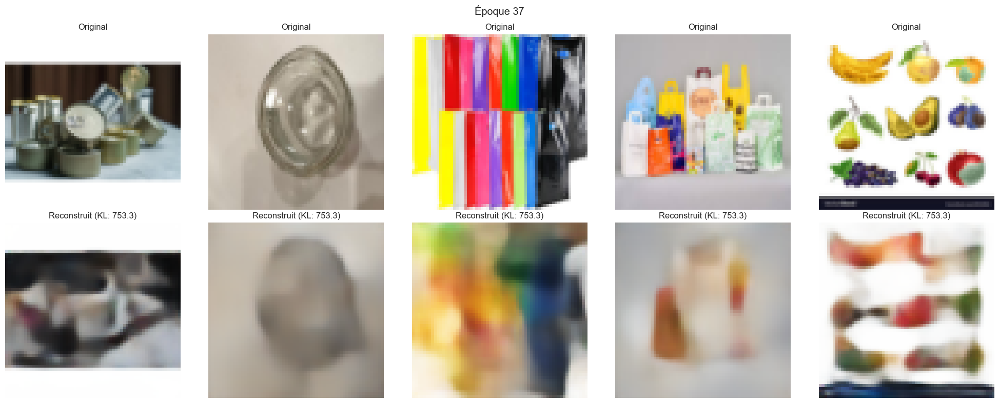

683/683 ━━━━━━━━━━━━━━━━━━━━ 459s 672ms/step - kl_loss: 753.3102 - loss: 5681.9243 - recon_loss: 5674.3872 - val_kl_loss: 737.4497 - val_loss: 5948.1030 - val_recon_loss: 5940.7305 - learning_rate: 5.0000e-04
Epoch 38/175
683/683 ━━━━━━━━━━━━━━━━━━━━ 0s 645ms/step - kl_loss: 754.3632 - loss: 5668.4883 - recon_loss: 5660.9434
Epoch 38: val_recon_loss did not improve from 5926.72656


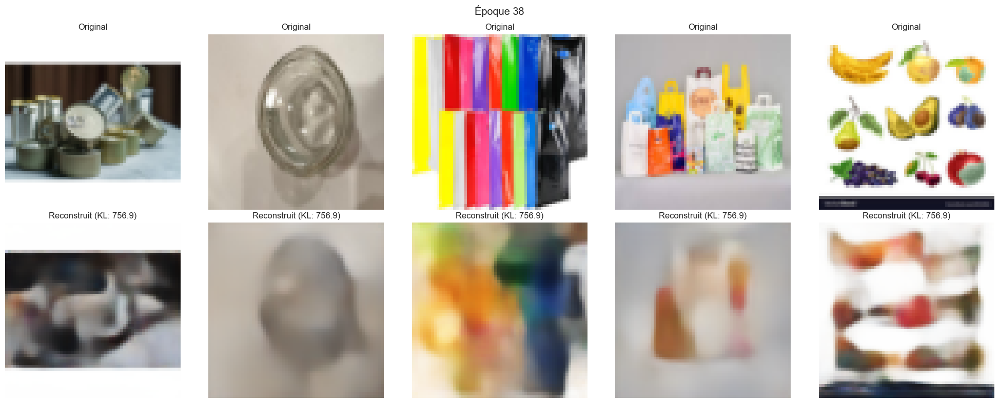

683/683 ━━━━━━━━━━━━━━━━━━━━ 458s 670ms/step - kl_loss: 756.9243 - loss: 5680.9170 - recon_loss: 5673.3486 - val_kl_loss: 733.4135 - val_loss: 5950.3896 - val_recon_loss: 5943.0562 - learning_rate: 5.0000e-04
Epoch 39/175
683/683 ━━━━━━━━━━━━━━━━━━━━ 0s 640ms/step - kl_loss: 756.4778 - loss: 5671.8237 - recon_loss: 5664.2578
Epoch 39: val_recon_loss did not improve from 5926.72656


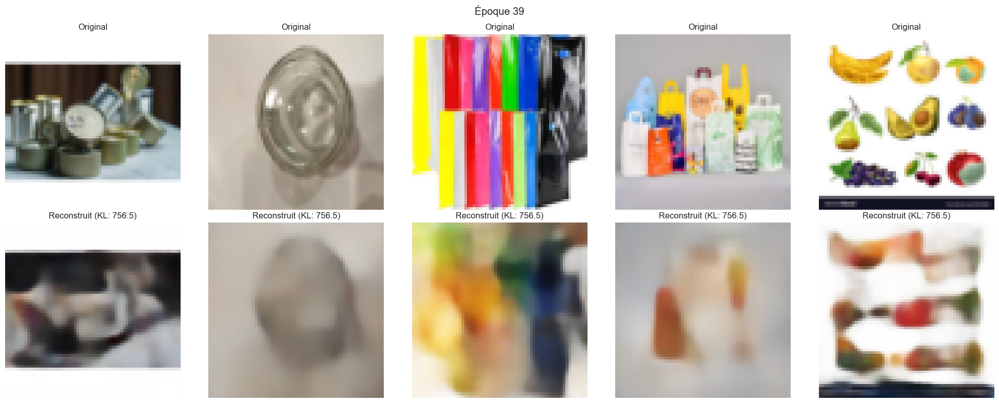

683/683 ━━━━━━━━━━━━━━━━━━━━ 455s 666ms/step - kl_loss: 756.5463 - loss: 5679.1396 - recon_loss: 5671.5732 - val_kl_loss: 751.5937 - val_loss: 5953.5132 - val_recon_loss: 5945.9971 - learning_rate: 5.0000e-04
Epoch 40/175
683/683 ━━━━━━━━━━━━━━━━━━━━ 0s 641ms/step - kl_loss: 760.2752 - loss: 5678.7695 - recon_loss: 5671.1675
Epoch 40: val_recon_loss did not improve from 5926.72656


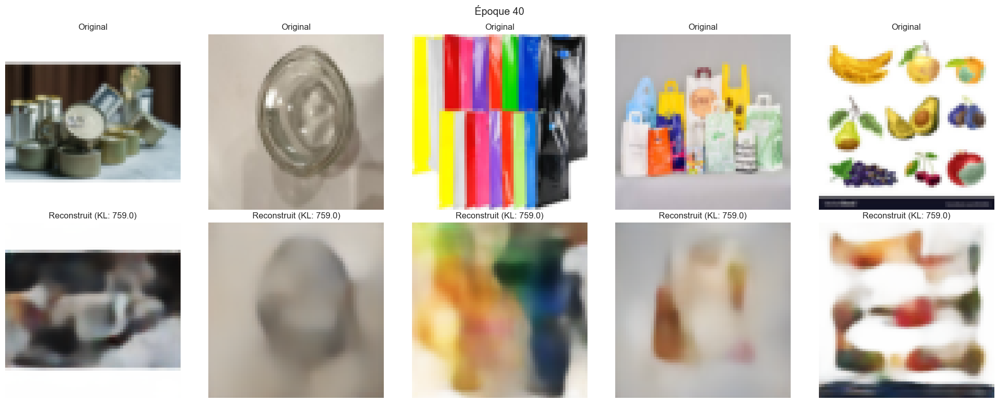

683/683 ━━━━━━━━━━━━━━━━━━━━ 455s 666ms/step - kl_loss: 758.9831 - loss: 5678.1216 - recon_loss: 5670.5298 - val_kl_loss: 750.6459 - val_loss: 5943.8867 - val_recon_loss: 5936.3779 - learning_rate: 5.0000e-04
Epoch 41/175
683/683 ━━━━━━━━━━━━━━━━━━━━ 0s 644ms/step - kl_loss: 761.9676 - loss: 5659.9658 - recon_loss: 5652.3481
Epoch 41: val_recon_loss did not improve from 5926.72656


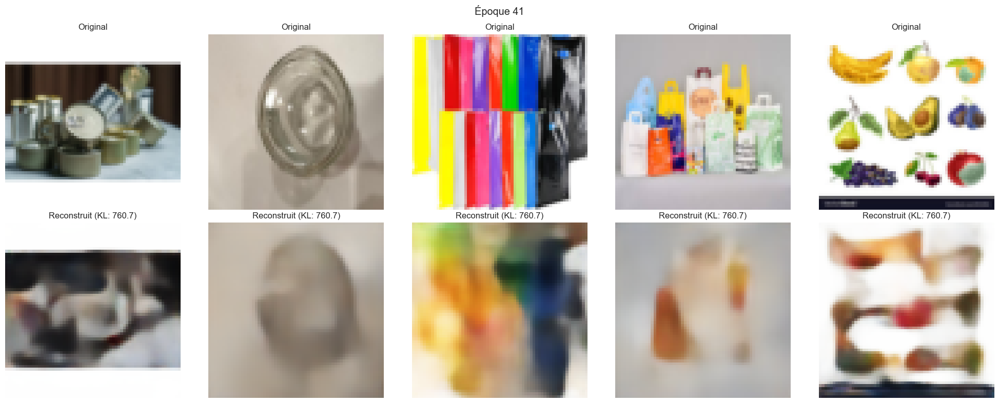

683/683 ━━━━━━━━━━━━━━━━━━━━ 457s 669ms/step - kl_loss: 760.7040 - loss: 5676.7549 - recon_loss: 5669.1519 - val_kl_loss: 737.9211 - val_loss: 5953.5742 - val_recon_loss: 5946.1943 - learning_rate: 5.0000e-04
Epoch 42/175
683/683 ━━━━━━━━━━━━━━━━━━━━ 0s 643ms/step - kl_loss: 759.0809 - loss: 5658.6450 - recon_loss: 5651.0527
Epoch 42: val_recon_loss did not improve from 5926.72656

Epoch 42: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.


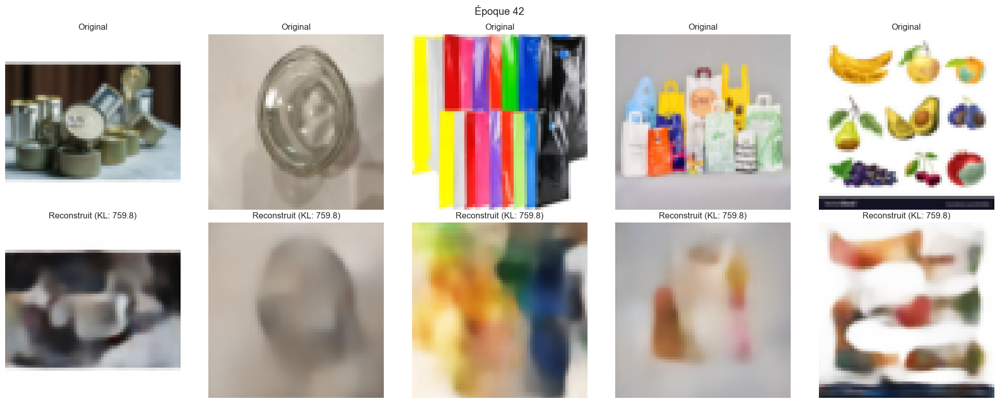

683/683 ━━━━━━━━━━━━━━━━━━━━ 457s 669ms/step - kl_loss: 759.7658 - loss: 5675.5503 - recon_loss: 5667.9482 - val_kl_loss: 743.9963 - val_loss: 5945.5249 - val_recon_loss: 5938.0854 - learning_rate: 5.0000e-04
Epoch 43/175
683/683 ━━━━━━━━━━━━━━━━━━━━ 0s 643ms/step - kl_loss: 765.8034 - loss: 5675.6279 - recon_loss: 5667.9673
Epoch 43: val_recon_loss did not improve from 5926.72656


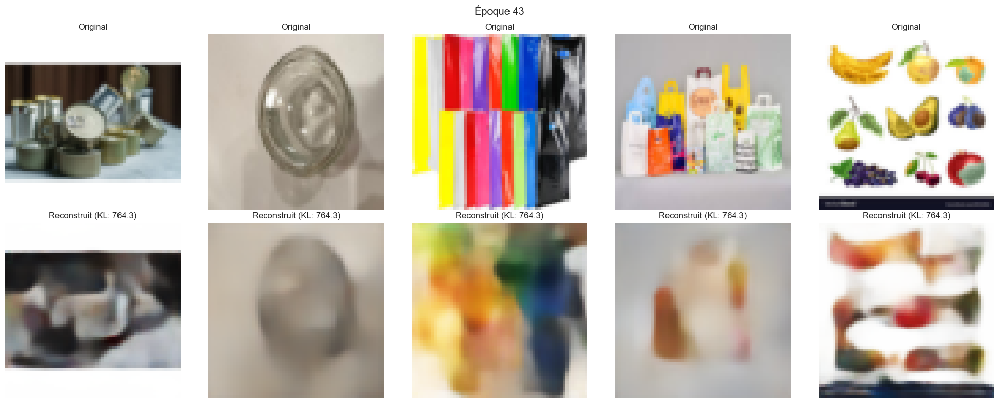

683/683 ━━━━━━━━━━━━━━━━━━━━ 457s 669ms/step - kl_loss: 764.3055 - loss: 5666.3003 - recon_loss: 5658.6523 - val_kl_loss: 754.5112 - val_loss: 5947.5112 - val_recon_loss: 5939.9644 - learning_rate: 2.5000e-04
Epoch 44/175
683/683 ━━━━━━━━━━━━━━━━━━━━ 0s 647ms/step - kl_loss: 772.5339 - loss: 5625.0454 - recon_loss: 5617.3223
Epoch 44: val_recon_loss did not improve from 5926.72656


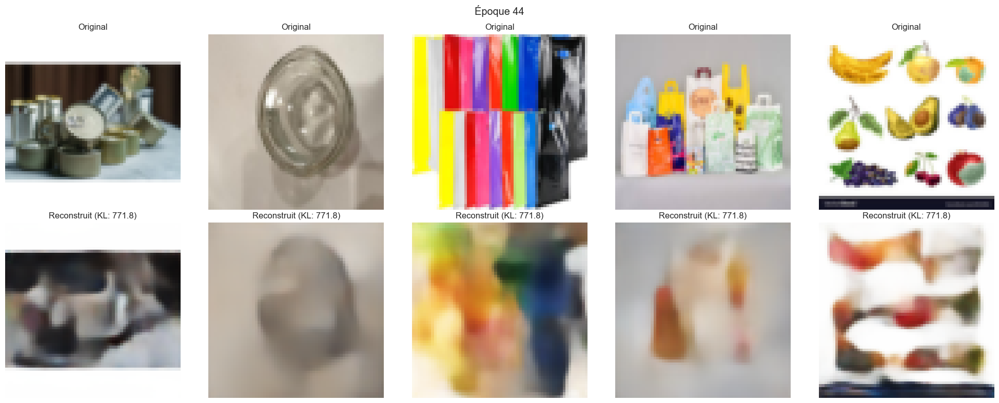

683/683 ━━━━━━━━━━━━━━━━━━━━ 459s 672ms/step - kl_loss: 771.7889 - loss: 5661.1914 - recon_loss: 5653.4780 - val_kl_loss: 763.0451 - val_loss: 5951.7500 - val_recon_loss: 5944.1206 - learning_rate: 2.5000e-04
Epoch 45/175
683/683 ━━━━━━━━━━━━━━━━━━━━ 0s 654ms/step - kl_loss: 778.7314 - loss: 5628.4678 - recon_loss: 5620.6836
Epoch 45: val_recon_loss did not improve from 5926.72656


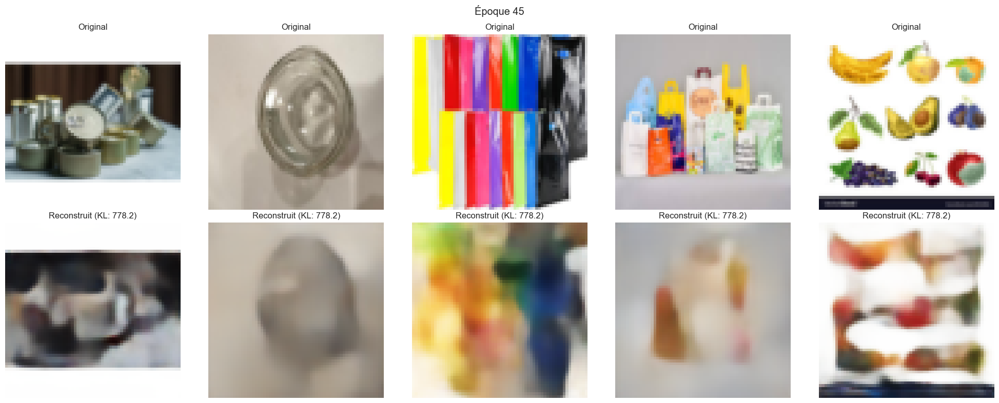

683/683 ━━━━━━━━━━━━━━━━━━━━ 464s 680ms/step - kl_loss: 778.1914 - loss: 5659.5811 - recon_loss: 5651.8037 - val_kl_loss: 759.0541 - val_loss: 5952.4009 - val_recon_loss: 5944.8091 - learning_rate: 2.5000e-04
Epoch 46/175
683/683 ━━━━━━━━━━━━━━━━━━━━ 0s 764ms/step - kl_loss: 780.3618 - loss: 5642.7148 - recon_loss: 5634.9121
Epoch 46: val_recon_loss did not improve from 5926.72656


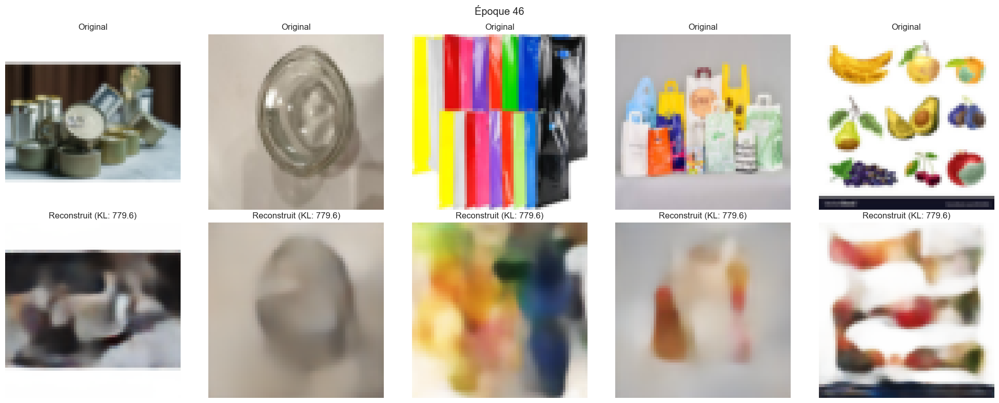

683/683 ━━━━━━━━━━━━━━━━━━━━ 545s 798ms/step - kl_loss: 779.5715 - loss: 5658.7202 - recon_loss: 5650.9248 - val_kl_loss: 768.5279 - val_loss: 5944.5977 - val_recon_loss: 5936.9136 - learning_rate: 2.5000e-04
Epoch 47/175
683/683 ━━━━━━━━━━━━━━━━━━━━ 0s 784ms/step - kl_loss: 782.6835 - loss: 5638.6226 - recon_loss: 5630.7930
Epoch 47: val_recon_loss did not improve from 5926.72656


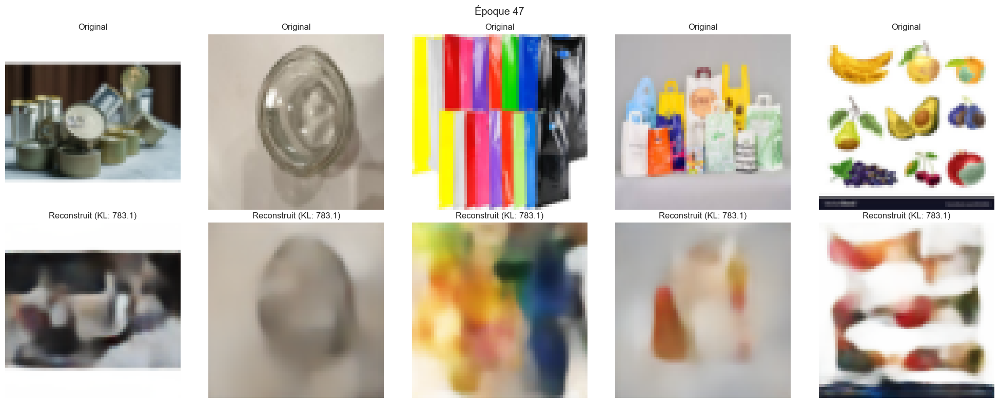

683/683 ━━━━━━━━━━━━━━━━━━━━ 557s 815ms/step - kl_loss: 783.1337 - loss: 5657.7847 - recon_loss: 5649.9482 - val_kl_loss: 762.9827 - val_loss: 5947.1074 - val_recon_loss: 5939.4756 - learning_rate: 2.5000e-04
Epoch 48/175
683/683 ━━━━━━━━━━━━━━━━━━━━ 0s 713ms/step - kl_loss: 782.6425 - loss: 5645.7896 - recon_loss: 5637.9629
Epoch 48: val_recon_loss did not improve from 5926.72656


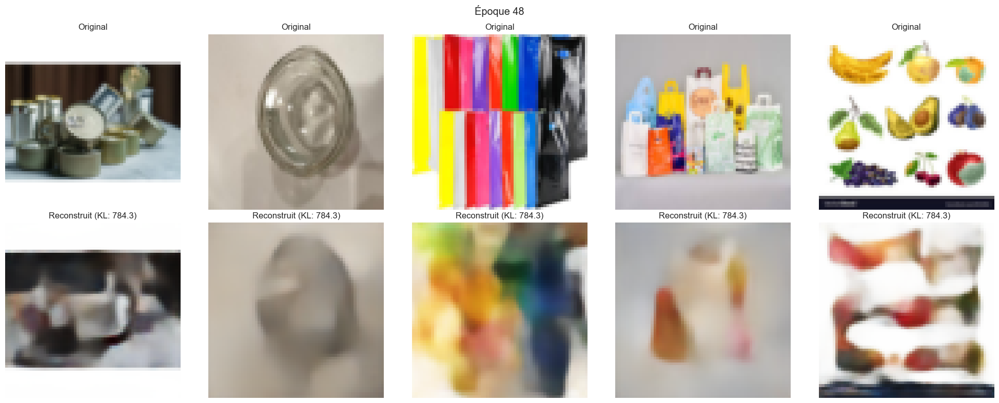

683/683 ━━━━━━━━━━━━━━━━━━━━ 504s 738ms/step - kl_loss: 784.2717 - loss: 5656.8516 - recon_loss: 5649.0078 - val_kl_loss: 775.8039 - val_loss: 5951.3745 - val_recon_loss: 5943.6182 - learning_rate: 2.5000e-04
Epoch 49/175
683/683 ━━━━━━━━━━━━━━━━━━━━ 0s 627ms/step - kl_loss: 785.2303 - loss: 5688.1582 - recon_loss: 5680.3081
Epoch 49: val_recon_loss did not improve from 5926.72656


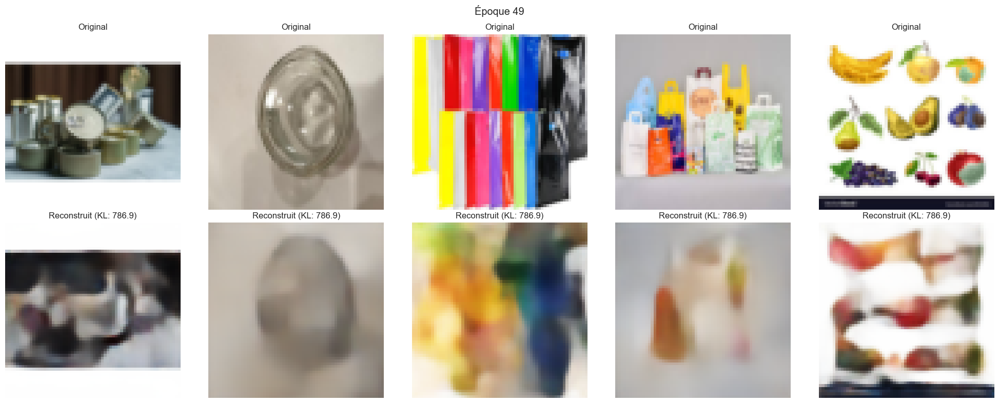

683/683 ━━━━━━━━━━━━━━━━━━━━ 504s 652ms/step - kl_loss: 786.8840 - loss: 5655.9937 - recon_loss: 5648.1260 - val_kl_loss: 770.9510 - val_loss: 5952.4937 - val_recon_loss: 5944.7847 - learning_rate: 2.5000e-04
Epoch 50/175
683/683 ━━━━━━━━━━━━━━━━━━━━ 0s 640ms/step - kl_loss: 788.4047 - loss: 5635.5220 - recon_loss: 5627.6401
Epoch 50: val_recon_loss did not improve from 5926.72656


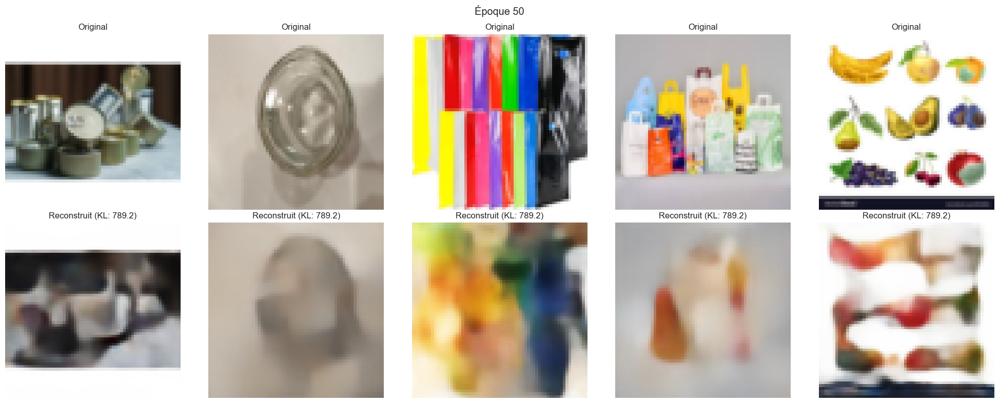

683/683 ━━━━━━━━━━━━━━━━━━━━ 458s 670ms/step - kl_loss: 789.1926 - loss: 5655.2334 - recon_loss: 5647.3481 - val_kl_loss: 779.6639 - val_loss: 5950.6001 - val_recon_loss: 5942.8032 - learning_rate: 2.5000e-04
Epoch 51/175
683/683 ━━━━━━━━━━━━━━━━━━━━ 0s 648ms/step - kl_loss: 791.5198 - loss: 5648.1602 - recon_loss: 5640.2461
Epoch 51: val_recon_loss did not improve from 5926.72656


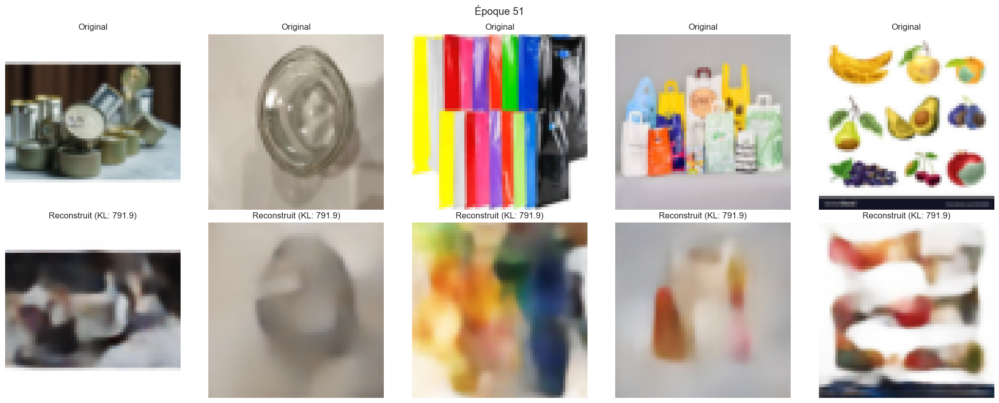

683/683 ━━━━━━━━━━━━━━━━━━━━ 460s 673ms/step - kl_loss: 791.8963 - loss: 5654.4600 - recon_loss: 5646.5449 - val_kl_loss: 780.9813 - val_loss: 5950.3179 - val_recon_loss: 5942.5088 - learning_rate: 2.5000e-04
Epoch 52/175
683/683 ━━━━━━━━━━━━━━━━━━━━ 0s 646ms/step - kl_loss: 791.8969 - loss: 5638.7754 - recon_loss: 5630.8560
Epoch 52: val_recon_loss did not improve from 5926.72656

Epoch 52: ReduceLROnPlateau reducing learning rate to 0.0001250000059371814.


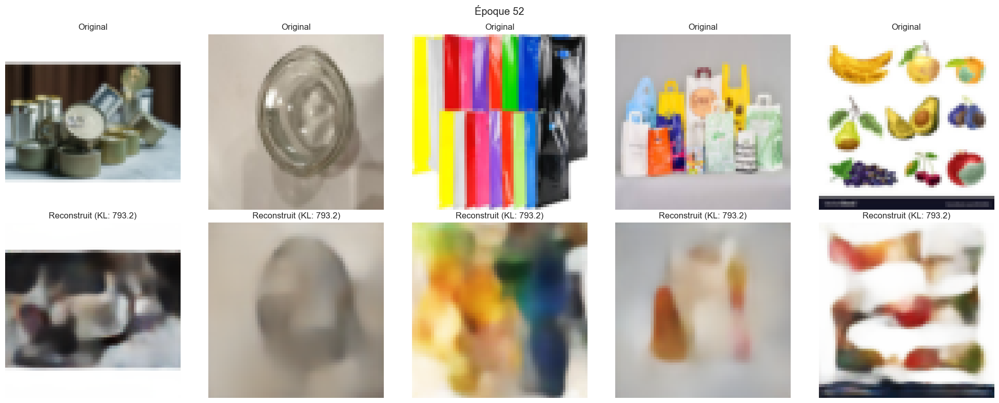

683/683 ━━━━━━━━━━━━━━━━━━━━ 459s 672ms/step - kl_loss: 793.2296 - loss: 5653.4365 - recon_loss: 5645.5049 - val_kl_loss: 783.0232 - val_loss: 5948.9438 - val_recon_loss: 5941.1133 - learning_rate: 2.5000e-04
Epoch 53/175
683/683 ━━━━━━━━━━━━━━━━━━━━ 0s 656ms/step - kl_loss: 795.0939 - loss: 5650.0884 - recon_loss: 5642.1367
Epoch 53: val_recon_loss did not improve from 5926.72656


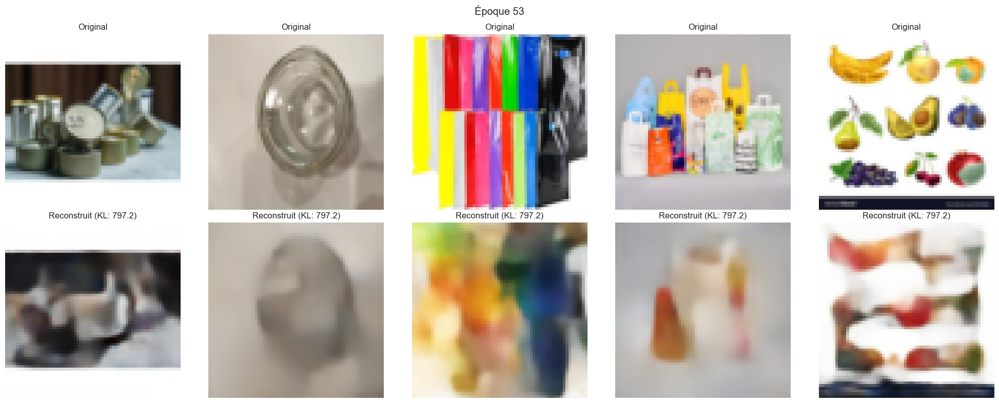

683/683 ━━━━━━━━━━━━━━━━━━━━ 465s 681ms/step - kl_loss: 797.2327 - loss: 5649.1504 - recon_loss: 5641.1772 - val_kl_loss: 784.0892 - val_loss: 5955.0337 - val_recon_loss: 5947.1929 - learning_rate: 1.2500e-04
Epoch 54/175
683/683 ━━━━━━━━━━━━━━━━━━━━ 0s 643ms/step - kl_loss: 799.6463 - loss: 5639.1235 - recon_loss: 5631.1270
Epoch 54: val_recon_loss did not improve from 5926.72656


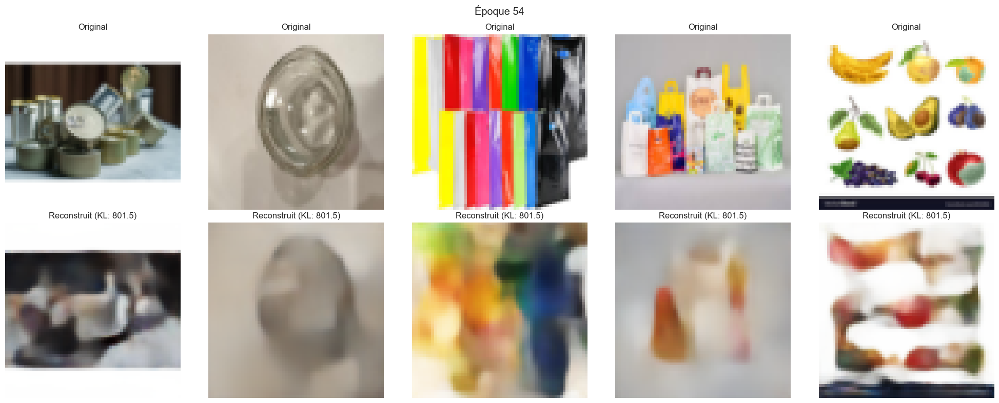

683/683 ━━━━━━━━━━━━━━━━━━━━ 457s 669ms/step - kl_loss: 801.5379 - loss: 5646.8916 - recon_loss: 5638.8794 - val_kl_loss: 788.4333 - val_loss: 5956.6499 - val_recon_loss: 5948.7651 - learning_rate: 1.2500e-04
Epoch 55/175
683/683 ━━━━━━━━━━━━━━━━━━━━ 0s 640ms/step - kl_loss: 806.9651 - loss: 5633.2290 - recon_loss: 5625.1602
Epoch 55: val_recon_loss did not improve from 5926.72656


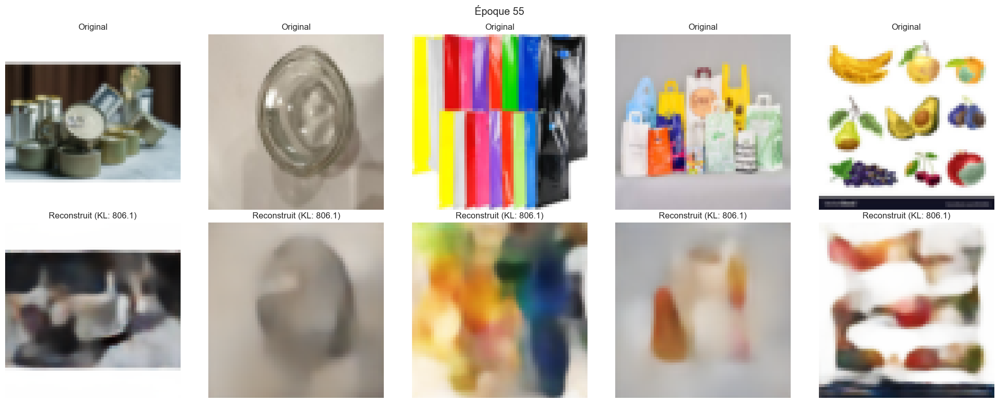

683/683 ━━━━━━━━━━━━━━━━━━━━ 454s 665ms/step - kl_loss: 806.0811 - loss: 5646.5078 - recon_loss: 5638.4512 - val_kl_loss: 790.1790 - val_loss: 5956.6343 - val_recon_loss: 5948.7324 - learning_rate: 1.2500e-04
Epoch 56/175
683/683 ━━━━━━━━━━━━━━━━━━━━ 0s 644ms/step - kl_loss: 807.8502 - loss: 5621.6890 - recon_loss: 5613.6108
Epoch 56: val_recon_loss did not improve from 5926.72656


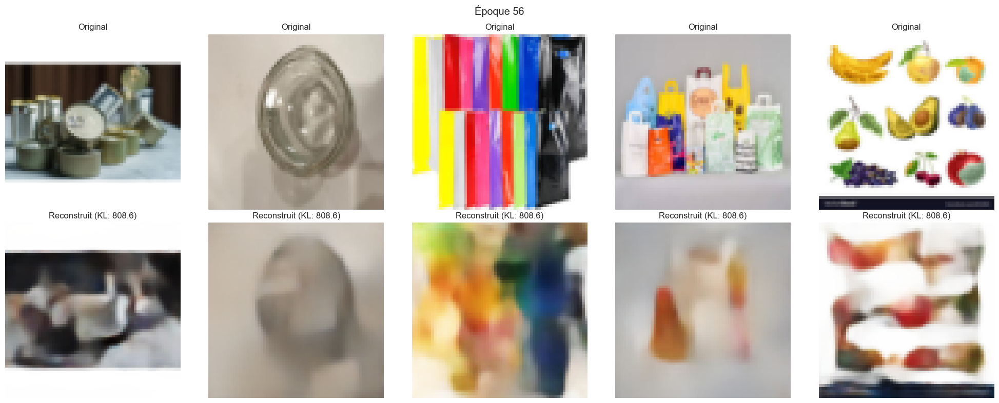

683/683 ━━━━━━━━━━━━━━━━━━━━ 457s 669ms/step - kl_loss: 808.5845 - loss: 5645.4966 - recon_loss: 5637.4106 - val_kl_loss: 795.7925 - val_loss: 5956.8735 - val_recon_loss: 5948.9136 - learning_rate: 1.2500e-04
Epoch 57/175
683/683 ━━━━━━━━━━━━━━━━━━━━ 0s 644ms/step - kl_loss: 809.8381 - loss: 5661.7388 - recon_loss: 5653.6406
Epoch 57: val_recon_loss did not improve from 5926.72656


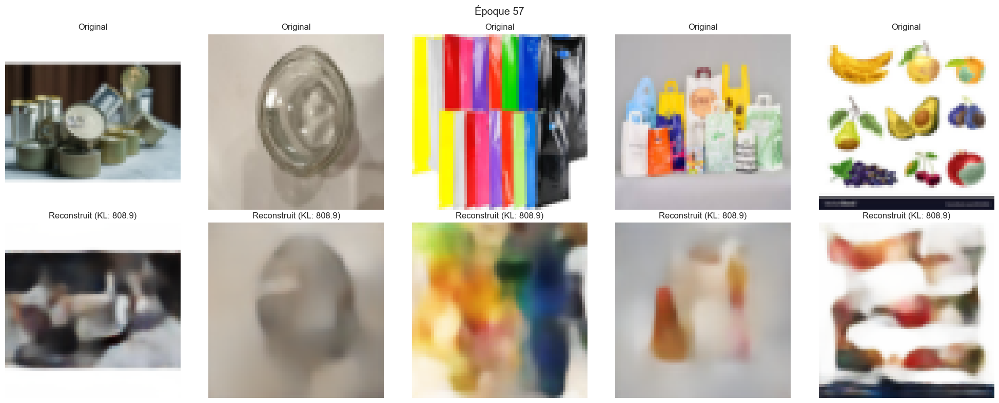

683/683 ━━━━━━━━━━━━━━━━━━━━ 457s 669ms/step - kl_loss: 808.9291 - loss: 5645.3652 - recon_loss: 5637.2769 - val_kl_loss: 800.4892 - val_loss: 5955.3579 - val_recon_loss: 5947.3530 - learning_rate: 1.2500e-04
Epoch 58/175
683/683 ━━━━━━━━━━━━━━━━━━━━ 0s 631ms/step - kl_loss: 811.5324 - loss: 5661.0142 - recon_loss: 5652.9004
Epoch 58: val_recon_loss did not improve from 5926.72656


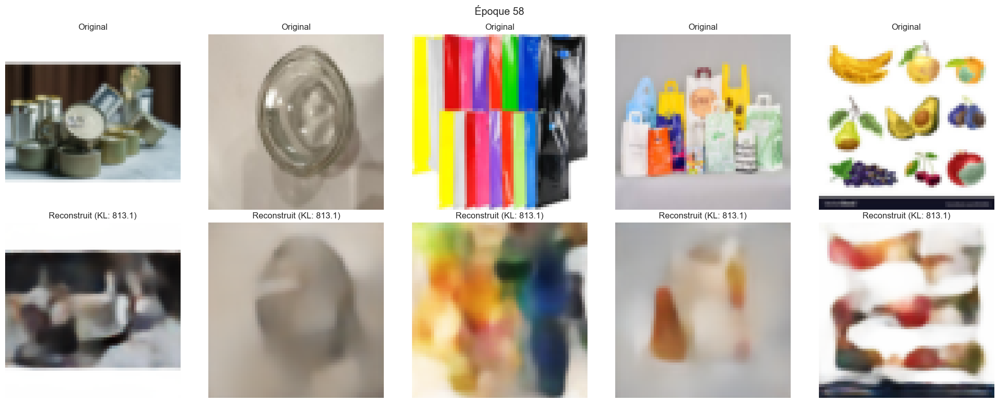

683/683 ━━━━━━━━━━━━━━━━━━━━ 494s 657ms/step - kl_loss: 813.1118 - loss: 5644.9487 - recon_loss: 5636.8213 - val_kl_loss: 806.6960 - val_loss: 5957.7153 - val_recon_loss: 5949.6489 - learning_rate: 1.2500e-04
Epoch 59/175
683/683 ━━━━━━━━━━━━━━━━━━━━ 0s 646ms/step - kl_loss: 815.2883 - loss: 5623.3501 - recon_loss: 5615.1948
Epoch 59: val_recon_loss did not improve from 5926.72656


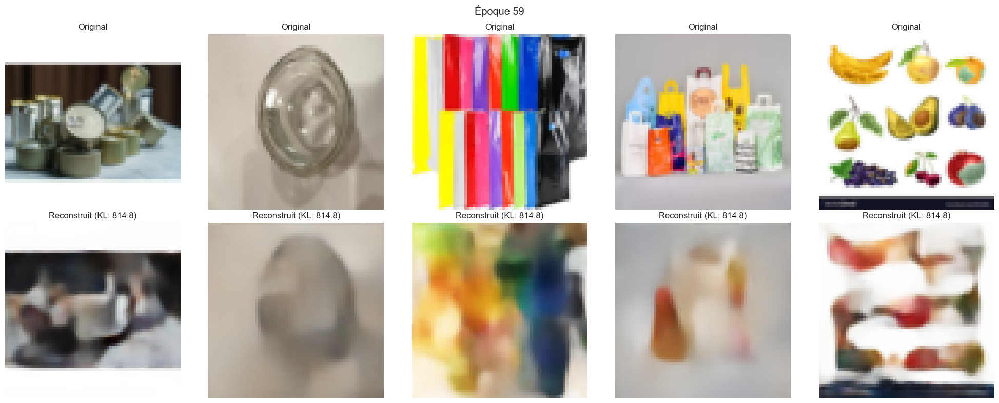

683/683 ━━━━━━━━━━━━━━━━━━━━ 458s 671ms/step - kl_loss: 814.7886 - loss: 5644.1602 - recon_loss: 5636.0083 - val_kl_loss: 807.2477 - val_loss: 5959.5015 - val_recon_loss: 5951.4292 - learning_rate: 1.2500e-04
Epoch 60/175
683/683 ━━━━━━━━━━━━━━━━━━━━ 0s 649ms/step - kl_loss: 816.5055 - loss: 5648.9609 - recon_loss: 5640.7959
Epoch 60: val_recon_loss did not improve from 5926.72656


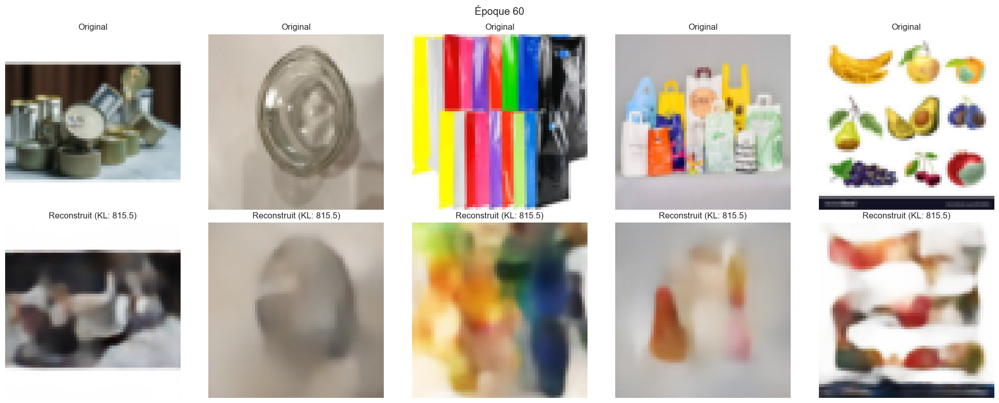

683/683 ━━━━━━━━━━━━━━━━━━━━ 461s 675ms/step - kl_loss: 815.5023 - loss: 5643.9688 - recon_loss: 5635.8140 - val_kl_loss: 804.2051 - val_loss: 5956.0835 - val_recon_loss: 5948.0430 - learning_rate: 1.2500e-04
Epoch 61/175
683/683 ━━━━━━━━━━━━━━━━━━━━ 0s 649ms/step - kl_loss: 818.0899 - loss: 5643.6313 - recon_loss: 5635.4517
Epoch 61: val_recon_loss did not improve from 5926.72656


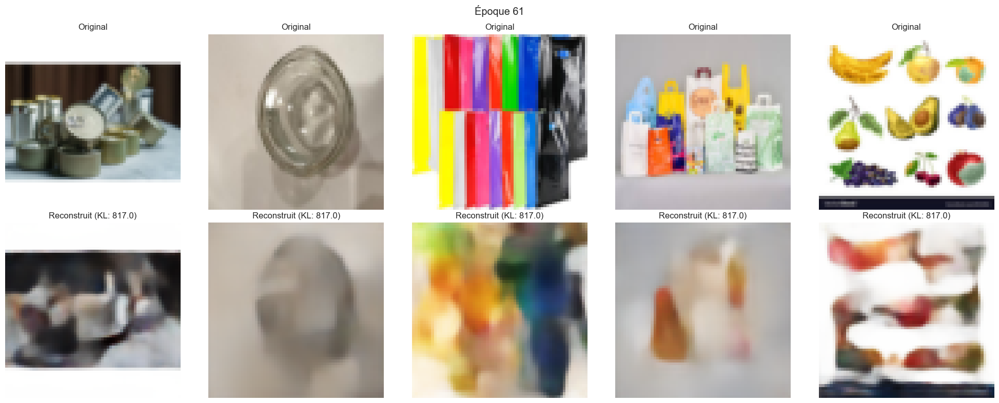

683/683 ━━━━━━━━━━━━━━━━━━━━ 461s 674ms/step - kl_loss: 816.9817 - loss: 5643.7495 - recon_loss: 5635.5796 - val_kl_loss: 808.9725 - val_loss: 5959.1523 - val_recon_loss: 5951.0620 - learning_rate: 1.2500e-04
Epoch 62/175
683/683 ━━━━━━━━━━━━━━━━━━━━ 0s 647ms/step - kl_loss: 820.7214 - loss: 5666.9097 - recon_loss: 5658.7031
Epoch 62: val_recon_loss did not improve from 5926.72656

Epoch 62: ReduceLROnPlateau reducing learning rate to 6.25000029685907e-05.


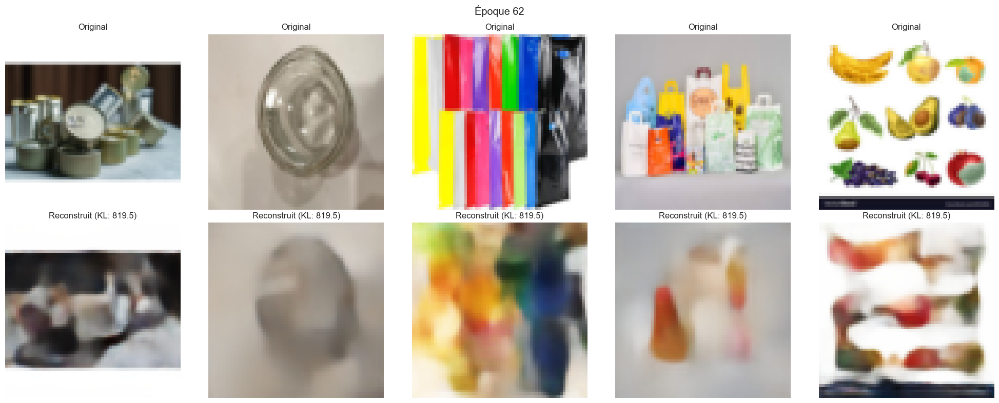

683/683 ━━━━━━━━━━━━━━━━━━━━ 460s 673ms/step - kl_loss: 819.4780 - loss: 5643.1060 - recon_loss: 5634.9150 - val_kl_loss: 806.4572 - val_loss: 5955.2808 - val_recon_loss: 5947.2183 - learning_rate: 1.2500e-04
Epoch 63/175
683/683 ━━━━━━━━━━━━━━━━━━━━ 0s 642ms/step - kl_loss: 819.1589 - loss: 5647.6875 - recon_loss: 5639.4941
Epoch 63: val_recon_loss did not improve from 5926.72656


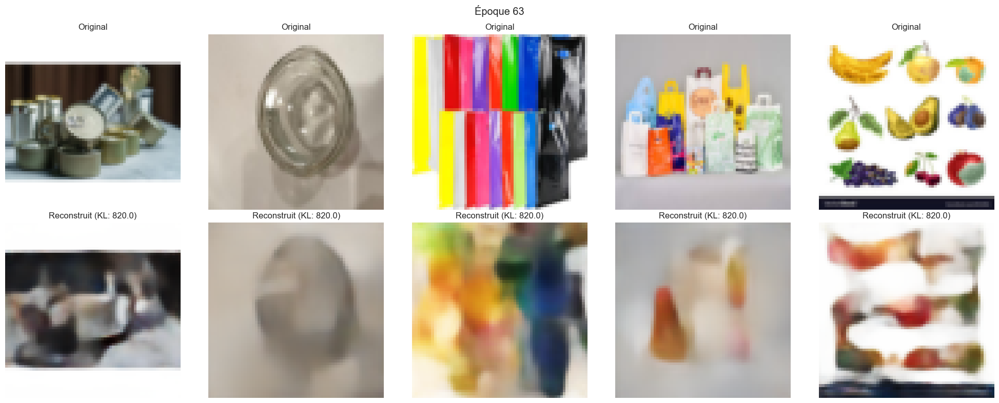

683/683 ━━━━━━━━━━━━━━━━━━━━ 456s 667ms/step - kl_loss: 820.0255 - loss: 5641.0068 - recon_loss: 5632.8066 - val_kl_loss: 808.5465 - val_loss: 5956.2031 - val_recon_loss: 5948.1162 - learning_rate: 6.2500e-05
Epoch 64/175
683/683 ━━━━━━━━━━━━━━━━━━━━ 0s 631ms/step - kl_loss: 825.1637 - loss: 5599.9009 - recon_loss: 5591.6484
Epoch 64: val_recon_loss did not improve from 5926.72656


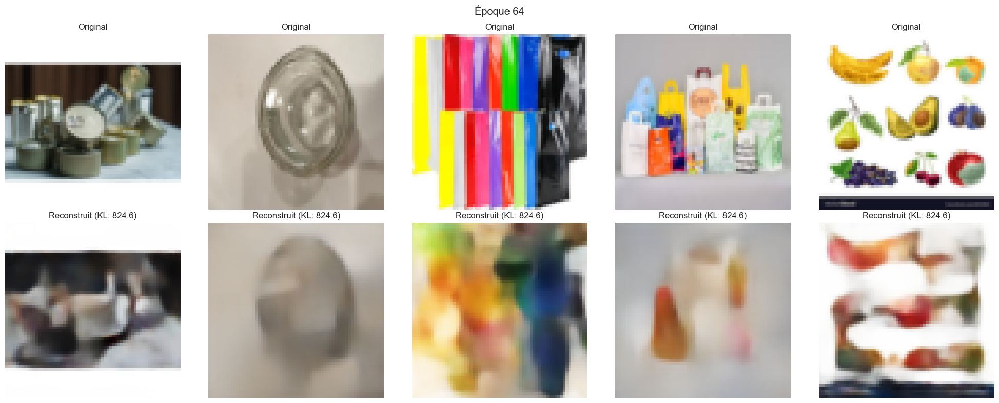

683/683 ━━━━━━━━━━━━━━━━━━━━ 494s 656ms/step - kl_loss: 824.5591 - loss: 5640.1689 - recon_loss: 5631.9204 - val_kl_loss: 814.2893 - val_loss: 5957.0562 - val_recon_loss: 5948.9121 - learning_rate: 6.2500e-05
Epoch 65/175
683/683 ━━━━━━━━━━━━━━━━━━━━ 0s 652ms/step - kl_loss: 824.3162 - loss: 5630.2485 - recon_loss: 5622.0059
Epoch 65: val_recon_loss did not improve from 5926.72656


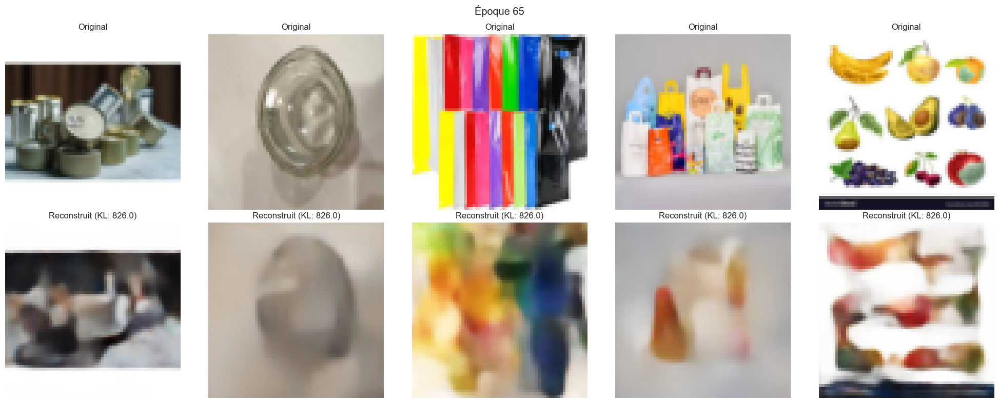

683/683 ━━━━━━━━━━━━━━━━━━━━ 463s 677ms/step - kl_loss: 825.9736 - loss: 5639.9429 - recon_loss: 5631.6841 - val_kl_loss: 814.7672 - val_loss: 5956.8423 - val_recon_loss: 5948.6943 - learning_rate: 6.2500e-05
Epoch 66/175
683/683 ━━━━━━━━━━━━━━━━━━━━ 0s 629ms/step - kl_loss: 829.0420 - loss: 5622.4585 - recon_loss: 5614.1699
Epoch 66: val_recon_loss did not improve from 5926.72656


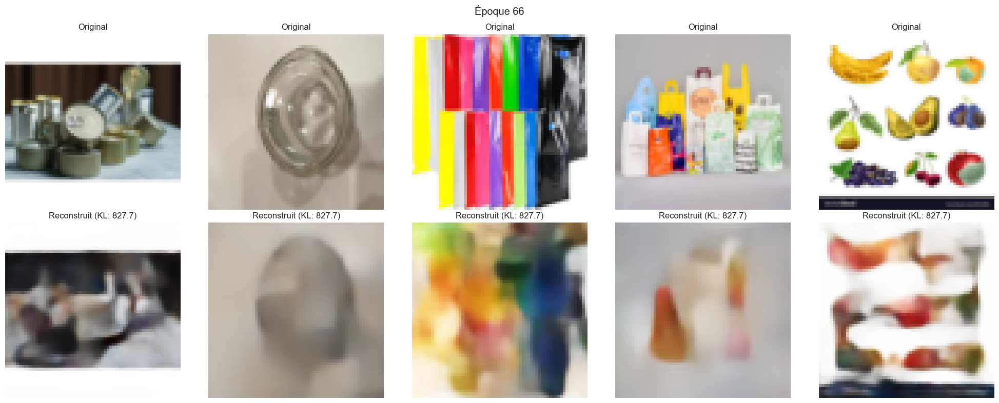

683/683 ━━━━━━━━━━━━━━━━━━━━ 486s 654ms/step - kl_loss: 827.7260 - loss: 5639.6035 - recon_loss: 5631.3267 - val_kl_loss: 812.9990 - val_loss: 5956.8164 - val_recon_loss: 5948.6851 - learning_rate: 6.2500e-05
Epoch 67/175
683/683 ━━━━━━━━━━━━━━━━━━━━ 0s 639ms/step - kl_loss: 827.5757 - loss: 5664.4775 - recon_loss: 5656.2002
Epoch 67: val_recon_loss did not improve from 5926.72656


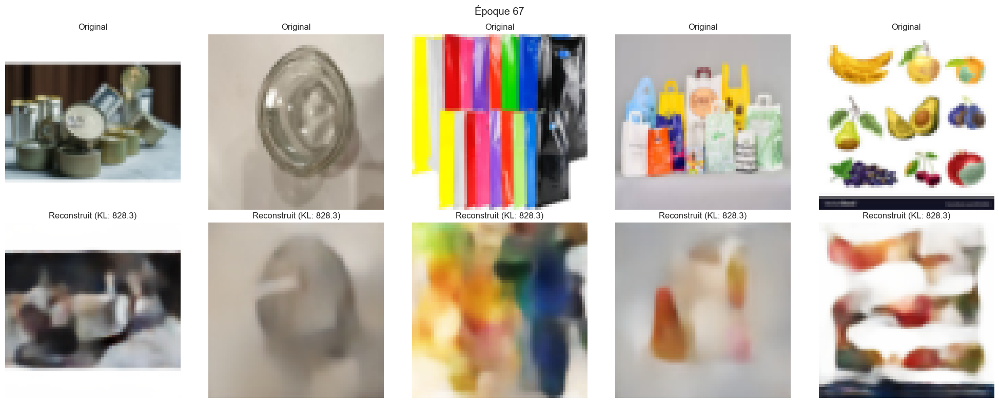

683/683 ━━━━━━━━━━━━━━━━━━━━ 509s 664ms/step - kl_loss: 828.3113 - loss: 5639.2007 - recon_loss: 5630.9126 - val_kl_loss: 820.7828 - val_loss: 5959.3892 - val_recon_loss: 5951.1816 - learning_rate: 6.2500e-05
Epoch 68/175
683/683 ━━━━━━━━━━━━━━━━━━━━ 0s 654ms/step - kl_loss: 830.9997 - loss: 5625.4360 - recon_loss: 5617.1240
Epoch 68: val_recon_loss did not improve from 5926.72656


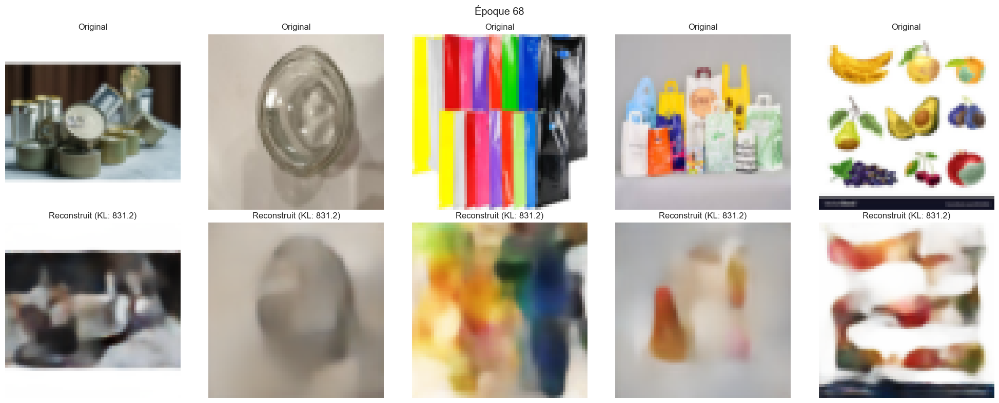

683/683 ━━━━━━━━━━━━━━━━━━━━ 464s 679ms/step - kl_loss: 831.1677 - loss: 5639.1240 - recon_loss: 5630.8091 - val_kl_loss: 818.3800 - val_loss: 5957.8906 - val_recon_loss: 5949.7075 - learning_rate: 6.2500e-05
Epoch 69/175
683/683 ━━━━━━━━━━━━━━━━━━━━ 0s 652ms/step - kl_loss: 830.9481 - loss: 5650.8960 - recon_loss: 5642.5845
Epoch 69: val_recon_loss did not improve from 5926.72656


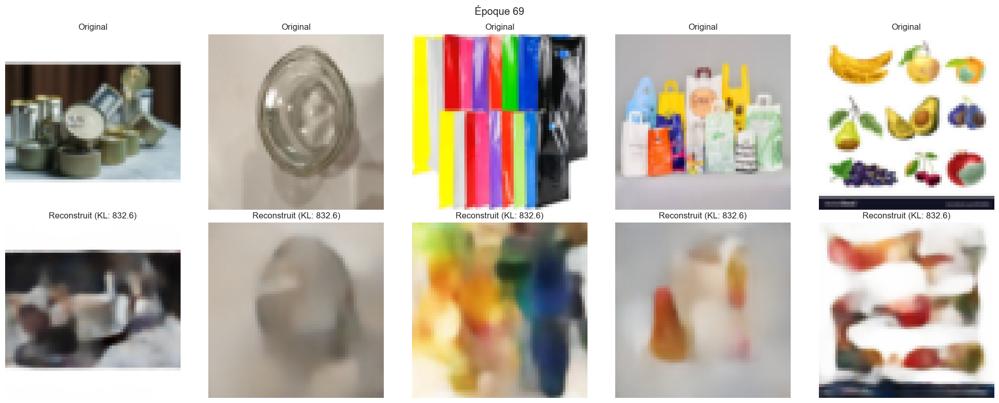

683/683 ━━━━━━━━━━━━━━━━━━━━ 463s 677ms/step - kl_loss: 832.5800 - loss: 5638.6924 - recon_loss: 5630.3647 - val_kl_loss: 820.9134 - val_loss: 5959.8677 - val_recon_loss: 5951.6582 - learning_rate: 6.2500e-05
Epoch 70/175
683/683 ━━━━━━━━━━━━━━━━━━━━ 0s 651ms/step - kl_loss: 834.1242 - loss: 5596.7104 - recon_loss: 5588.3687
Epoch 70: val_recon_loss did not improve from 5926.72656


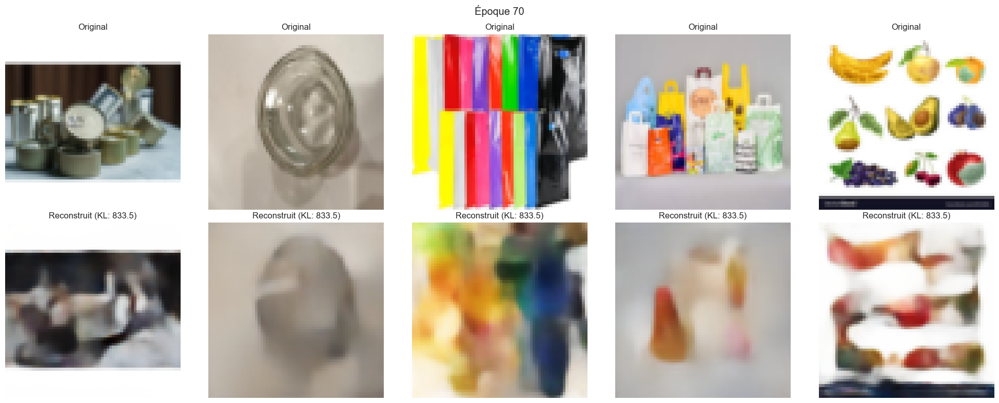

683/683 ━━━━━━━━━━━━━━━━━━━━ 461s 675ms/step - kl_loss: 833.4984 - loss: 5638.4497 - recon_loss: 5630.1128 - val_kl_loss: 822.4305 - val_loss: 5957.4697 - val_recon_loss: 5949.2461 - learning_rate: 6.2500e-05
Epoch 71/175
683/683 ━━━━━━━━━━━━━━━━━━━━ 0s 647ms/step - kl_loss: 833.1711 - loss: 5623.5303 - recon_loss: 5615.2007
Epoch 71: val_recon_loss did not improve from 5926.72656


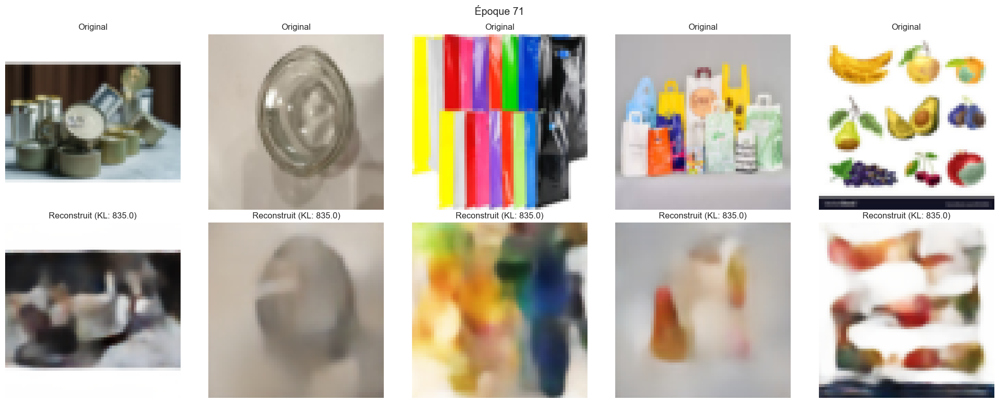

683/683 ━━━━━━━━━━━━━━━━━━━━ 459s 672ms/step - kl_loss: 835.0231 - loss: 5637.9980 - recon_loss: 5629.6514 - val_kl_loss: 822.7149 - val_loss: 5958.0586 - val_recon_loss: 5949.8311 - learning_rate: 6.2500e-05
Epoch 72/175
683/683 ━━━━━━━━━━━━━━━━━━━━ 0s 642ms/step - kl_loss: 835.2431 - loss: 5623.9141 - recon_loss: 5615.5615
Epoch 72: val_recon_loss did not improve from 5926.72656

Epoch 72: ReduceLROnPlateau reducing learning rate to 3.125000148429535e-05.


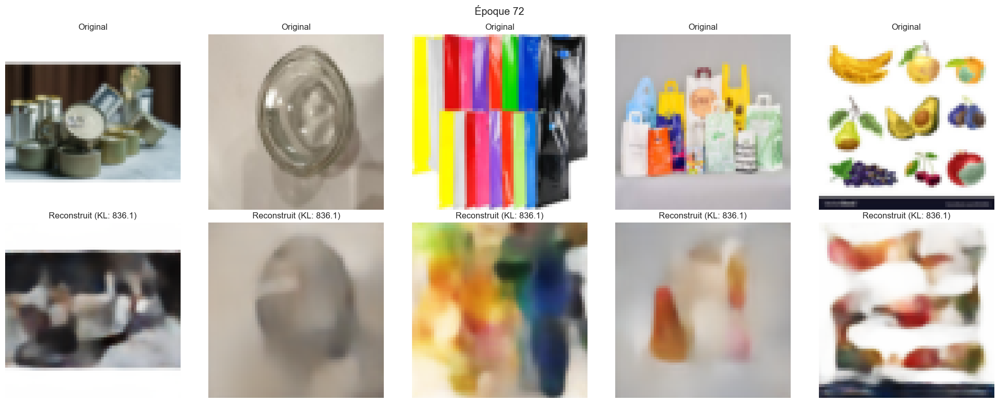

683/683 ━━━━━━━━━━━━━━━━━━━━ 455s 667ms/step - kl_loss: 836.0905 - loss: 5638.0269 - recon_loss: 5629.6675 - val_kl_loss: 825.7371 - val_loss: 5960.8179 - val_recon_loss: 5952.5605 - learning_rate: 6.2500e-05
Epoch 73/175
683/683 ━━━━━━━━━━━━━━━━━━━━ 0s 643ms/step - kl_loss: 838.5996 - loss: 5607.4546 - recon_loss: 5599.0664
Epoch 73: val_recon_loss did not improve from 5926.72656


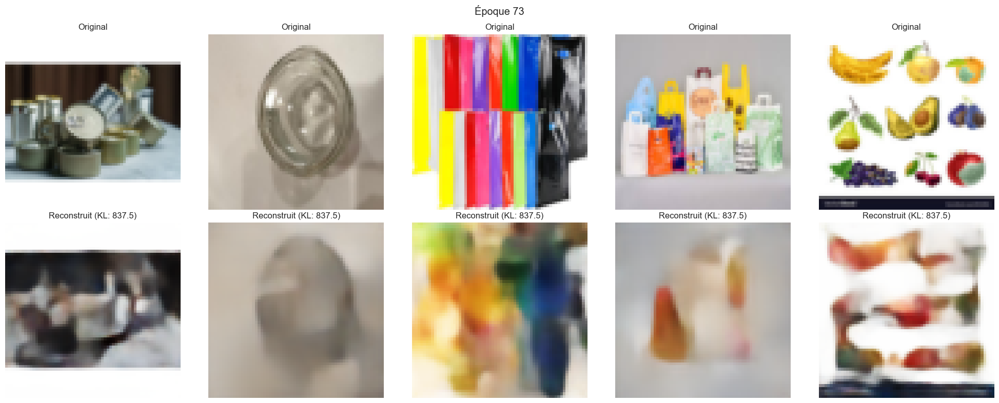

683/683 ━━━━━━━━━━━━━━━━━━━━ 456s 668ms/step - kl_loss: 837.4714 - loss: 5636.9893 - recon_loss: 5628.6138 - val_kl_loss: 827.4094 - val_loss: 5959.5430 - val_recon_loss: 5951.2720 - learning_rate: 3.1250e-05
Epoch 74/175
683/683 ━━━━━━━━━━━━━━━━━━━━ 0s 649ms/step - kl_loss: 836.9300 - loss: 5638.2637 - recon_loss: 5629.8950
Epoch 74: val_recon_loss did not improve from 5926.72656


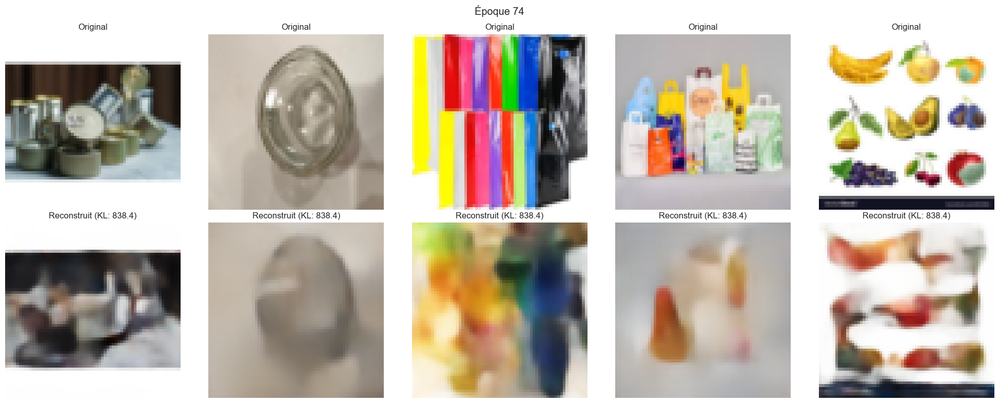

683/683 ━━━━━━━━━━━━━━━━━━━━ 460s 674ms/step - kl_loss: 838.3851 - loss: 5636.3296 - recon_loss: 5627.9463 - val_kl_loss: 829.6985 - val_loss: 5960.9521 - val_recon_loss: 5952.6548 - learning_rate: 3.1250e-05
Epoch 75/175
683/683 ━━━━━━━━━━━━━━━━━━━━ 0s 644ms/step - kl_loss: 839.4075 - loss: 5642.5098 - recon_loss: 5634.1147
Epoch 75: val_recon_loss did not improve from 5926.72656


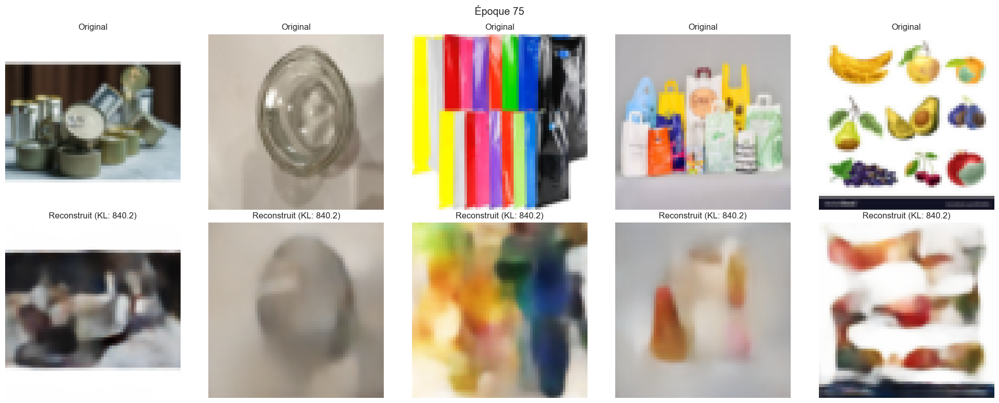

683/683 ━━━━━━━━━━━━━━━━━━━━ 457s 670ms/step - kl_loss: 840.1685 - loss: 5636.3833 - recon_loss: 5627.9800 - val_kl_loss: 831.2842 - val_loss: 5958.9619 - val_recon_loss: 5950.6484 - learning_rate: 3.1250e-05
Epoch 76/175
683/683 ━━━━━━━━━━━━━━━━━━━━ 0s 638ms/step - kl_loss: 840.7573 - loss: 5627.6030 - recon_loss: 5619.1958
Epoch 76: val_recon_loss did not improve from 5926.72656


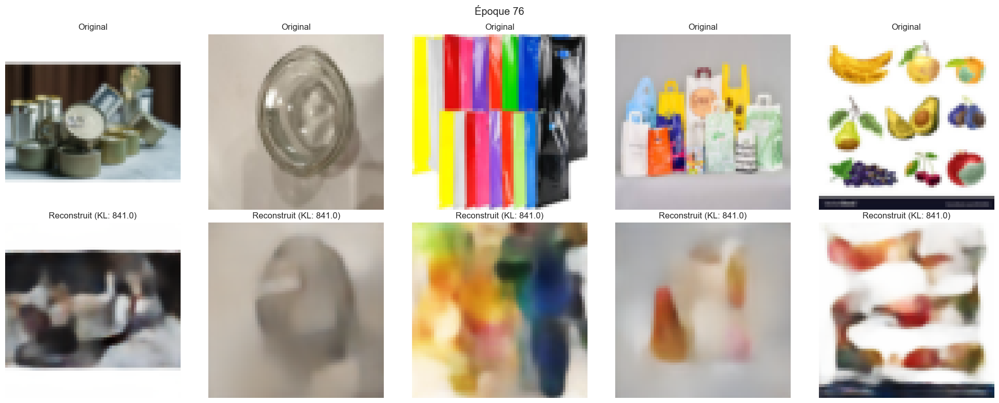

683/683 ━━━━━━━━━━━━━━━━━━━━ 497s 663ms/step - kl_loss: 841.0141 - loss: 5636.2202 - recon_loss: 5627.8105 - val_kl_loss: 828.9052 - val_loss: 5961.0063 - val_recon_loss: 5952.7163 - learning_rate: 3.1250e-05
Epoch 77/175
683/683 ━━━━━━━━━━━━━━━━━━━━ 0s 646ms/step - kl_loss: 844.7562 - loss: 5595.9736 - recon_loss: 5587.5283
Epoch 77: val_recon_loss did not improve from 5926.72656


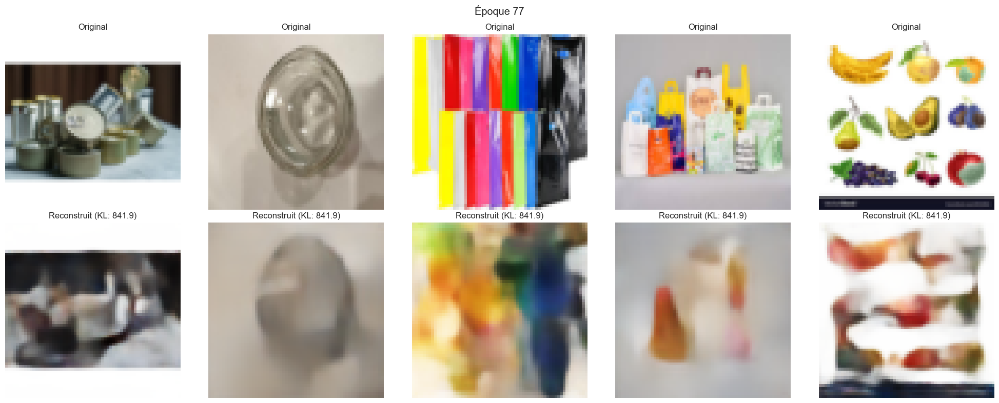

683/683 ━━━━━━━━━━━━━━━━━━━━ 458s 671ms/step - kl_loss: 841.8953 - loss: 5635.5488 - recon_loss: 5627.1323 - val_kl_loss: 830.8503 - val_loss: 5960.5811 - val_recon_loss: 5952.2734 - learning_rate: 3.1250e-05
Epoch 78/175
683/683 ━━━━━━━━━━━━━━━━━━━━ 0s 653ms/step - kl_loss: 841.5023 - loss: 5627.0400 - recon_loss: 5618.6255
Epoch 78: val_recon_loss did not improve from 5926.72656


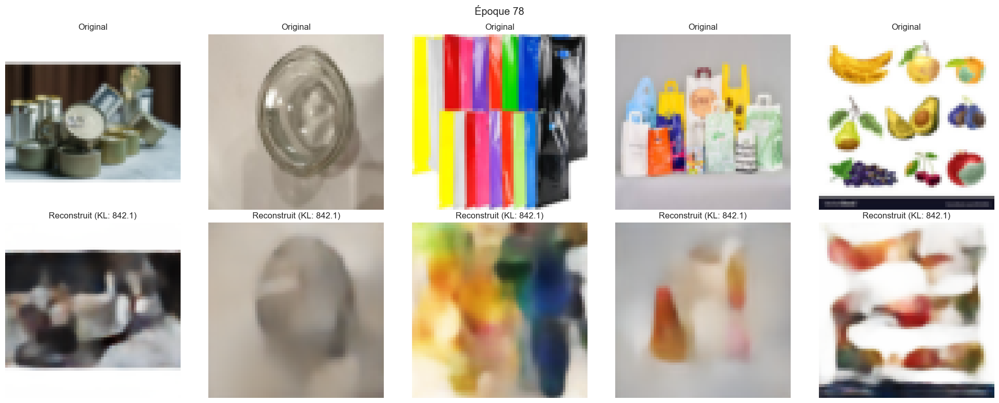

683/683 ━━━━━━━━━━━━━━━━━━━━ 463s 678ms/step - kl_loss: 842.0735 - loss: 5636.1748 - recon_loss: 5627.7554 - val_kl_loss: 831.6617 - val_loss: 5959.3667 - val_recon_loss: 5951.0498 - learning_rate: 3.1250e-05
Epoch 79/175
683/683 ━━━━━━━━━━━━━━━━━━━━ 0s 660ms/step - kl_loss: 844.8680 - loss: 5621.9976 - recon_loss: 5613.5474
Epoch 79: val_recon_loss did not improve from 5926.72656


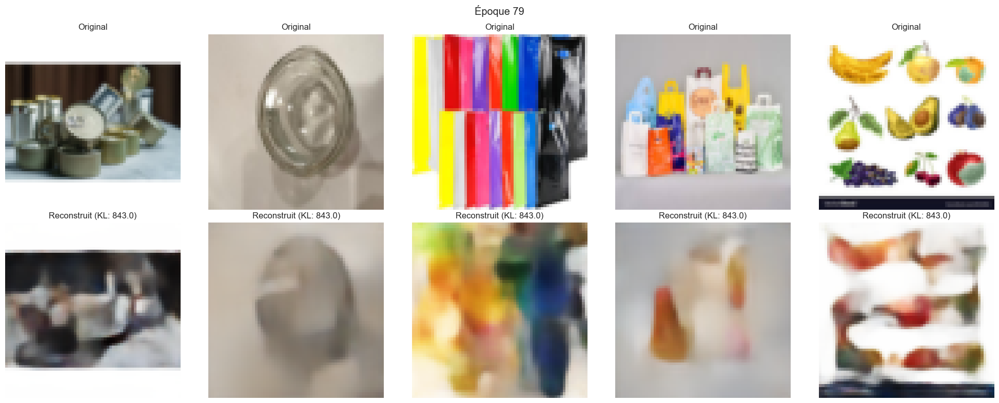

683/683 ━━━━━━━━━━━━━━━━━━━━ 468s 685ms/step - kl_loss: 842.9712 - loss: 5635.7393 - recon_loss: 5627.3125 - val_kl_loss: 832.5460 - val_loss: 5960.2944 - val_recon_loss: 5951.9692 - learning_rate: 3.1250e-05
Epoch 80/175
683/683 ━━━━━━━━━━━━━━━━━━━━ 0s 654ms/step - kl_loss: 843.2542 - loss: 5621.8452 - recon_loss: 5613.4131
Epoch 80: val_recon_loss did not improve from 5926.72656


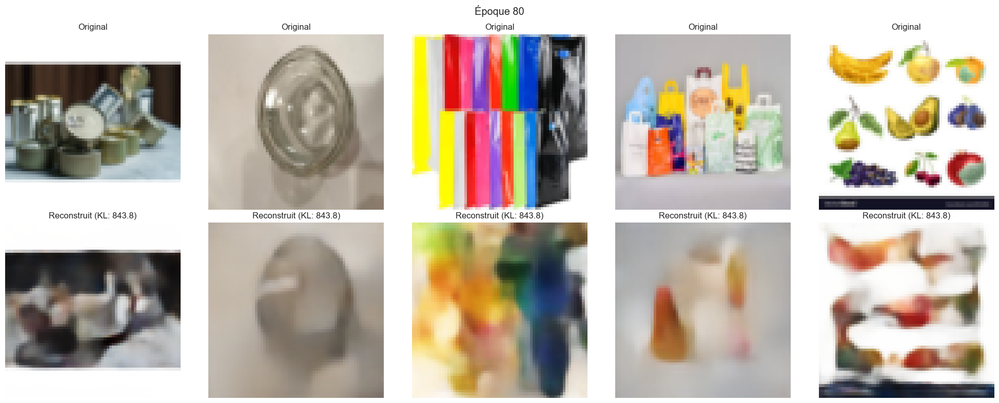

683/683 ━━━━━━━━━━━━━━━━━━━━ 464s 679ms/step - kl_loss: 843.7568 - loss: 5635.5225 - recon_loss: 5627.0845 - val_kl_loss: 832.4607 - val_loss: 5961.2124 - val_recon_loss: 5952.8867 - learning_rate: 3.1250e-05
Epoch 81/175
683/683 ━━━━━━━━━━━━━━━━━━━━ 0s 648ms/step - kl_loss: 844.7356 - loss: 5647.8228 - recon_loss: 5639.3745
Epoch 81: val_recon_loss did not improve from 5926.72656


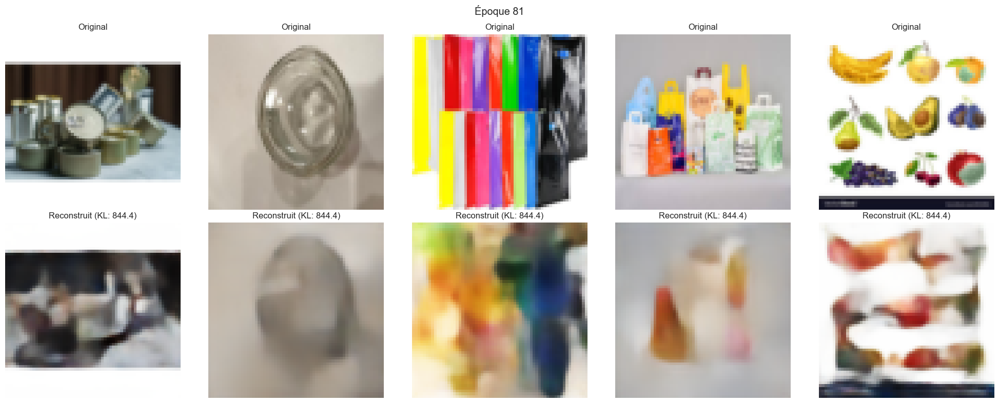

683/683 ━━━━━━━━━━━━━━━━━━━━ 460s 673ms/step - kl_loss: 844.4094 - loss: 5635.6274 - recon_loss: 5627.1782 - val_kl_loss: 830.8576 - val_loss: 5962.2764 - val_recon_loss: 5953.9673 - learning_rate: 3.1250e-05
Epoch 82/175
683/683 ━━━━━━━━━━━━━━━━━━━━ 0s 631ms/step - kl_loss: 844.9748 - loss: 5637.6885 - recon_loss: 5629.2427
Epoch 82: val_recon_loss did not improve from 5926.72656

Epoch 82: ReduceLROnPlateau reducing learning rate to 1.5625000742147677e-05.


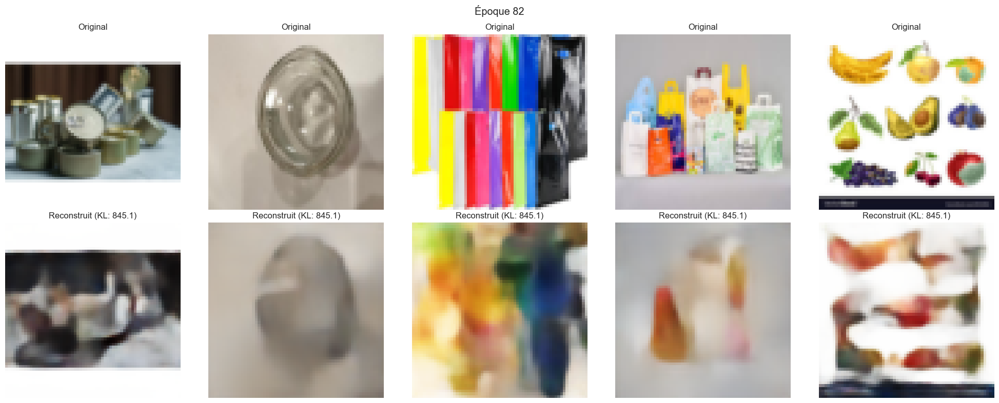

683/683 ━━━━━━━━━━━━━━━━━━━━ 490s 656ms/step - kl_loss: 845.0854 - loss: 5635.3638 - recon_loss: 5626.9204 - val_kl_loss: 833.5546 - val_loss: 5960.3193 - val_recon_loss: 5951.9834 - learning_rate: 3.1250e-05
Epoch 83/175
683/683 ━━━━━━━━━━━━━━━━━━━━ 0s 646ms/step - kl_loss: 846.6598 - loss: 5627.5332 - recon_loss: 5619.0640
Epoch 83: val_recon_loss did not improve from 5926.72656


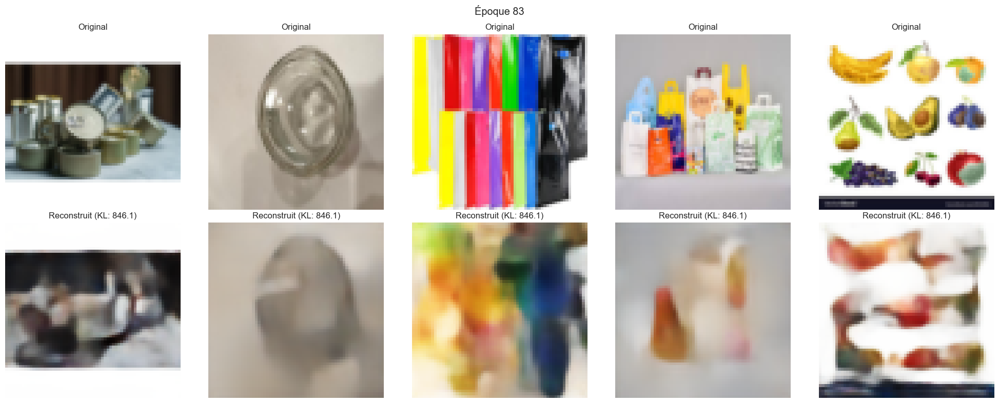

683/683 ━━━━━━━━━━━━━━━━━━━━ 459s 672ms/step - kl_loss: 846.0546 - loss: 5634.8066 - recon_loss: 5626.3369 - val_kl_loss: 835.6187 - val_loss: 5962.8037 - val_recon_loss: 5954.4487 - learning_rate: 1.5625e-05
Epoch 84/175
683/683 ━━━━━━━━━━━━━━━━━━━━ 0s 650ms/step - kl_loss: 847.1892 - loss: 5639.1548 - recon_loss: 5630.6836
Epoch 84: val_recon_loss did not improve from 5926.72656


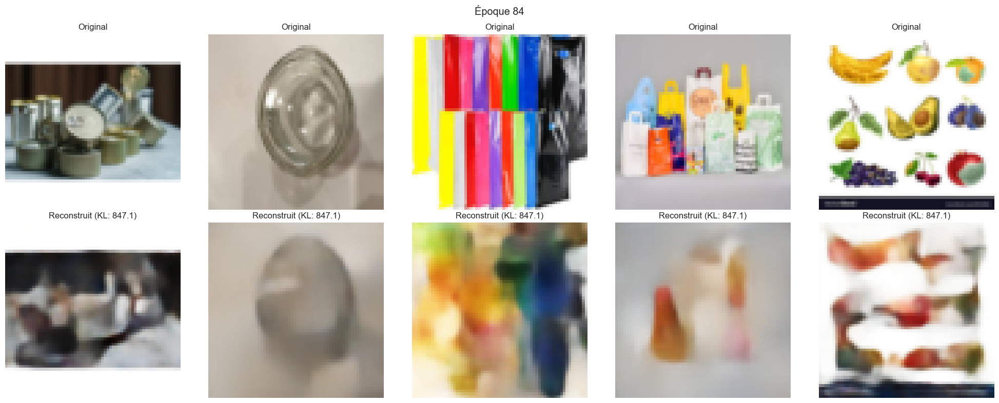

683/683 ━━━━━━━━━━━━━━━━━━━━ 461s 675ms/step - kl_loss: 847.0665 - loss: 5634.7759 - recon_loss: 5626.3047 - val_kl_loss: 834.9990 - val_loss: 5960.3457 - val_recon_loss: 5951.9985 - learning_rate: 1.5625e-05
Epoch 85/175
683/683 ━━━━━━━━━━━━━━━━━━━━ 0s 647ms/step - kl_loss: 845.4089 - loss: 5625.2217 - recon_loss: 5616.7695
Epoch 85: val_recon_loss did not improve from 5926.72656


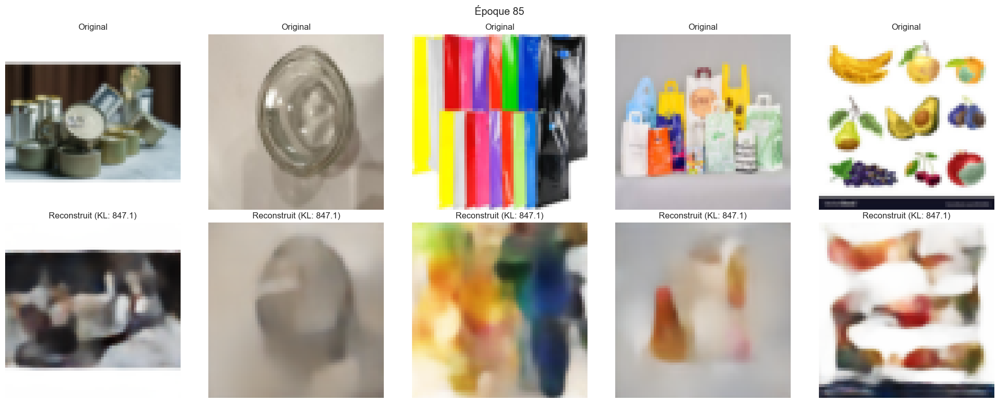

683/683 ━━━━━━━━━━━━━━━━━━━━ 459s 672ms/step - kl_loss: 847.1230 - loss: 5634.6553 - recon_loss: 5626.1875 - val_kl_loss: 834.8023 - val_loss: 5961.6460 - val_recon_loss: 5953.2983 - learning_rate: 1.5625e-05
Epoch 86/175
683/683 ━━━━━━━━━━━━━━━━━━━━ 0s 649ms/step - kl_loss: 848.2206 - loss: 5651.6895 - recon_loss: 5643.2090
Epoch 86: val_recon_loss did not improve from 5926.72656


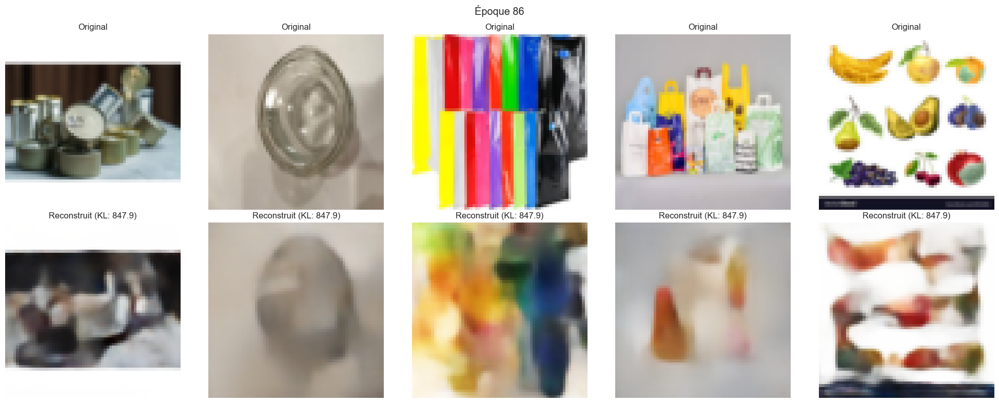

683/683 ━━━━━━━━━━━━━━━━━━━━ 461s 675ms/step - kl_loss: 847.9463 - loss: 5634.7686 - recon_loss: 5626.2915 - val_kl_loss: 835.7665 - val_loss: 5961.8999 - val_recon_loss: 5953.5425 - learning_rate: 1.5625e-05
Epoch 87/175
683/683 ━━━━━━━━━━━━━━━━━━━━ 0s 646ms/step - kl_loss: 846.9273 - loss: 5638.9448 - recon_loss: 5630.4746
Epoch 87: val_recon_loss did not improve from 5926.72656


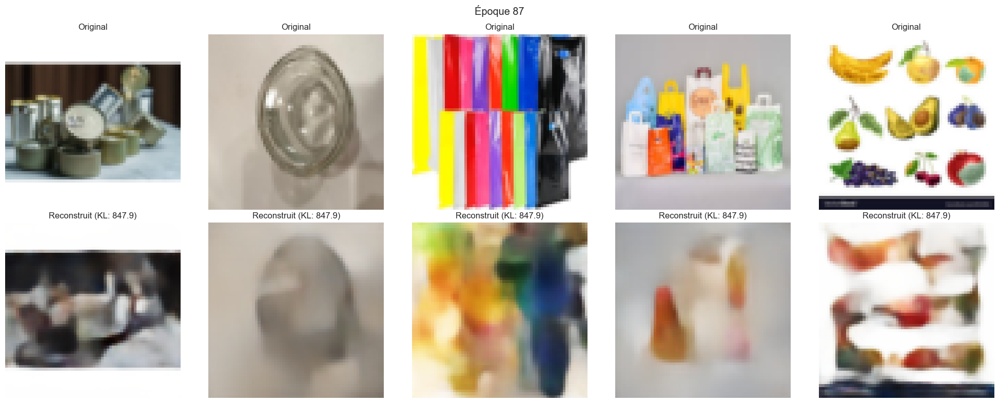

683/683 ━━━━━━━━━━━━━━━━━━━━ 458s 671ms/step - kl_loss: 847.8783 - loss: 5634.6846 - recon_loss: 5626.2070 - val_kl_loss: 836.6794 - val_loss: 5961.2886 - val_recon_loss: 5952.9233 - learning_rate: 1.5625e-05
Epoch 88/175
683/683 ━━━━━━━━━━━━━━━━━━━━ 0s 645ms/step - kl_loss: 849.4158 - loss: 5622.9043 - recon_loss: 5614.4116
Epoch 88: val_recon_loss did not improve from 5926.72656


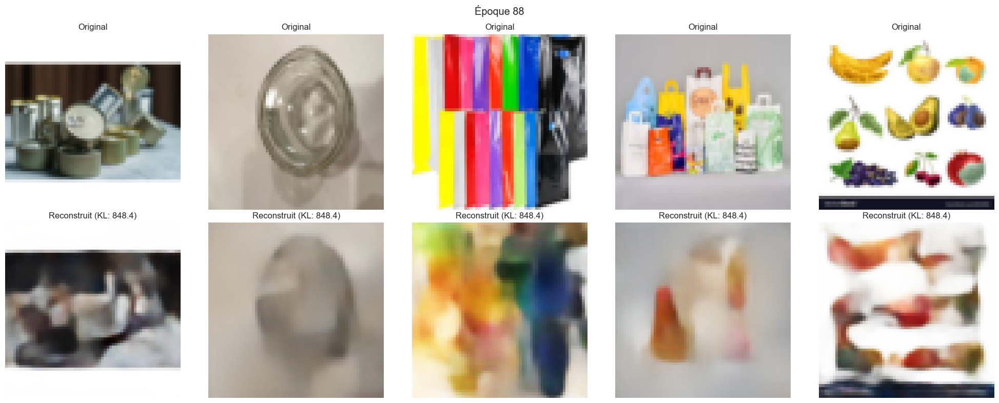

683/683 ━━━━━━━━━━━━━━━━━━━━ 458s 670ms/step - kl_loss: 848.3796 - loss: 5634.6377 - recon_loss: 5626.1543 - val_kl_loss: 835.8121 - val_loss: 5962.5171 - val_recon_loss: 5954.1592 - learning_rate: 1.5625e-05
Epoch 89/175
683/683 ━━━━━━━━━━━━━━━━━━━━ 0s 642ms/step - kl_loss: 848.4404 - loss: 5627.6309 - recon_loss: 5619.1465
Epoch 89: val_recon_loss did not improve from 5926.72656


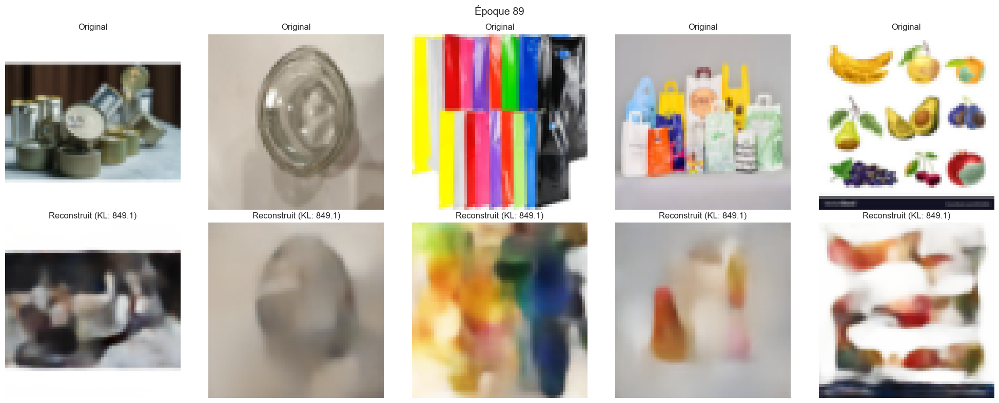

683/683 ━━━━━━━━━━━━━━━━━━━━ 456s 667ms/step - kl_loss: 849.1314 - loss: 5634.3672 - recon_loss: 5625.8770 - val_kl_loss: 838.4167 - val_loss: 5961.5845 - val_recon_loss: 5953.2007 - learning_rate: 1.5625e-05
Epoch 90/175
683/683 ━━━━━━━━━━━━━━━━━━━━ 0s 643ms/step - kl_loss: 848.9353 - loss: 5626.7612 - recon_loss: 5618.2710
Epoch 90: val_recon_loss did not improve from 5926.72656


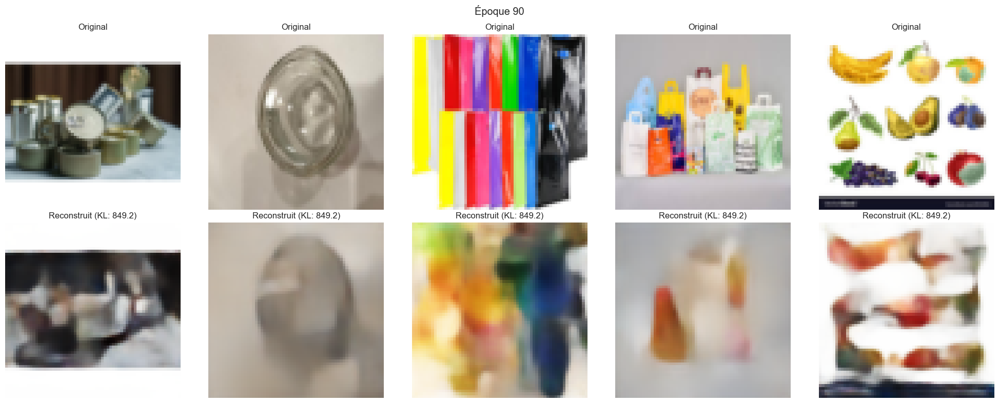

683/683 ━━━━━━━━━━━━━━━━━━━━ 456s 668ms/step - kl_loss: 849.2432 - loss: 5634.6230 - recon_loss: 5626.1265 - val_kl_loss: 836.2413 - val_loss: 5962.1484 - val_recon_loss: 5953.7866 - learning_rate: 1.5625e-05
Epoch 91/175
683/683 ━━━━━━━━━━━━━━━━━━━━ 0s 648ms/step - kl_loss: 852.1474 - loss: 5635.8901 - recon_loss: 5627.3652
Epoch 91: val_recon_loss did not improve from 5926.72656


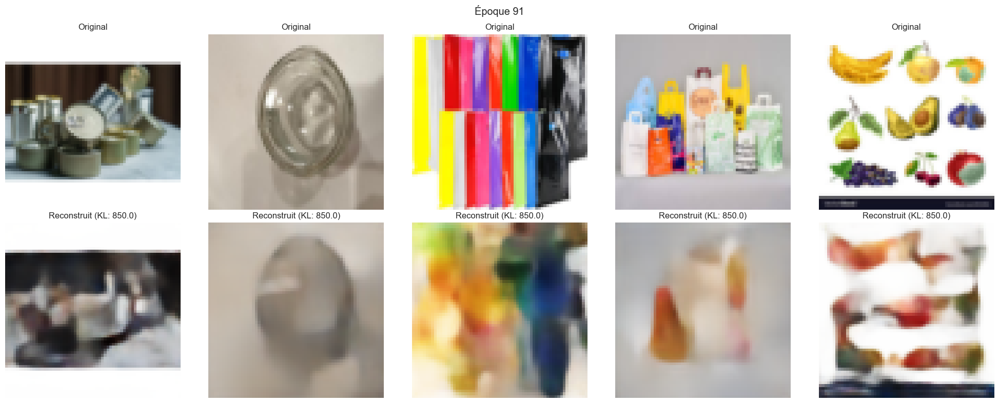

683/683 ━━━━━━━━━━━━━━━━━━━━ 460s 674ms/step - kl_loss: 849.9706 - loss: 5634.3589 - recon_loss: 5625.8555 - val_kl_loss: 839.3895 - val_loss: 5963.1323 - val_recon_loss: 5954.7393 - learning_rate: 1.5625e-05
Epoch 92/175
683/683 ━━━━━━━━━━━━━━━━━━━━ 0s 652ms/step - kl_loss: 849.8173 - loss: 5635.0298 - recon_loss: 5626.5308
Epoch 92: val_recon_loss did not improve from 5926.72656

Epoch 92: ReduceLROnPlateau reducing learning rate to 7.812500371073838e-06.


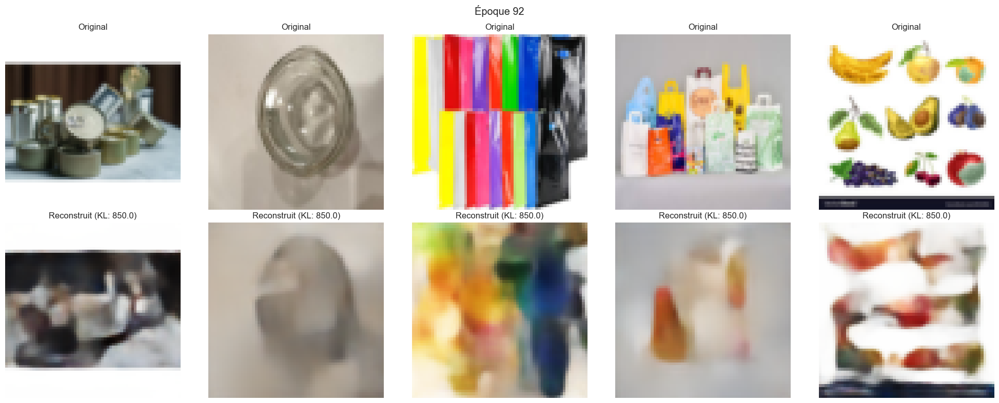

683/683 ━━━━━━━━━━━━━━━━━━━━ 462s 677ms/step - kl_loss: 849.9532 - loss: 5634.0396 - recon_loss: 5625.5366 - val_kl_loss: 838.1125 - val_loss: 5962.1914 - val_recon_loss: 5953.8096 - learning_rate: 1.5625e-05
Epoch 93/175
683/683 ━━━━━━━━━━━━━━━━━━━━ 0s 653ms/step - kl_loss: 850.9263 - loss: 5636.7656 - recon_loss: 5628.2549
Epoch 93: val_recon_loss did not improve from 5926.72656


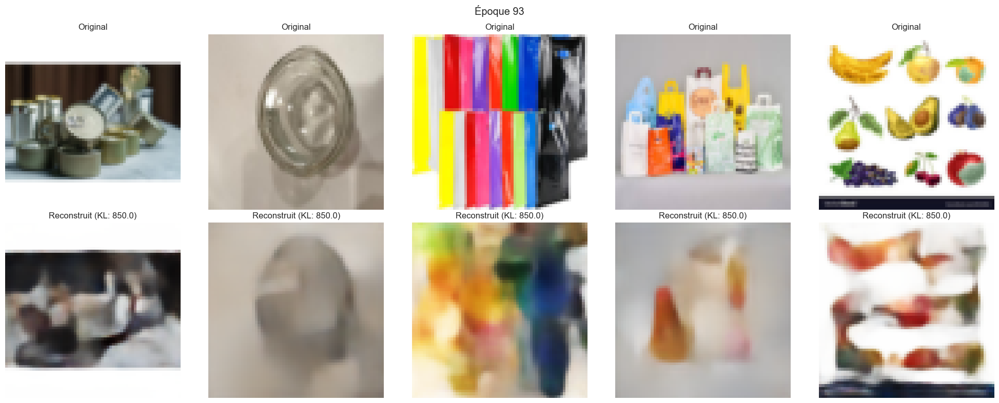

683/683 ━━━━━━━━━━━━━━━━━━━━ 463s 678ms/step - kl_loss: 849.9862 - loss: 5633.8579 - recon_loss: 5625.3560 - val_kl_loss: 839.4521 - val_loss: 5962.7505 - val_recon_loss: 5954.3569 - learning_rate: 7.8125e-06
Epoch 94/175
683/683 ━━━━━━━━━━━━━━━━━━━━ 0s 643ms/step - kl_loss: 850.1237 - loss: 5642.5981 - recon_loss: 5634.0952
Epoch 94: val_recon_loss did not improve from 5926.72656


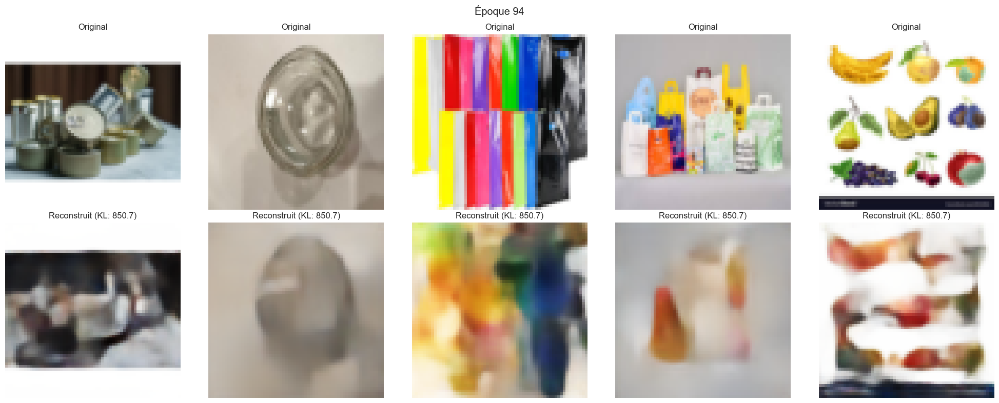

683/683 ━━━━━━━━━━━━━━━━━━━━ 496s 669ms/step - kl_loss: 850.7035 - loss: 5633.6045 - recon_loss: 5625.0928 - val_kl_loss: 839.4695 - val_loss: 5962.1094 - val_recon_loss: 5953.7148 - learning_rate: 7.8125e-06
Epoch 95/175
683/683 ━━━━━━━━━━━━━━━━━━━━ 0s 648ms/step - kl_loss: 852.3110 - loss: 5596.5991 - recon_loss: 5588.0781
Epoch 95: val_recon_loss did not improve from 5926.72656


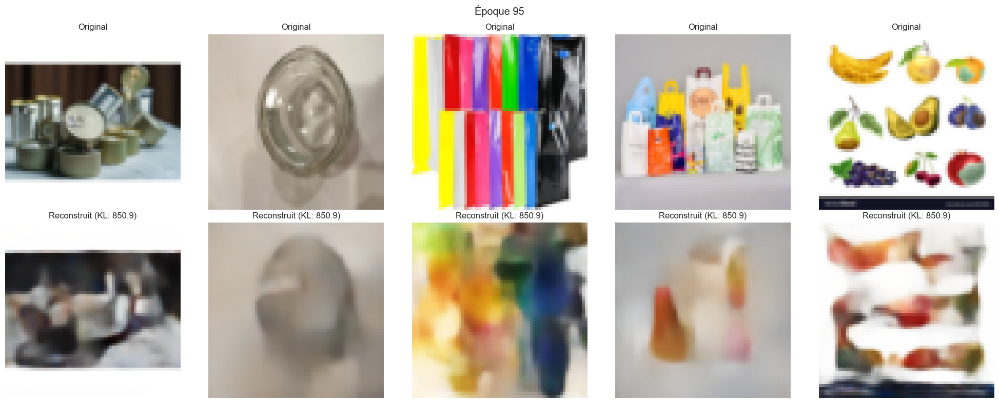

683/683 ━━━━━━━━━━━━━━━━━━━━ 460s 673ms/step - kl_loss: 850.9109 - loss: 5633.9844 - recon_loss: 5625.4775 - val_kl_loss: 838.4038 - val_loss: 5961.7041 - val_recon_loss: 5953.3193 - learning_rate: 7.8125e-06
Epoch 96/175
683/683 ━━━━━━━━━━━━━━━━━━━━ 0s 639ms/step - kl_loss: 850.0563 - loss: 5641.9111 - recon_loss: 5633.4097
Epoch 96: val_recon_loss did not improve from 5926.72656


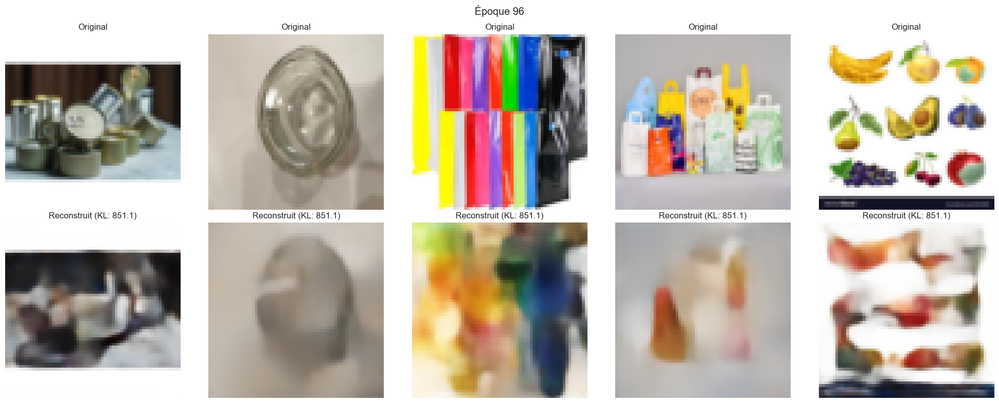

683/683 ━━━━━━━━━━━━━━━━━━━━ 496s 664ms/step - kl_loss: 851.0937 - loss: 5634.0820 - recon_loss: 5625.5703 - val_kl_loss: 839.3870 - val_loss: 5962.0591 - val_recon_loss: 5953.6670 - learning_rate: 7.8125e-06
Epoch 97/175
683/683 ━━━━━━━━━━━━━━━━━━━━ 0s 648ms/step - kl_loss: 853.0147 - loss: 5618.6187 - recon_loss: 5610.0859
Epoch 97: val_recon_loss did not improve from 5926.72656


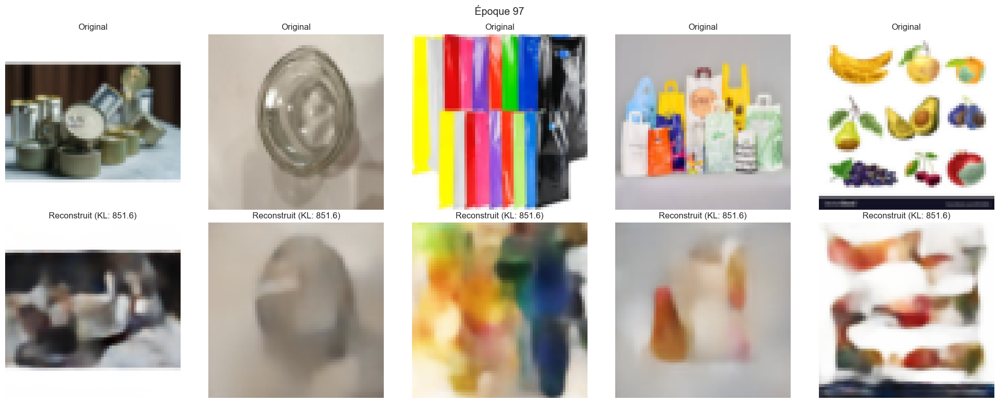

683/683 ━━━━━━━━━━━━━━━━━━━━ 459s 673ms/step - kl_loss: 851.6278 - loss: 5633.7100 - recon_loss: 5625.1909 - val_kl_loss: 840.3427 - val_loss: 5962.1094 - val_recon_loss: 5953.7070 - learning_rate: 7.8125e-06
Epoch 98/175
683/683 ━━━━━━━━━━━━━━━━━━━━ 0s 646ms/step - kl_loss: 851.1323 - loss: 5657.4429 - recon_loss: 5648.9326
Epoch 98: val_recon_loss did not improve from 5926.72656


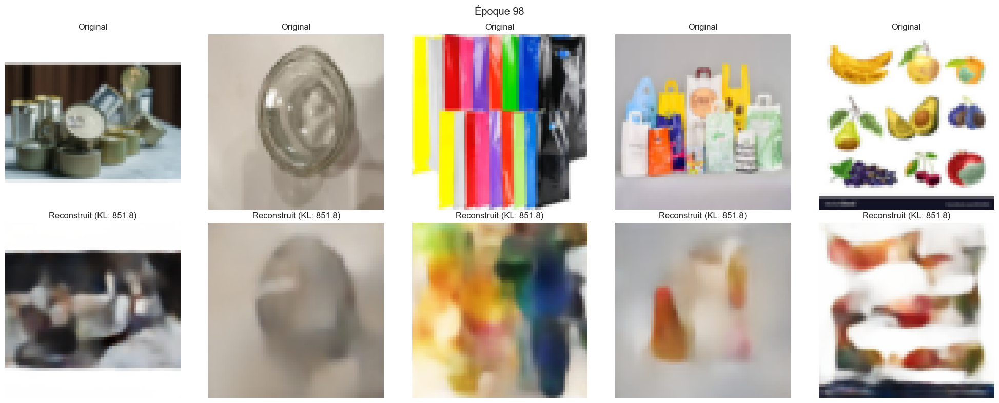

683/683 ━━━━━━━━━━━━━━━━━━━━ 458s 671ms/step - kl_loss: 851.8093 - loss: 5633.8794 - recon_loss: 5625.3672 - val_kl_loss: 839.0823 - val_loss: 5963.6904 - val_recon_loss: 5955.3008 - learning_rate: 7.8125e-06
Epoch 99/175
683/683 ━━━━━━━━━━━━━━━━━━━━ 0s 656ms/step - kl_loss: 851.8340 - loss: 5640.8433 - recon_loss: 5632.3247
Epoch 99: val_recon_loss did not improve from 5926.72656


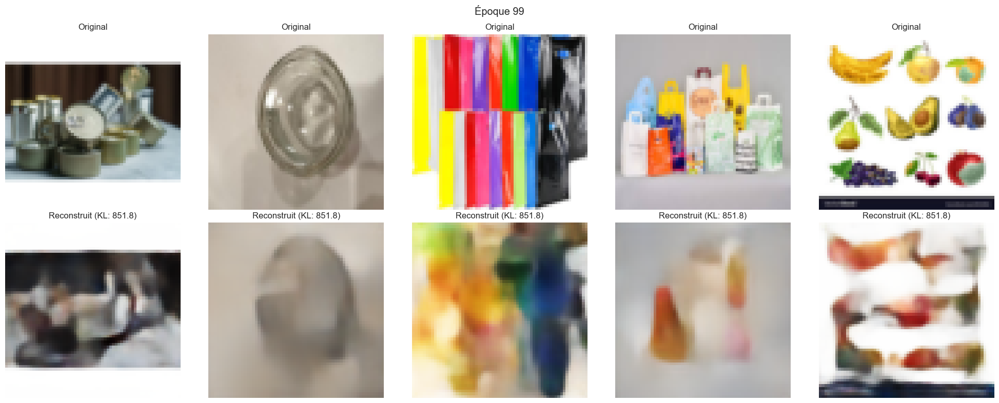

683/683 ━━━━━━━━━━━━━━━━━━━━ 465s 681ms/step - kl_loss: 851.7700 - loss: 5633.5620 - recon_loss: 5625.0425 - val_kl_loss: 840.7967 - val_loss: 5962.4546 - val_recon_loss: 5954.0464 - learning_rate: 7.8125e-06
Epoch 100/175
683/683 ━━━━━━━━━━━━━━━━━━━━ 0s 649ms/step - kl_loss: 852.1808 - loss: 5645.9424 - recon_loss: 5637.4214
Epoch 100: val_recon_loss did not improve from 5926.72656


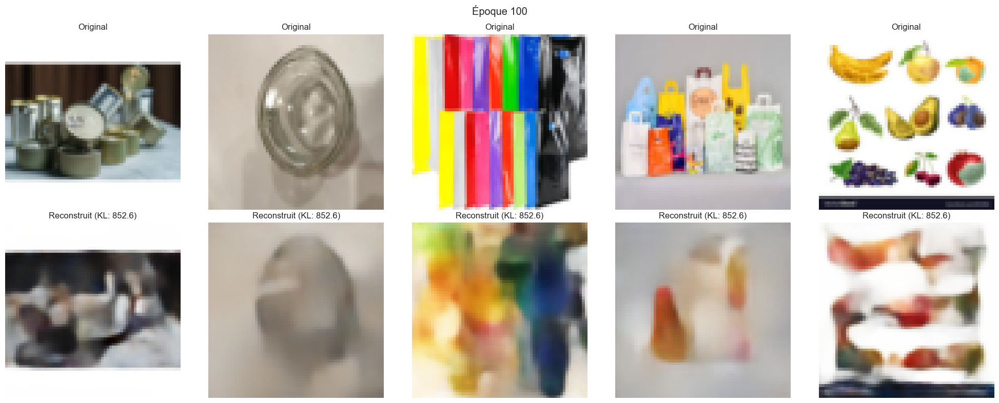

683/683 ━━━━━━━━━━━━━━━━━━━━ 461s 675ms/step - kl_loss: 852.5585 - loss: 5633.6089 - recon_loss: 5625.0859 - val_kl_loss: 840.5101 - val_loss: 5962.8135 - val_recon_loss: 5954.4082 - learning_rate: 7.8125e-06
Epoch 101/175
683/683 ━━━━━━━━━━━━━━━━━━━━ 0s 656ms/step - kl_loss: 853.8574 - loss: 5579.5728 - recon_loss: 5571.0361
Epoch 101: val_recon_loss did not improve from 5926.72656


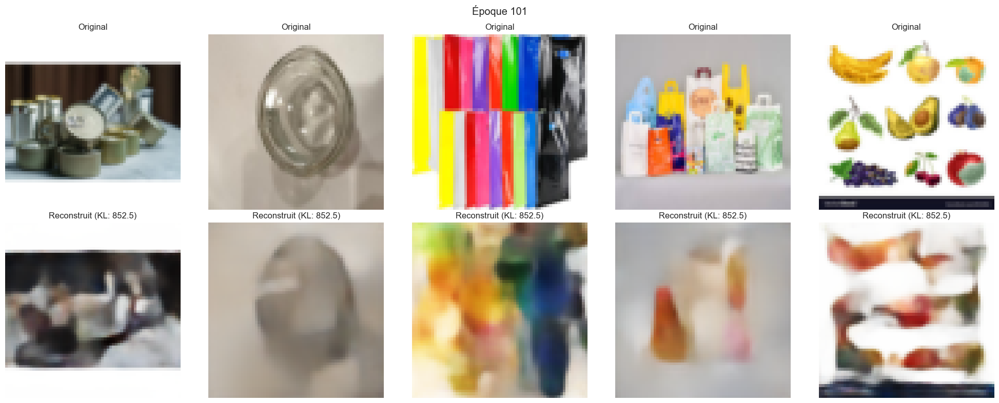

683/683 ━━━━━━━━━━━━━━━━━━━━ 465s 681ms/step - kl_loss: 852.5149 - loss: 5633.5015 - recon_loss: 5624.9800 - val_kl_loss: 840.2161 - val_loss: 5964.0088 - val_recon_loss: 5955.6079 - learning_rate: 7.8125e-06
Epoch 102/175
683/683 ━━━━━━━━━━━━━━━━━━━━ 0s 644ms/step - kl_loss: 853.0410 - loss: 5641.4771 - recon_loss: 5632.9487
Epoch 102: val_recon_loss did not improve from 5926.72656

Epoch 102: ReduceLROnPlateau reducing learning rate to 3.906250185536919e-06.


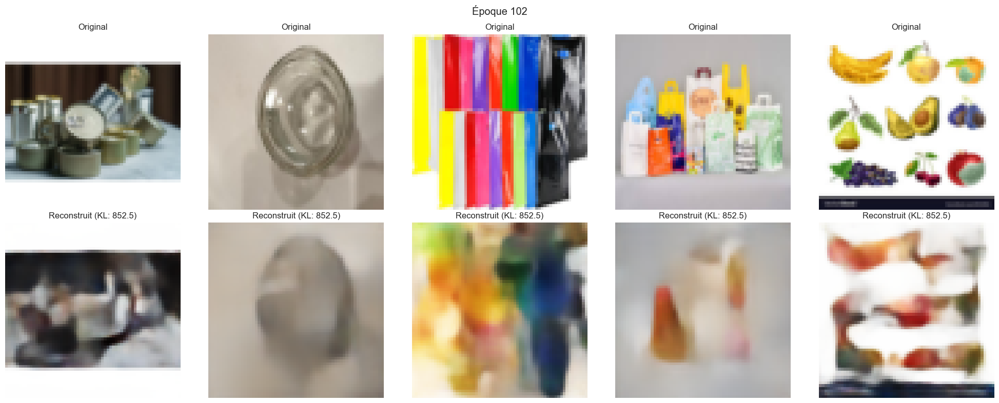

683/683 ━━━━━━━━━━━━━━━━━━━━ 494s 669ms/step - kl_loss: 852.4593 - loss: 5633.6069 - recon_loss: 5625.0874 - val_kl_loss: 841.2231 - val_loss: 5963.4941 - val_recon_loss: 5955.0825 - learning_rate: 7.8125e-06
Epoch 103/175
683/683 ━━━━━━━━━━━━━━━━━━━━ 0s 653ms/step - kl_loss: 853.8676 - loss: 5614.9482 - recon_loss: 5606.4102
Epoch 103: val_recon_loss did not improve from 5926.72656


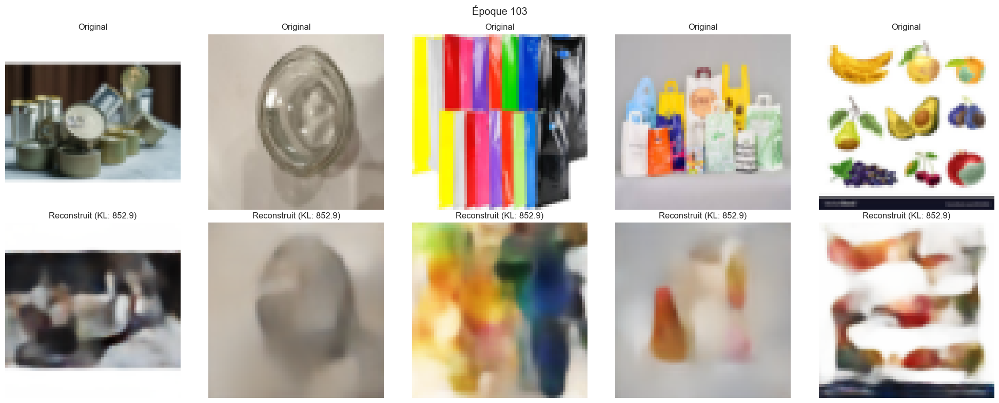

683/683 ━━━━━━━━━━━━━━━━━━━━ 463s 678ms/step - kl_loss: 852.9491 - loss: 5633.4888 - recon_loss: 5624.9604 - val_kl_loss: 841.3426 - val_loss: 5963.5269 - val_recon_loss: 5955.1128 - learning_rate: 3.9063e-06
Epoch 104/175
683/683 ━━━━━━━━━━━━━━━━━━━━ 0s 641ms/step - kl_loss: 851.3350 - loss: 5644.9150 - recon_loss: 5636.4028
Epoch 104: val_recon_loss did not improve from 5926.72656


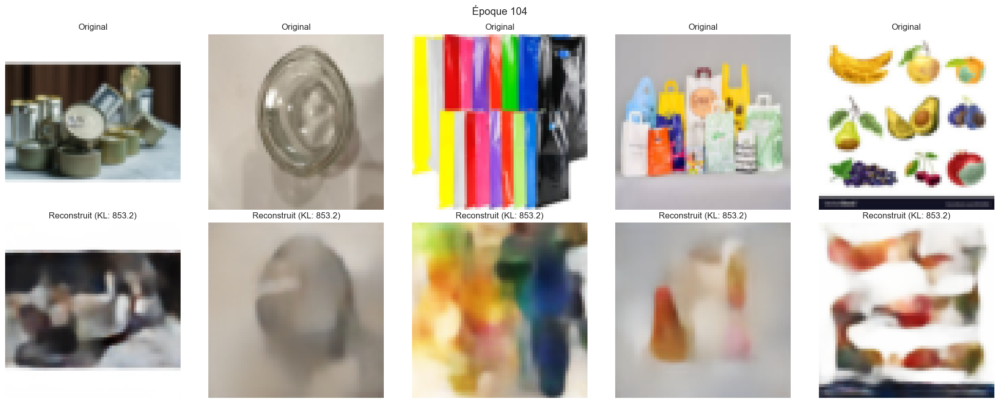

683/683 ━━━━━━━━━━━━━━━━━━━━ 493s 665ms/step - kl_loss: 853.2354 - loss: 5633.0762 - recon_loss: 5624.5459 - val_kl_loss: 841.9955 - val_loss: 5963.2124 - val_recon_loss: 5954.7905 - learning_rate: 3.9063e-06
Epoch 105/175
683/683 ━━━━━━━━━━━━━━━━━━━━ 0s 648ms/step - kl_loss: 853.4130 - loss: 5620.9707 - recon_loss: 5612.4360
Epoch 105: val_recon_loss did not improve from 5926.72656


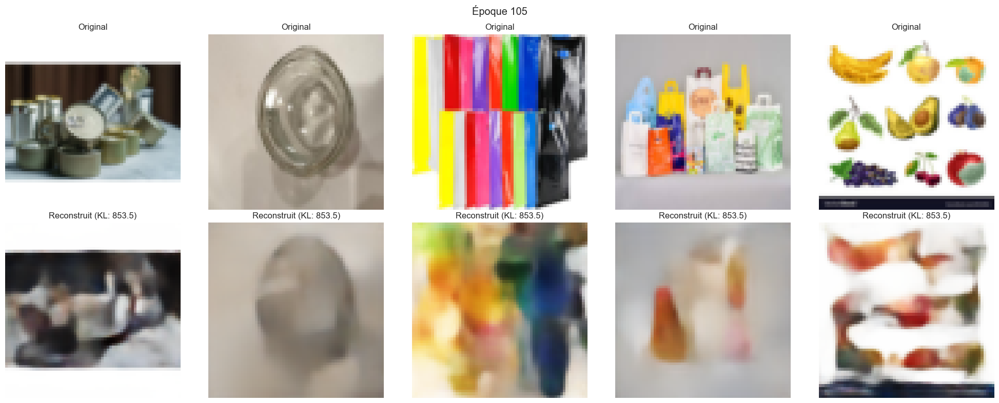

683/683 ━━━━━━━━━━━━━━━━━━━━ 460s 673ms/step - kl_loss: 853.5143 - loss: 5633.4351 - recon_loss: 5624.8989 - val_kl_loss: 842.1284 - val_loss: 5963.0850 - val_recon_loss: 5954.6626 - learning_rate: 3.9063e-06
Epoch 106/175
683/683 ━━━━━━━━━━━━━━━━━━━━ 0s 653ms/step - kl_loss: 852.1176 - loss: 5595.4570 - recon_loss: 5586.9331
Epoch 106: val_recon_loss did not improve from 5926.72656


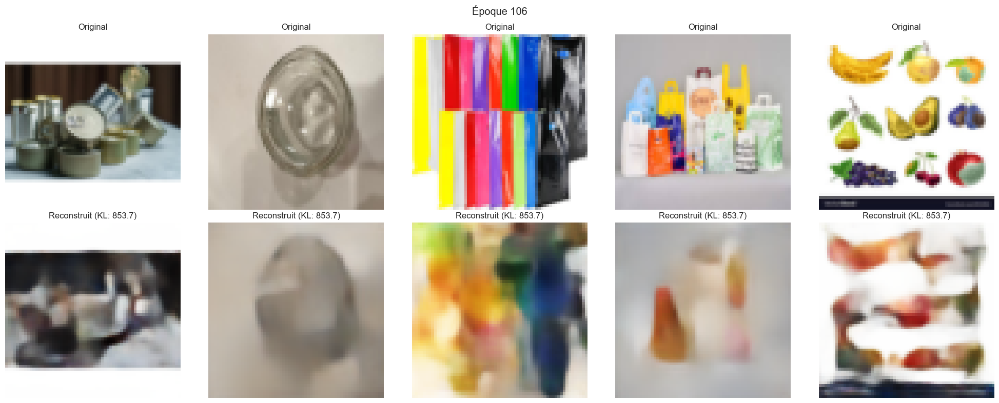

683/683 ━━━━━━━━━━━━━━━━━━━━ 463s 678ms/step - kl_loss: 853.6774 - loss: 5633.1924 - recon_loss: 5624.6509 - val_kl_loss: 842.2501 - val_loss: 5963.3535 - val_recon_loss: 5954.9312 - learning_rate: 3.9063e-06
Epoch 107/175
683/683 ━━━━━━━━━━━━━━━━━━━━ 0s 649ms/step - kl_loss: 852.7882 - loss: 5624.0933 - recon_loss: 5615.5654
Epoch 107: val_recon_loss did not improve from 5926.72656


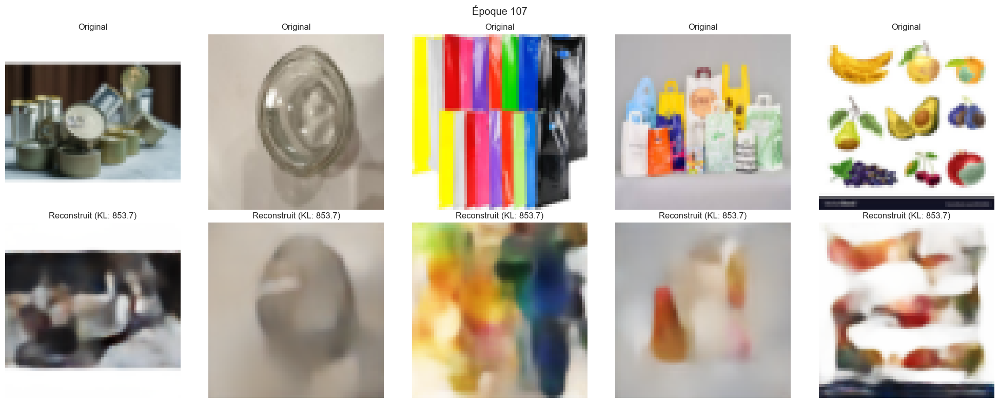

683/683 ━━━━━━━━━━━━━━━━━━━━ 461s 674ms/step - kl_loss: 853.6713 - loss: 5633.4766 - recon_loss: 5624.9429 - val_kl_loss: 841.6572 - val_loss: 5963.3672 - val_recon_loss: 5954.9521 - learning_rate: 3.9063e-06
Epoch 108/175
683/683 ━━━━━━━━━━━━━━━━━━━━ 0s 630ms/step - kl_loss: 853.7670 - loss: 5569.2344 - recon_loss: 5560.6982
Epoch 108: val_recon_loss did not improve from 5926.72656


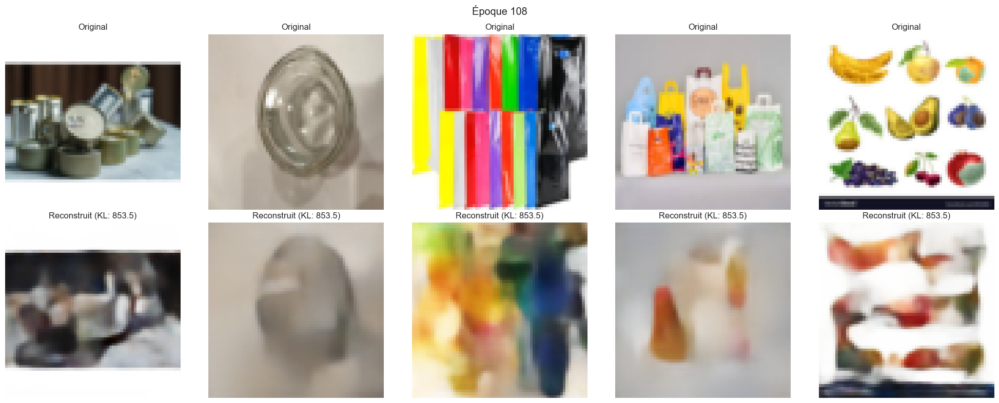

683/683 ━━━━━━━━━━━━━━━━━━━━ 489s 655ms/step - kl_loss: 853.4937 - loss: 5633.1436 - recon_loss: 5624.6108 - val_kl_loss: 841.2768 - val_loss: 5963.1860 - val_recon_loss: 5954.7734 - learning_rate: 3.9063e-06
Epoch 109/175
683/683 ━━━━━━━━━━━━━━━━━━━━ 0s 778ms/step - kl_loss: 853.4924 - loss: 5652.9844 - recon_loss: 5644.4482
Epoch 109: val_recon_loss did not improve from 5926.72656


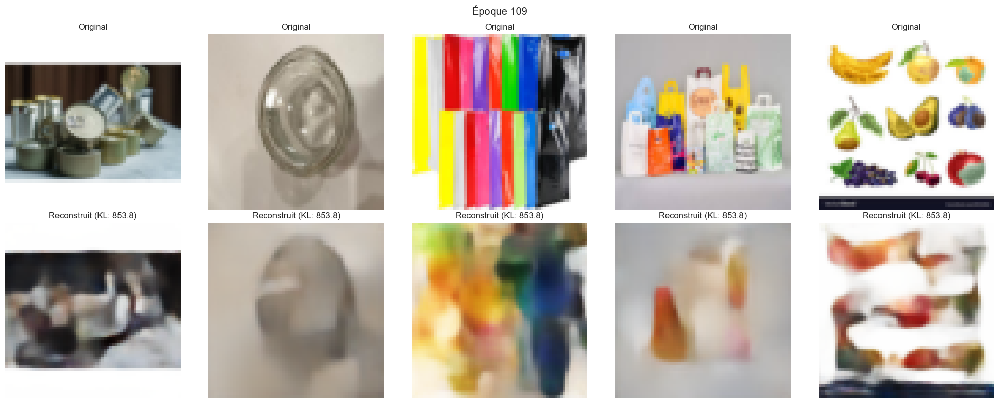

683/683 ━━━━━━━━━━━━━━━━━━━━ 620s 828ms/step - kl_loss: 853.7557 - loss: 5633.4878 - recon_loss: 5624.9502 - val_kl_loss: 842.0764 - val_loss: 5963.1685 - val_recon_loss: 5954.7471 - learning_rate: 3.9063e-06
Epoch 110/175
683/683 ━━━━━━━━━━━━━━━━━━━━ 0s 816ms/step - kl_loss: 852.8740 - loss: 5632.7812 - recon_loss: 5624.2524
Epoch 110: val_recon_loss did not improve from 5926.72656


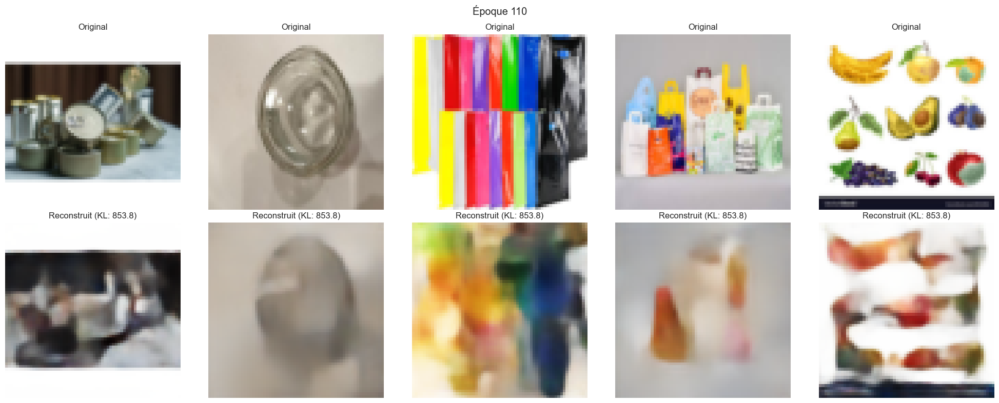

683/683 ━━━━━━━━━━━━━━━━━━━━ 582s 853ms/step - kl_loss: 853.7784 - loss: 5633.3618 - recon_loss: 5624.8252 - val_kl_loss: 841.8066 - val_loss: 5963.9692 - val_recon_loss: 5955.5503 - learning_rate: 3.9063e-06
Epoch 111/175
683/683 ━━━━━━━━━━━━━━━━━━━━ 0s 865ms/step - kl_loss: 853.7434 - loss: 5646.5952 - recon_loss: 5638.0591
Epoch 111: val_recon_loss did not improve from 5926.72656


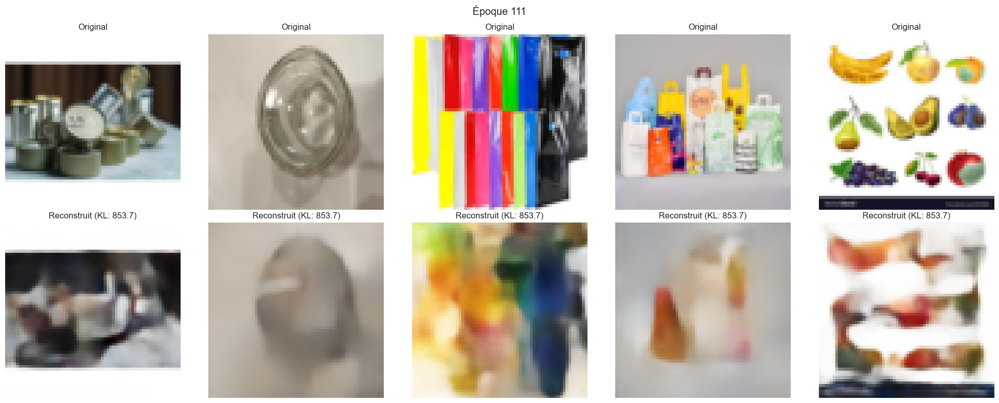

683/683 ━━━━━━━━━━━━━━━━━━━━ 617s 904ms/step - kl_loss: 853.7086 - loss: 5633.5259 - recon_loss: 5624.9897 - val_kl_loss: 842.8242 - val_loss: 5963.2329 - val_recon_loss: 5954.8037 - learning_rate: 3.9063e-06
Epoch 112/175
683/683 ━━━━━━━━━━━━━━━━━━━━ 0s 872ms/step - kl_loss: 856.4120 - loss: 5630.3696 - recon_loss: 5621.8052
Epoch 112: val_recon_loss did not improve from 5926.72656

Epoch 112: ReduceLROnPlateau reducing learning rate to 1.9531250927684596e-06.


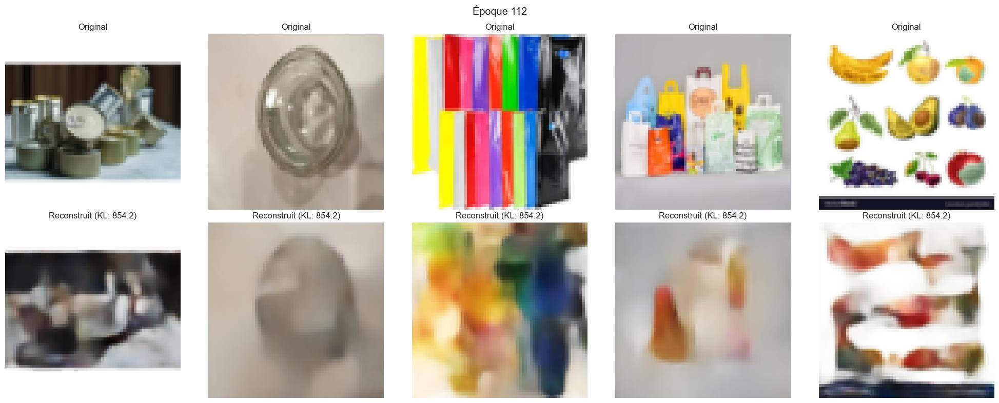

683/683 ━━━━━━━━━━━━━━━━━━━━ 617s 903ms/step - kl_loss: 854.2319 - loss: 5633.2520 - recon_loss: 5624.7114 - val_kl_loss: 841.9474 - val_loss: 5963.6602 - val_recon_loss: 5955.2402 - learning_rate: 3.9063e-06


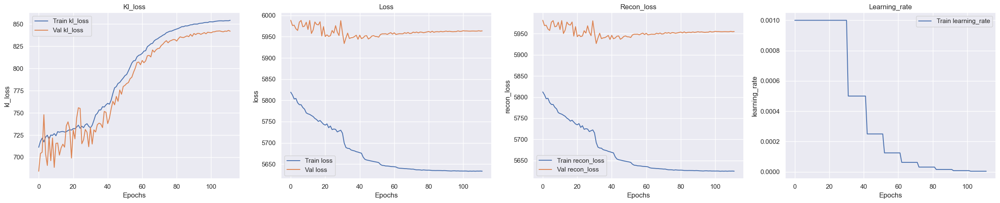

In [36]:
# Compiler et entraîner le modèle avec visualisation
import time
start_time = time.time()
history = autoencoder.train(
    x_train = X_train,
    x_val = X_test, 
    batch_size=16,
    #epochs=100,
    x_vis=X_vis,
    epochs = start_epoch + 150,
    initial_epoch=start_epoch,
    save_path=str(ANOMALY_MODELS_DIR / "model_dct_10.keras")
)
end_time = time.time()
#days, rem = divmod(elapsed, 86400)          
#hours, rem = divmod(rem, 3600)
#minutes, seconds = divmod(rem, 60)

#print(f"Temps d'entraînement : {int(days)}j {int(hours):02d}h {int(minutes):02d}m {int(seconds):02d}s")

autoencoder.save(str(ANOMALY_MODELS_DIR / "model_dct_10.keras"))
plot_result(history,name_fig="outo-loss",register=True)

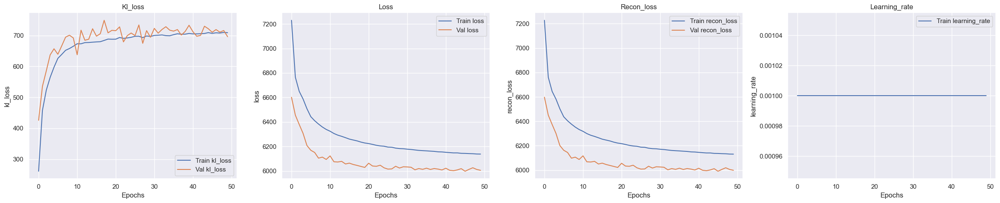

In [23]:
plot_result(history,name_fig="outo-loss",register=True)

In [ ]:
model1 = load_model(str(ANOMALY_MODELS_DIR / "model_dct_6.keras"), custom_objects={"ResidualVAE": ResidualVAE, "Sampling": Sampling})

In [ ]:
path = str(TEST_DIR / "samples" / "im1.jpg")

In [ ]:
tf.keras.utils.plot_model(model1, show_shapes=True, show_layer_names=False, dpi=120)

In [ ]:
img,_ = src.prepare_image(img_path=path,target_size=240)

In [37]:
img = X_train[1:20]

In [41]:
img.max()

np.float32(1.0)

In [38]:
encoded_imgs,g,z = autoencoder.encoder(img)

In [39]:
pred = autoencoder.decoder(z)

In [ ]:
autoencoder.save(str(ANOMALY_MODELS_DIR / "model_dct_1.keras"))

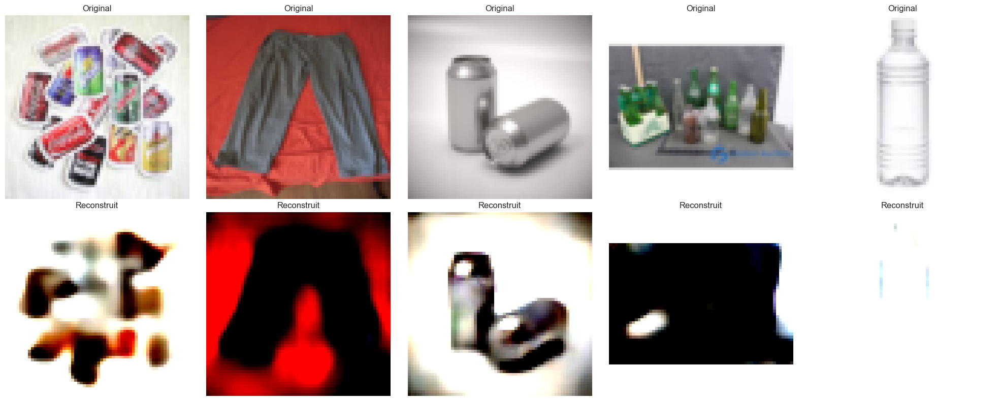

In [40]:
n = 5
plt.figure(figsize=(20, 8))
for i in range(n):
    plt.subplot(2, n, i + 1)
    plt.imshow(np.clip(img[i], 0, 1))
    plt.axis("off")
    plt.title("Original")

    plt.subplot(2, n, n + i + 1)
    plt.imshow(np.clip(pred[i], 0, 1))
    plt.axis("off")
    plt.title("Reconstruit")
plt.savefig(str(FIGURES_DIR / "test_auto.png"))
plt.tight_layout()
plt.show()


In [22]:
df_anomalie = src.Load_data.load_object(DATASET_ANOMALIES)

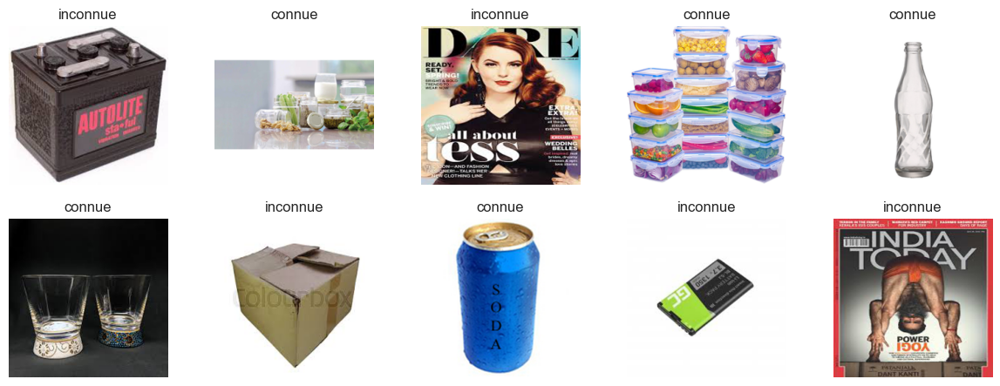

In [23]:
df_anomalie.plot(view_code=True)

In [24]:
df_anomalie.encodage()

In [29]:
df_anomalie.reshape(target_shape=(64,64,3), batch_size = 32)

Reshape en batch: 100%|██████████████████████████████████████████████████████████████| 125/125 [00:05<00:00, 21.43it/s]


In [30]:
(X_test_an, y_test_an), (_,_) = df_anomalie.create_data(test_size=0.0000000000001)

In [26]:
np.unique(y_test_an,return_counts=True)

(array([0, 1], dtype=int32), array([1999, 2000]))

In [48]:
(X_test_an, y_test_an), (_,_) = df_anomalie.create_data(test_size=0.0000000000001)

In [49]:
X_test_an = X_test_an.astype('float32') / 255.

In [45]:
encoded_imgs,g,z = model1.encoder(np.expand_dims(X_test_an[9]/255, axis = 0))
recon = model1.decoder(z)

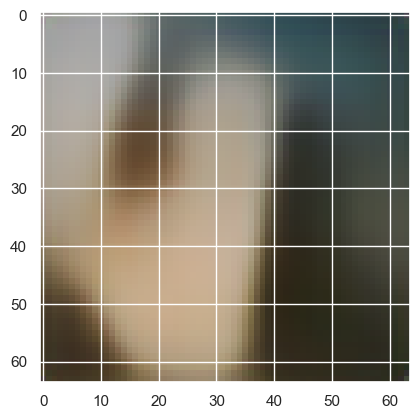

In [46]:
plt.imshow(recon[0])

In [34]:
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm
from sklearn.metrics import (
    confusion_matrix, roc_curve,
    precision_recall_curve, classification_report, roc_auc_score
)
import seaborn as sns
import pandas as pd

def detect_anomalies_complete_v2(autoencoder, x_data, y_true, thresholds, batch_size=32):
    """
    Détection d'anomalies complète avec visualisations et rapport détaillé.
    - Calcule les erreurs de reconstruction de manière itérative (optimisée pour faible RAM)
    - Évalue les performances selon plusieurs seuils
    - Trace les courbes des métriques + du nombre d’anomalies détectées
    - Affiche la matrice de confusion (en %) avec labels 'Normal' et 'Anormal'
    - Affiche un rapport global de classification
    """

    # ---------------------------
    # Étape 1 : Calcul des erreurs
    # ---------------------------
    print("Calcul des erreurs de reconstruction...")
    n = len(x_data)
    errors = []
    for i in tqdm(range(0, n, batch_size)):
        batch = x_data[i:i + batch_size]
        encoded_imgs,g,z = autoencoder.encoder(batch)
        recon = autoencoder.decoder(z)
        batch_errors = np.mean(np.square(batch - recon), axis=(1, 2, 3))
        errors.extend(batch_errors)
    errors = np.array(errors)

    # ---------------------------
    # Étape 2 : Histogramme des erreurs
    # ---------------------------
    plt.figure(figsize=(8, 5))
    plt.hist(errors[y_true == 0], bins=40, alpha=0.7, label="Normales")
    plt.hist(errors[y_true == 1], bins=40, alpha=0.7, label="Anomalies")
    plt.xlabel("Erreur de reconstruction")
    plt.ylabel("Fréquence")
    plt.title("Distribution des erreurs de reconstruction")
    plt.legend()
    plt.grid(True)
    plt.show()

    # ---------------------------
    # Étape 3 : Calcul des métriques pour chaque seuil
    # ---------------------------
    results = {}
    n_normals_detected, n_anomalies_detected = [], []

    for t in thresholds:
        y_pred = (errors > t).astype(int)
        cm = confusion_matrix(y_true, y_pred)
        tn, fp, fn, tp = cm.ravel()

        acc = (tp + tn) / (tp + tn + fp + fn + 1e-8)
        prec = tp / (tp + fp + 1e-8)
        rec = tp / (tp + fn + 1e-8)
        f1 = 2 * prec * rec / (prec + rec + 1e-8)
        results[t] = {"accuracy": acc, "precision": prec, "recall": rec, "f1": f1}

        n_normals_detected.append((y_pred == 0).sum())
        n_anomalies_detected.append((y_pred == 1).sum())

    # Convertir en DataFrame pour analyse
    df_metrics = pd.DataFrame(results).T
    df_metrics["anomalies_detected"] = n_anomalies_detected
    df_metrics["normals_detected"] = n_normals_detected

    # ---------------------------
    # Étape 4 : Tracer les métriques et détections
    # ---------------------------
    fig, axes = plt.subplots(1, 2, figsize=(16,6))

    # (a) Nombre de détections
    axes[0].plot(thresholds, df_metrics["normals_detected"], label="Normales détectées")
    axes[0].plot(thresholds, df_metrics["anomalies_detected"], label="Anomalies détectées")
    axes[0].set_title("Évolution du nombre de détections")
    axes[0].set_xlabel("Seuil d'anomalie")
    axes[0].set_ylabel("Nombre d'échantillons")
    axes[0].legend()
    axes[0].grid(True)
    
    # (b) Évolution des métriques
    axes[1].plot(thresholds, df_metrics["accuracy"], label="Exactitude")
    axes[1].plot(thresholds, df_metrics["precision"], label="Précision")
    axes[1].plot(thresholds, df_metrics["recall"], label="Rappel")
    axes[1].plot(thresholds, df_metrics["f1"], label="F1-score")
    axes[1].set_title("Évolution des métriques selon le seuil")
    axes[1].set_xlabel("Seuil d'anomalie")
    axes[1].set_ylabel("Valeur métrique")
    axes[1].legend()
    axes[1].grid(True)

    plt.savefig(str(FIGURES_DIR / "auto_metrix.png"))
    plt.tight_layout()
    plt.show()

    # ---------------------------
    # Étape 5 : Courbes ROC et PR
    # ---------------------------
    fpr, tpr, _ = roc_curve(y_true, errors)
    precision, recall, _ = precision_recall_curve(y_true, errors)
    auc_score = roc_auc_score(y_true, errors)

    plt.figure(figsize=(16, 6))
    plt.subplot(1, 2, 1)
    plt.plot(fpr, tpr, label=f"AUC = {auc_score:.3f}")
    plt.xlabel("Taux de faux positifs (FPR)")
    plt.ylabel("Taux de vrais positifs (TPR)")
    plt.title("Courbe ROC")
    plt.legend()
    plt.grid(True)

    plt.subplot(1, 2, 2)
    plt.plot(recall, precision)
    plt.xlabel("Rappel")
    plt.ylabel("Précision")
    plt.title("Courbe Précision-Rappel")
    plt.grid(True)
    plt.show()

    # ---------------------------
    # Étape 6 : Seuil optimal + rapport complet
    # ---------------------------
    best_t = df_metrics["f1"].idxmax()
    print(f"\n Seuil optimal (F1 max) = {best_t:.5f}\n")
    print("Métriques associées :")
    print(df_metrics.loc[best_t].to_string(), "\n")

    y_pred_best = (errors > best_t).astype(int)

    # Matrice de confusion (avec labels et pourcentages)
    cm_best = confusion_matrix(y_true, y_pred_best)
    cm_percent = cm_best.astype('float') / cm_best.sum(axis=1)[:, np.newaxis]

    labels = ["Normal", "Anormal"]
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm_percent, annot=True, fmt=".2%", cmap="Blues", cbar=False,
                xticklabels=labels, yticklabels=labels)
    plt.xlabel("Prédiction")
    plt.ylabel("Vérité terrain")
    plt.title("Matrice de confusion - Seuil optimal")
    plt.savefig(str(FIGURES_DIR / "matrix_auto.png"))
    plt.show()

    print("Rapport de classification :")
    print(classification_report(y_true, y_pred_best, target_names=labels, digits=3))

    return errors, df_metrics, best_t


Calcul des erreurs de reconstruction...


100%|████████████████████████████████████████████████████████████████████████████████| 250/250 [01:43<00:00,  2.41it/s]


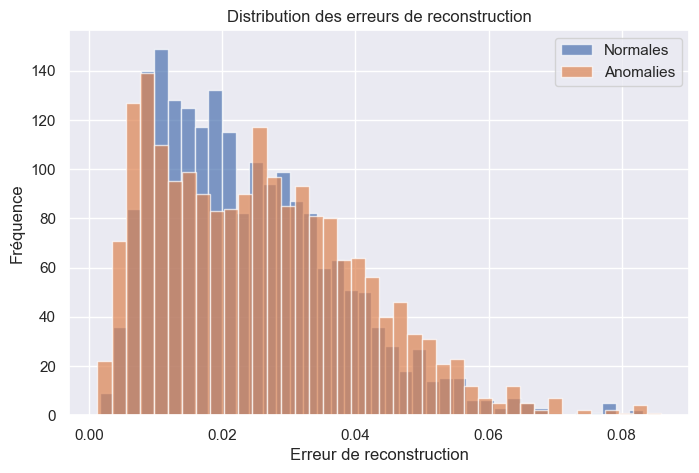

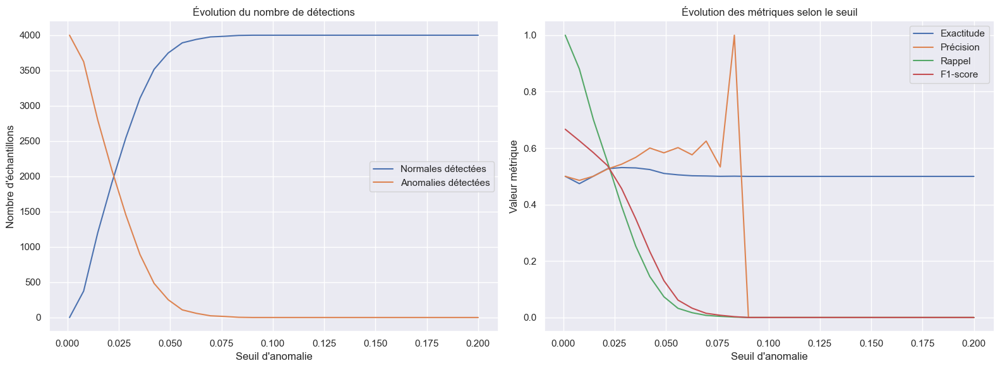

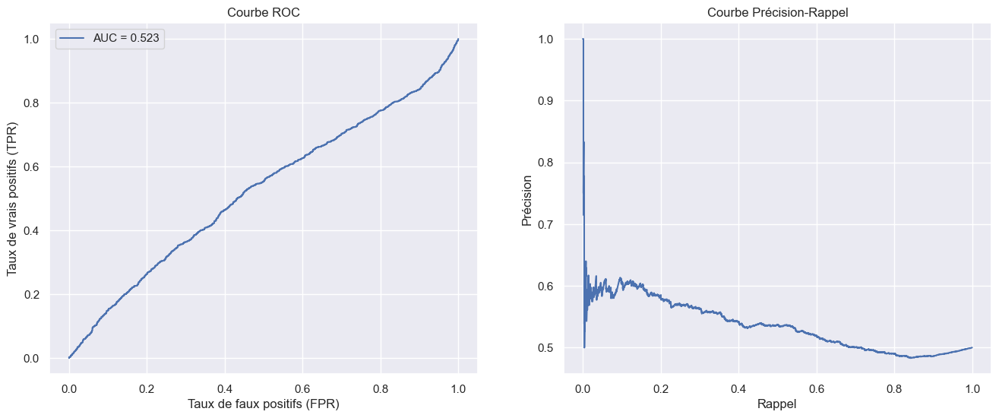


 Seuil optimal (F1 max) = 0.00100

Métriques associées :
accuracy                 0.500125
precision                0.500125
recall                   1.000000
f1                       0.666778
anomalies_detected    3999.000000
normals_detected         0.000000 



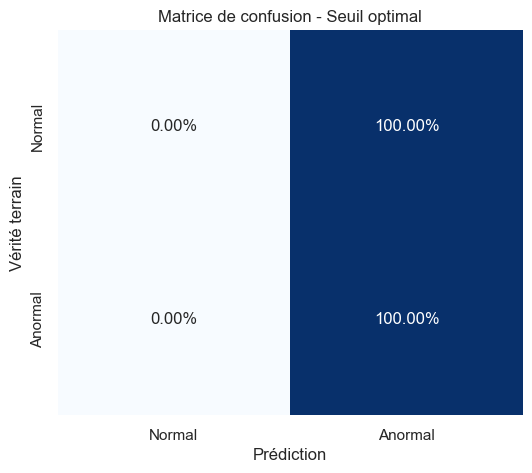

Rapport de classification :
              precision    recall  f1-score   support

      Normal      0.000     0.000     0.000      1999
     Anormal      0.500     1.000     0.667      2000

    accuracy                          0.500      3999
   macro avg      0.250     0.500     0.333      3999
weighted avg      0.250     0.500     0.333      3999



C:\Users\hp\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\hp\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\hp\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f

In [51]:
thresholds = np.linspace(0.001, 0.2, 30)
errors, df_metrics, best_t = detect_anomalies_complete_v2(model1, X_test_an, y_test_an, thresholds, batch_size=16)

In [26]:
z_mean, z_logvar, z = autoencoder.encoder.predict(np.expand_dims(X_train[9], axis = 0))
recon = autoencoder.decoder.predict(z)

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 532ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 538ms/step


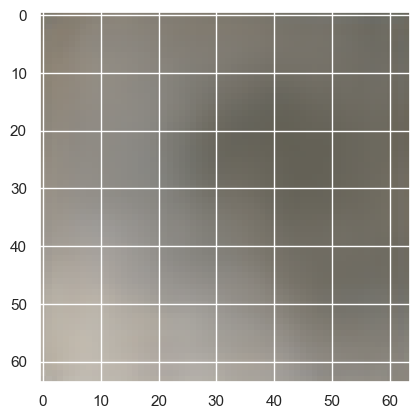

In [27]:
plt.imshow(recon[0])